# Main Paper Figures

## Figure 1

In [10]:
#!/usr/bin/env python
"""
remake_siaf_barplot_obs.py
Reads the CSV produced by siaf_obs_analysis.py and regenerates
the paired CMIP6 / Obs-era bar chart.
"""

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import os

# ============================================================
# CONFIG
# ============================================================
CSV_IN   = '/glade/work/jrotondo/ncc_paper/plots/sensitivity/siaf_pixelwise_summary.csv'
PLOT_OUT = '/glade/work/jrotondo/ncc_paper/plots/sensitivity/siaf_breakdown_barplot_obs.png'

# ============================================================
# PLOT
# ============================================================

def make_barplot(summary_df, out_path):
    """
    Grouped stacked bar chart: CERES and Kernel, paired CMIP6 vs Obs-era.
    Reads columns produced by siaf_obs_analysis.py:
      rs_method, period, pval,
      SIAF_tot_global, SIAF_ext_global, SIAF_drk_global,
      sigma2_tot_global
    """
    methods = [
        ('CERES',  'CERES APRP\n(Donohoe et al., 2020)'),
        ('Kernel', 'ERA5 Radiative Kernel\n(Huang & Huang, 2023)'),
    ]
    periods = ['CMIP6', 'Obs-era']

    COL_EXT = '#3A6BAF'   # blue  — extent
    COL_DRK = '#D95F1A'   # burnt orange — darkening
    ALPHA   = {'CMIP6': 0.55, 'Obs-era': 1.00}
    HATCHES = {'CMIP6': '////', 'Obs-era': ''}

    n = len(methods)
    x = np.arange(n)
    w = 0.32
    offsets = {'CMIP6': -(w / 2 + 0.03), 'Obs-era': (w / 2 + 0.03)}

    fig, ax = plt.subplots(figsize=(9, 6.5), dpi = 300)
    fig.patch.set_facecolor('#FAFAFA')
    ax.set_facecolor('#FAFAFA')

    legend_handles = []

    for period in periods:
        a   = ALPHA[period]
        hat = HATCHES[period]

        for i, (rs, _) in enumerate(methods):
            row = summary_df[
                (summary_df['rs_method'] == rs) &
                (summary_df['period']    == period)
            ]
            if row.empty:
                print(f'  WARNING: no row for rs_method={rs}, period={period}')
                continue

            tot_val = float(row['SIAF_tot_global'].iloc[0])
            ext_val = float(row['SIAF_ext_global'].iloc[0])
            drk_val = float(row['SIAF_drk_global'].iloc[0])
            err     = float(row['sigma2_tot_global'].iloc[0])
            xp      = x[i] + offsets[period]

            ax.bar(xp, ext_val, w,
                   color=COL_EXT, alpha=a, hatch=hat,
                   edgecolor='white', linewidth=0.5, zorder=3)
            ax.bar(xp, drk_val, w, bottom=ext_val,
                   color=COL_DRK, alpha=a, hatch=hat,
                   edgecolor='white', linewidth=0.5, zorder=3)
            ax.errorbar(xp, tot_val, yerr=err, fmt='none',
                        color='#222222', capsize=5,
                        linewidth=1.5, capthick=1.5, zorder=5)

            # Percentage labels inside bars
            ext_pct = ext_val / tot_val * 100 if tot_val > 0 else 0
            drk_pct = drk_val / tot_val * 100 if tot_val > 0 else 0
            fs = 8.5
            if ext_val > 0.004:
                ax.text(xp, ext_val / 2,
                        f'{ext_pct:.0f}%', ha='center', va='center',
                        color='white', fontsize=fs, fontweight='bold', zorder=6)
            if drk_val > 0.004:
                ax.text(xp, ext_val + drk_val / 2,
                        f'{drk_pct:.0f}%', ha='center', va='center',
                        color='white', fontsize=fs, fontweight='bold', zorder=6)

            # Period label above error bar
            plbl = 'Obs-Early\n(1982–2014)' if period == 'CMIP6' else 'Obs-Full\n(1982–2024)'
            ax.text(xp, tot_val + err + 0.001, plbl,
                    ha='center', va='bottom',
                    color='#555555', fontsize=7.5, style='italic')

        legend_handles.append(mpatches.Patch(
            facecolor=COL_EXT, alpha=a, hatch=hat, edgecolor='#555',
            label=rf"SIAF$_{{\mathregular{{area}}}}$ ({period})"))
        legend_handles.append(mpatches.Patch(
            facecolor=COL_DRK, alpha=a, hatch=hat, edgecolor='#555',
            label=rf"SIAF$_{{\mathregular{{drk}}}}$ ({period})"))

    ax.set_xticks(x)
    ax.set_xticklabels([label for _, label in methods], fontsize=11)
    ax.set_ylabel('Pan-Arctic Annual SIAF  (W m⁻² K⁻¹)', fontsize=11)
    ax.set_xlim(-0.6, n - 0.4)
    ax.set_ylim(0, ax.get_ylim()[1] * 1.18)
    ax.yaxis.grid(True, alpha=0.35, linewidth=0.8, zorder=0)
    ax.set_axisbelow(True)

    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)
    ax.spines['left'].set_color('#CCCCCC')
    ax.spines['bottom'].set_color('#CCCCCC')
    ax.tick_params(axis='both', colors='#444444')

    ax.legend(handles=legend_handles, loc='upper right', fontsize=9,
              framealpha=0.9, ncol=2, columnspacing=0.8,
              handlelength=1.4, handleheight=0.9)
    fig.tight_layout()
    fig.savefig(out_path, dpi=150, bbox_inches='tight',
                facecolor=fig.get_facecolor())
    plt.close(fig)
    print(f'Bar chart saved -> {out_path}')


if __name__ == "__main__":
    if not os.path.exists(CSV_IN):
        print(f"Error: Could not find CSV at {CSV_IN}")
    else:
        print(f"Loading {CSV_IN} ...")
        df = pd.read_csv(CSV_IN)

        print("Columns found:", df.columns.tolist())

        # Filter to p=0.05 threshold only
        df_filtered = df[df['pval'] == 0.05].copy()

        print("Rows at p=0.05:")
        print(df_filtered[['rs_method', 'period',
                            'SIAF_tot_global', 'SIAF_ext_global',
                            'SIAF_drk_global', 'sigma2_tot_global']])

        make_barplot(df_filtered, PLOT_OUT)

Loading /glade/work/jrotondo/ncc_paper/plots/sensitivity/siaf_pixelwise_summary.csv ...
Columns found: ['rs_method', 'period', 'pval', 'SIAF_tot_arctic', 'SIAF_ext_arctic', 'SIAF_drk_arctic', 'SIAF_tot_global', 'SIAF_ext_global', 'SIAF_drk_global', 'sigma2_tot_global', 'sigma2_ext_global', 'sigma2_drk_global', 'ext_pct', 'drk_pct', 'IS_ext_per_area', 'IS_drk_per_area', 'RS_ext_per_area', 'RS_drk_per_area', 'SIAF_ext_per_area', 'SIAF_drk_per_area', 'sigma2_IS_ext_pa', 'sigma2_IS_drk_pa', 'sigma2_RS_ext_pa', 'sigma2_RS_drk_pa', 'sigma2_ext_per_area', 'sigma2_drk_per_area', 'IS_tot_arctic', 'IS_ext_arctic', 'IS_drk_arctic', 'RS_arctic', 'sigma2_IS_arctic', 'sigma2_IS_ext_arctic', 'sigma2_IS_drk_arctic', 'sigma2_RS_arctic']
Rows at p=0.05:
   rs_method   period  SIAF_tot_global  SIAF_ext_global  SIAF_drk_global  \
1      CERES    CMIP6         0.224773         0.143539         0.081234   
4      CERES  Obs-era         0.182606         0.127951         0.054655   
7     Kernel    CMIP6     

# RS in first paragraph of Results

In [8]:
import numpy as np
import pandas as pd

CSV = '/glade/work/jrotondo/ncc_paper/plots/sensitivity/siaf_pixelwise_summary.csv'
df  = pd.read_csv(CSV)

sub = df[(df['period'] == 'Obs-era') & (np.isclose(df['pval'], 0.05))]

print(f"{'Method':<10}  RS_arctic (AMJJAS mean)  ±1σ")
print("-" * 45)
for _, row in sub.iterrows():
    rs   = row['RS_arctic']
    sig1 = row['sigma2_RS_arctic'] / 2      # sigma2 = 2σ → ÷2
    print(f"{row['rs_method']:<10}  {rs:.4f}                   ±{sig1:.4f}")

# Average across the two RS methods
rs_vals  = sub['RS_arctic'].values
sig2_vals = sub['sigma2_RS_arctic'].values / 2   # 1σ each

rs_mean  = rs_vals.mean()
# propagate: σ_avg = sqrt(Σσ²) / N
rs_sig   = np.sqrt((sig2_vals**2).sum()) / len(sig2_vals)
rs_spread = np.abs(rs_vals[0] - rs_vals[1]) / 2   # half inter-method range

print(f"\nAverage (CERES + Kernel):  {rs_mean:.4f} ± {rs_sig:.4f} (1σ bootstrap)")
print(f"Inter-method half-spread:  ±{rs_spread:.4f}")
print(f"Combined (quadrature):     ±{np.sqrt(rs_sig**2 + rs_spread**2):.4f}")
print(f"\nFor text (±2σ): {rs_mean:.2f} ± {2*rs_sig:.2f}")

Method      RS_arctic (AMJJAS mean)  ±1σ
---------------------------------------------
CERES       148.4042                   ±0.4649
Kernel      163.6363                   ±0.0000

Average (CERES + Kernel):  156.0203 ± 0.2324 (1σ bootstrap)
Inter-method half-spread:  ±7.6161
Combined (quadrature):     ±7.6196

For text (±2σ): 156.02 ± 0.46


## Figure 2

In [8]:
#!/usr/bin/env python
"""
plot_siaf_spatial_both.py  (updated: fontsize=18, non-overlapping colorbars)
"""

import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.gridspec as mgridspec
import os
from scipy.interpolate import griddata

matplotlib.rcParams.update({
    'font.size':          18,
    'axes.titlesize':     18,
    'axes.labelsize':     18,
    'xtick.labelsize':    18,
    'ytick.labelsize':    18,
    'legend.fontsize':    18,
    'figure.titlesize':   18,
})

try:
    import cartopy.crs as ccrs
    import cartopy.feature as cfeature
    HAS_CARTOPY = True
except ImportError:
    HAS_CARTOPY = False
    print('WARNING: cartopy not installed.')

from pyproj import Transformer

# ── CONFIG ────────────────────────────────────────────────────────────────────
OUT_DIR   = '/glade/work/jrotondo/ncc_paper/plots/sensitivity/'
NPZ_CERES = os.path.join(OUT_DIR, 'siaf_spatial_boot_ceres.npz')
NPZ_HUANG = os.path.join(OUT_DIR, 'siaf_spatial_boot_huang.npz')
PLOT_STEM = os.path.join(OUT_DIR, 'siaf_spatial_both')

PSN25_PROJ4 = ('+proj=stere +lat_0=90 +lat_ts=70 +lon_0=-45 +k=1 '
               '+x_0=0 +y_0=0 +a=6378273 +b=6356889.449 +units=m +no_defs')

ROW_DEFS = [
    ('ext', r'SIAF$_\mathregular{area}$', '#3A6BAF'),
    ('drk', r'SIAF$_\mathregular{drk}$', '#D95F1A'),
    ('tot', r'SIAF$_\mathregular{tot}$', '#6A3FA5'),
]
CMAP_VAL   = 'YlOrRd'
CMAP_SIGMA = 'Blues'

# ── LOAD ──────────────────────────────────────────────────────────────────────
print("Loading NPZ files...")
for p in [NPZ_CERES, NPZ_HUANG]:
    if not os.path.exists(p):
        raise FileNotFoundError(f"Cannot find {p}")

ceres_npz  = np.load(NPZ_CERES)
huang_npz  = np.load(NPZ_HUANG)
psn_xx     = ceres_npz['psn_xx']
psn_yy     = ceres_npz['psn_yy']
DOMAIN_PSN = ceres_npz['domain'].astype(bool)
psn_x      = psn_xx[0, :]
psn_y      = psn_yy[:, 0]

# ── REPAIR SPARSE ARTIFACTS ───────────────────────────────────────────────────
def fill_sparse_map(arr, domain_mask):
    valid = ~np.isnan(arr) & domain_mask
    if not valid.any():
        return arr
    y_v, x_v = np.where(valid)
    y_q, x_q = np.where(domain_mask)
    filled    = griddata((y_v, x_v), arr[valid], (y_q, x_q), method='nearest')
    out       = np.full_like(arr, np.nan)
    out[y_q, x_q] = filled
    return out

# ── CARTOPY / IMSHOW HELPERS ──────────────────────────────────────────────────
def make_psn_crs():
    if not HAS_CARTOPY:
        return None
    globe = ccrs.Globe(semimajor_axis=6378273., semiminor_axis=6356889.449)
    return ccrs.Stereographic(central_latitude=90., central_longitude=-45.,
                               true_scale_latitude=70., globe=globe)

PSN_CRS = make_psn_crs()

_dx = float(psn_x[1] - psn_x[0]);  _dy = float(psn_y[1] - psn_y[0])
_x0 = float(psn_x[0])  - abs(_dx) / 2
_x1 = float(psn_x[-1]) + abs(_dx) / 2
_y0 = min(float(psn_y[0]), float(psn_y[-1])) - abs(_dy) / 2
_y1 = max(float(psn_y[0]), float(psn_y[-1])) + abs(_dy) / 2
_origin = 'upper' if _dy < 0 else 'lower'

_tfm  = Transformer.from_crs('EPSG:4326', PSN25_PROJ4, always_xy=True)
_lons = np.linspace(-180, 180, 361)
_xs, _ys = _tfm.transform(_lons, np.full_like(_lons, 57.))
_rim  = max(np.abs(_xs).max(), np.abs(_ys).max()) * 1.04
_ext  = [-_rim, _rim, -_rim, _rim]

def _add_map_features(ax):
    ax.add_feature(cfeature.LAND, facecolor='#CCCCCC', zorder=6, edgecolor='none')
    ax.coastlines(resolution='50m', linewidth=0.5, color='#333333', zorder=7)
    gl = ax.gridlines(crs=ccrs.PlateCarree(), linewidth=0.35,
                      color='#AAAAAA', linestyle='--', zorder=8)
    gl.ylocator = mticker.FixedLocator([60, 70, 80])
    gl.xlocator = mticker.FixedLocator(range(-180, 181, 30))

def _make_ax(fig, gs_cell):
    if HAS_CARTOPY:
        ax = fig.add_subplot(gs_cell, projection=PSN_CRS)
        ax.set_extent(_ext, crs=PSN_CRS)
        _add_map_features(ax)
    else:
        ax = fig.add_subplot(gs_cell)
        ax.set_aspect('equal')
    return ax

def _plot_field(ax, arr, cmap, vmin, vmax):
    cmap_obj = matplotlib.colormaps[cmap].copy()
    cmap_obj.set_bad(alpha=0.0)
    disp = np.where(DOMAIN_PSN, arr, np.nan).astype(np.float32)
    if HAS_CARTOPY:
        im = matplotlib.axes.Axes.imshow(
            ax, disp, origin=_origin,
            extent=[_x0, _x1, _y0, _y1],
            cmap=cmap_obj, vmin=vmin, vmax=vmax,
            interpolation='nearest', zorder=5)
    else:
        im = ax.imshow(disp, origin=_origin, cmap=cmap_obj,
                       vmin=vmin, vmax=vmax, interpolation='nearest')
    return im

# ── FIGURE BUILDER ────────────────────────────────────────────────────────────
def make_figure(c_maps, h_maps, period, pval_str, out_path):

    vmax_val = max(
        max(np.nanpercentile(c_maps[f'mean_{t}'][DOMAIN_PSN], 98),
            np.nanpercentile(h_maps[f'mean_{t}'][DOMAIN_PSN], 98))
        for t in ('ext', 'drk', 'tot'))
    vmax_val = max(vmax_val, 0.05)

    avg_sigs = []
    for t in ('ext', 'drk', 'tot'):
        avg = np.where(DOMAIN_PSN,
                       (c_maps[f'sigma2_{t}'] + h_maps[f'sigma2_{t}']) / 2.,
                       np.nan)
        avg_sigs.append(np.nanpercentile(avg[DOMAIN_PSN], 98))
    vmax_sig = max(max(avg_sigs), 0.01)

    # Layout:  [CERES] [Huang] [pad_cb1] [cbar1] [pad_ticks] [sigma] [pad_cb2] [cbar2]
    # We add an extra padding column (index 4) to give the cbar1 tick labels room to breathe
    fig = plt.figure(figsize=(24, 20), facecolor='#F4F4F4')
    gs  = mgridspec.GridSpec(
        3, 8, figure=fig,
        left=0.05, right=0.96, top=0.93, bottom=0.03,
        hspace=0.06, wspace=0.04,
        width_ratios=[1, 1, 0.04, 0.06, 0.12, 1, 0.04, 0.06])
    #                m1 m2  pd1   cb1   pd2   m3  pd3   cb2
    # cols:          0  1   2     3     4     5   6     7

    last_im_val = last_im_sig = None

    for row, (tag, row_label, accent) in enumerate(ROW_DEFS):
        ax_c   = _make_ax(fig, gs[row, 0])
        ax_h   = _make_ax(fig, gs[row, 1])
        ax_sig = _make_ax(fig, gs[row, 5])  # Shifted to col 5

        avg_sig = np.where(
            DOMAIN_PSN,
            (c_maps[f'sigma2_{tag}'] + h_maps[f'sigma2_{tag}']) / 2.,
            np.nan).astype(np.float32)

        last_im_val = _plot_field(ax_c,   c_maps[f'mean_{tag}'], CMAP_VAL,   0, vmax_val)
        _           = _plot_field(ax_h,   h_maps[f'mean_{tag}'], CMAP_VAL,   0, vmax_val)
        last_im_sig = _plot_field(ax_sig, avg_sig,               CMAP_SIGMA, 0, vmax_sig)

        ax_c.text(-0.11, 0.5, row_label,
                  transform=ax_c.transAxes,
                  fontsize=18, fontweight='bold', color=accent,
                  va='center', ha='right',
                  rotation=90, rotation_mode='anchor')

        if row == 0:
            ax_c.set_title('CERES APRP\n(Donohoe et al., 2020)',
                           fontsize=18, fontweight='bold', pad=10)
            ax_h.set_title('ERA5 Radiative Kernel\n(Huang & Huang, 2023)',
                           fontsize=18, fontweight='bold', pad=10)
            ax_sig.set_title('Avg 2σ bootstrap\nuncertainty',
                             fontsize=18, fontweight='bold', pad=10)

    # Colorbars mapped to the correct columns
    cb_val = fig.colorbar(last_im_val, cax=fig.add_subplot(gs[:, 3]))
    cb_sig = fig.colorbar(last_im_sig, cax=fig.add_subplot(gs[:, 7])) # Shifted to col 7
    cb_val.set_label('W m⁻² K⁻¹', fontsize=18, labelpad=10)
    cb_sig.set_label('W m⁻² K⁻¹', fontsize=18, labelpad=10)
    cb_val.ax.tick_params(labelsize=18)
    cb_sig.ax.tick_params(labelsize=18)

    clean_pval = pval_str.lstrip('0') or '0'
    '''fig.suptitle(
        f'SIAF Spatial Maps  |  {period}  |  p < 0.{clean_pval}\n'
        'Left: CERES     Centre: ERA5 Kernel     '
        'Right: Avg 2σ = (σ_CERES + σ_Huang) / 2',
        fontsize=18, fontweight='bold', y=0.965)'''

    fig.savefig(out_path, dpi=160, bbox_inches='tight',
                facecolor=fig.get_facecolor())
    plt.close(fig)
    print(f'  Saved → {out_path}')

# ── DISCOVER PERIODS / PVALS AND PLOT ─────────────────────────────────────────
prefixes = set()
for key in ceres_npz.files:
    if '_mean_tot' in key:
        prefixes.add(key.replace('_mean_tot', ''))

print(f"\nFound {len(prefixes)} period/pval combination(s).")

for prefix in sorted(prefixes):
    parts  = prefix.split('_')
    period = parts[0]
    pval_s = parts[1]

    c_maps = {}
    h_maps = {}
    for tag in ('tot', 'ext', 'drk'):
        c_maps[f'mean_{tag}']   = fill_sparse_map(
            ceres_npz[f'{prefix}_mean_{tag}'],   DOMAIN_PSN)
        c_maps[f'sigma2_{tag}'] = fill_sparse_map(
            ceres_npz[f'{prefix}_sigma2_{tag}'], DOMAIN_PSN)
        h_maps[f'mean_{tag}']   = fill_sparse_map(
            huang_npz[f'{prefix}_mean_{tag}'],   DOMAIN_PSN)
        h_maps[f'sigma2_{tag}'] = fill_sparse_map(
            huang_npz[f'{prefix}_sigma2_{tag}'], DOMAIN_PSN)

    make_figure(c_maps, h_maps, period, pval_s,
                f'{PLOT_STEM}_{period}_p{pval_s}.png')

print("Done!")

Loading NPZ files...

Found 2 period/pval combination(s).
  Saved → /glade/work/jrotondo/ncc_paper/plots/sensitivity/siaf_spatial_both_CMIP6_p005.png
  Saved → /glade/work/jrotondo/ncc_paper/plots/sensitivity/siaf_spatial_both_Obs-era_p005.png
Done!


In [11]:
#!/usr/bin/env python
"""
plot_siaf_spatial_both.py  (updated: fontsize=18, non-overlapping colorbars, 0=white)
"""

import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.gridspec as mgridspec
import os
from scipy.interpolate import griddata

matplotlib.rcParams.update({
    'font.size':          18,
    'axes.titlesize':     18,
    'axes.labelsize':     18,
    'xtick.labelsize':    18,
    'ytick.labelsize':    18,
    'legend.fontsize':    18,
    'figure.titlesize':   18,
})

try:
    import cartopy.crs as ccrs
    import cartopy.feature as cfeature
    HAS_CARTOPY = True
except ImportError:
    HAS_CARTOPY = False
    print('WARNING: cartopy not installed.')

from pyproj import Transformer

# ── CONFIG ────────────────────────────────────────────────────────────────────
OUT_DIR   = '/glade/work/jrotondo/ncc_paper/plots/sensitivity/'
NPZ_CERES = os.path.join(OUT_DIR, 'siaf_spatial_boot_ceres.npz')
NPZ_HUANG = os.path.join(OUT_DIR, 'siaf_spatial_boot_huang.npz')
PLOT_STEM = os.path.join(OUT_DIR, 'siaf_spatial_both')

PSN25_PROJ4 = ('+proj=stere +lat_0=90 +lat_ts=70 +lon_0=-45 +k=1 '
               '+x_0=0 +y_0=0 +a=6378273 +b=6356889.449 +units=m +no_defs')

ROW_DEFS = [
    ('ext', r'SIAF$_\mathregular{area}$', '#3A6BAF'),
    ('drk', r'SIAF$_\mathregular{drk}$', '#D95F1A'),
    ('tot', r'SIAF$_\mathregular{tot}$', '#6A3FA5'),
]
CMAP_VAL   = 'YlOrRd'
CMAP_SIGMA = 'Blues'

# ── LOAD ──────────────────────────────────────────────────────────────────────
print("Loading NPZ files...")
for p in [NPZ_CERES, NPZ_HUANG]:
    if not os.path.exists(p):
        raise FileNotFoundError(f"Cannot find {p}")

ceres_npz  = np.load(NPZ_CERES)
huang_npz  = np.load(NPZ_HUANG)
psn_xx     = ceres_npz['psn_xx']
psn_yy     = ceres_npz['psn_yy']
DOMAIN_PSN = ceres_npz['domain'].astype(bool)
psn_x      = psn_xx[0, :]
psn_y      = psn_yy[:, 0]

# ── REPAIR SPARSE ARTIFACTS ───────────────────────────────────────────────────
def fill_sparse_map(arr, domain_mask):
    valid = ~np.isnan(arr) & domain_mask
    if not valid.any():
        return arr
    y_v, x_v = np.where(valid)
    y_q, x_q = np.where(domain_mask)
    filled    = griddata((y_v, x_v), arr[valid], (y_q, x_q), method='nearest')
    out       = np.full_like(arr, np.nan)
    out[y_q, x_q] = filled
    return out

# ── CARTOPY / IMSHOW HELPERS ──────────────────────────────────────────────────
def make_psn_crs():
    if not HAS_CARTOPY:
        return None
    globe = ccrs.Globe(semimajor_axis=6378273., semiminor_axis=6356889.449)
    return ccrs.Stereographic(central_latitude=90., central_longitude=-45.,
                               true_scale_latitude=70., globe=globe)

PSN_CRS = make_psn_crs()

_dx = float(psn_x[1] - psn_x[0]);  _dy = float(psn_y[1] - psn_y[0])
_x0 = float(psn_x[0])  - abs(_dx) / 2
_x1 = float(psn_x[-1]) + abs(_dx) / 2
_y0 = min(float(psn_y[0]), float(psn_y[-1])) - abs(_dy) / 2
_y1 = max(float(psn_y[0]), float(psn_y[-1])) + abs(_dy) / 2
_origin = 'upper' if _dy < 0 else 'lower'

_tfm  = Transformer.from_crs('EPSG:4326', PSN25_PROJ4, always_xy=True)
_lons = np.linspace(-180, 180, 361)
_xs, _ys = _tfm.transform(_lons, np.full_like(_lons, 57.))
_rim  = max(np.abs(_xs).max(), np.abs(_ys).max()) * 1.04
_ext  = [-_rim, _rim, -_rim, _rim]

def _add_map_features(ax):
    ax.add_feature(cfeature.LAND, facecolor='#CCCCCC', zorder=6, edgecolor='none')
    ax.coastlines(resolution='50m', linewidth=0.5, color='#333333', zorder=7)
    gl = ax.gridlines(crs=ccrs.PlateCarree(), linewidth=0.35,
                      color='#AAAAAA', linestyle='--', zorder=8)
    gl.ylocator = mticker.FixedLocator([60, 70, 80])
    gl.xlocator = mticker.FixedLocator(range(-180, 181, 30))

def _make_ax(fig, gs_cell):
    if HAS_CARTOPY:
        ax = fig.add_subplot(gs_cell, projection=PSN_CRS)
        ax.set_extent(_ext, crs=PSN_CRS)
        _add_map_features(ax)
    else:
        ax = fig.add_subplot(gs_cell)
        ax.set_aspect('equal')
    return ax

def _plot_field(ax, arr, cmap, vmin, vmax):
    cmap_obj = matplotlib.colormaps[cmap].copy()
    cmap_obj.set_bad(alpha=0.0)
    cmap_obj.set_under('white')  # anything below vmin (i.e. ~0) renders pure white
    disp = np.where(DOMAIN_PSN, arr, np.nan).astype(np.float32)

    # Nudge vmin just above the true lower bound so exact 0s fall into
    # "under" territory and get the white set_under color, rather than
    # whatever off-white/tinted color the colormap itself starts on.
    eps = max((vmax - vmin) * 1e-4, 1e-8)
    plot_vmin = vmin + eps

    if HAS_CARTOPY:
        im = matplotlib.axes.Axes.imshow(
            ax, disp, origin=_origin,
            extent=[_x0, _x1, _y0, _y1],
            cmap=cmap_obj, vmin=plot_vmin, vmax=vmax,
            interpolation='nearest', zorder=5)
    else:
        im = ax.imshow(disp, origin=_origin, cmap=cmap_obj,
                       vmin=plot_vmin, vmax=vmax, interpolation='nearest')
    return im

# ── FIGURE BUILDER ────────────────────────────────────────────────────────────
def make_figure(c_maps, h_maps, period, pval_str, out_path):

    vmax_val = max(
        max(np.nanpercentile(c_maps[f'mean_{t}'][DOMAIN_PSN], 98),
            np.nanpercentile(h_maps[f'mean_{t}'][DOMAIN_PSN], 98))
        for t in ('ext', 'drk', 'tot'))
    vmax_val = max(vmax_val, 0.05)

    avg_sigs = []
    for t in ('ext', 'drk', 'tot'):
        avg = np.where(DOMAIN_PSN,
                       (c_maps[f'sigma2_{t}'] + h_maps[f'sigma2_{t}']) / 2.,
                       np.nan)
        avg_sigs.append(np.nanpercentile(avg[DOMAIN_PSN], 98))
    vmax_sig = max(max(avg_sigs), 0.01)

    # Layout:  [CERES] [Huang] [pad_cb1] [cbar1] [pad_ticks] [sigma] [pad_cb2] [cbar2]
    # We add an extra padding column (index 4) to give the cbar1 tick labels room to breathe
    fig = plt.figure(figsize=(24, 20), facecolor='#F4F4F4')
    gs  = mgridspec.GridSpec(
        3, 8, figure=fig,
        left=0.05, right=0.96, top=0.93, bottom=0.03,
        hspace=0.06, wspace=0.04,
        width_ratios=[1, 1, 0.04, 0.06, 0.12, 1, 0.04, 0.06])
    #                m1 m2  pd1   cb1   pd2   m3  pd3   cb2
    # cols:          0  1   2     3     4     5   6     7

    last_im_val = last_im_sig = None

    for row, (tag, row_label, accent) in enumerate(ROW_DEFS):
        ax_c   = _make_ax(fig, gs[row, 0])
        ax_h   = _make_ax(fig, gs[row, 1])
        ax_sig = _make_ax(fig, gs[row, 5])  # Shifted to col 5

        avg_sig = np.where(
            DOMAIN_PSN,
            (c_maps[f'sigma2_{tag}'] + h_maps[f'sigma2_{tag}']) / 2.,
            np.nan).astype(np.float32)

        last_im_val = _plot_field(ax_c,   c_maps[f'mean_{tag}'], CMAP_VAL,   0, vmax_val)
        _           = _plot_field(ax_h,   h_maps[f'mean_{tag}'], CMAP_VAL,   0, vmax_val)
        last_im_sig = _plot_field(ax_sig, avg_sig,               CMAP_SIGMA, 0, vmax_sig)

        ax_c.text(-0.11, 0.5, row_label,
                  transform=ax_c.transAxes,
                  fontsize=18, fontweight='bold', color=accent,
                  va='center', ha='right',
                  rotation=90, rotation_mode='anchor')

        if row == 0:
            ax_c.set_title('CERES APRP\n(Donohoe et al., 2020)',
                           fontsize=18, fontweight='bold', pad=10)
            ax_h.set_title('ERA5 Radiative Kernel\n(Huang & Huang, 2023)',
                           fontsize=18, fontweight='bold', pad=10)
            ax_sig.set_title('Avg 2σ bootstrap\nuncertainty',
                             fontsize=18, fontweight='bold', pad=10)

    # Colorbars mapped to the correct columns
    cb_val = fig.colorbar(last_im_val, cax=fig.add_subplot(gs[:, 3]))
    cb_sig = fig.colorbar(last_im_sig, cax=fig.add_subplot(gs[:, 7])) # Shifted to col 7
    cb_val.set_label('W m⁻² K⁻¹', fontsize=18, labelpad=10)
    cb_sig.set_label('W m⁻² K⁻¹', fontsize=18, labelpad=10)
    cb_val.ax.tick_params(labelsize=18)
    cb_sig.ax.tick_params(labelsize=18)

    clean_pval = pval_str.lstrip('0') or '0'
    '''fig.suptitle(
        f'SIAF Spatial Maps  |  {period}  |  p < 0.{clean_pval}\n'
        'Left: CERES     Centre: ERA5 Kernel     '
        'Right: Avg 2σ = (σ_CERES + σ_Huang) / 2',
        fontsize=18, fontweight='bold', y=0.965)'''

    fig.savefig(out_path, dpi=160, bbox_inches='tight',
                facecolor=fig.get_facecolor())
    plt.close(fig)
    print(f'  Saved → {out_path}')

# ── DISCOVER PERIODS / PVALS AND PLOT ─────────────────────────────────────────
prefixes = set()
for key in ceres_npz.files:
    if '_mean_tot' in key:
        prefixes.add(key.replace('_mean_tot', ''))

print(f"\nFound {len(prefixes)} period/pval combination(s).")

for prefix in sorted(prefixes):
    parts  = prefix.split('_')
    period = parts[0]
    pval_s = parts[1]

    c_maps = {}
    h_maps = {}
    for tag in ('tot', 'ext', 'drk'):
        c_maps[f'mean_{tag}']   = fill_sparse_map(
            ceres_npz[f'{prefix}_mean_{tag}'],   DOMAIN_PSN)
        c_maps[f'sigma2_{tag}'] = fill_sparse_map(
            ceres_npz[f'{prefix}_sigma2_{tag}'], DOMAIN_PSN)
        h_maps[f'mean_{tag}']   = fill_sparse_map(
            huang_npz[f'{prefix}_mean_{tag}'],   DOMAIN_PSN)
        h_maps[f'sigma2_{tag}'] = fill_sparse_map(
            huang_npz[f'{prefix}_sigma2_{tag}'], DOMAIN_PSN)

    make_figure(c_maps, h_maps, period, pval_s,
                f'{PLOT_STEM}_{period}_p{pval_s}.png')

print("Done!")

Loading NPZ files...

Found 2 period/pval combination(s).
  Saved → /glade/work/jrotondo/ncc_paper/plots/sensitivity/siaf_spatial_both_CMIP6_p005.png
  Saved → /glade/work/jrotondo/ncc_paper/plots/sensitivity/siaf_spatial_both_Obs-era_p005.png
Done!


## Figure 3

-> /glade/work/jrotondo/ncc_paper/plots/cmip6_pistone_only/f03_family_local.png
   local MMM: area=22.45  drk=9.89  | obs area=32.82 drk=13.93 W m-2 K-1


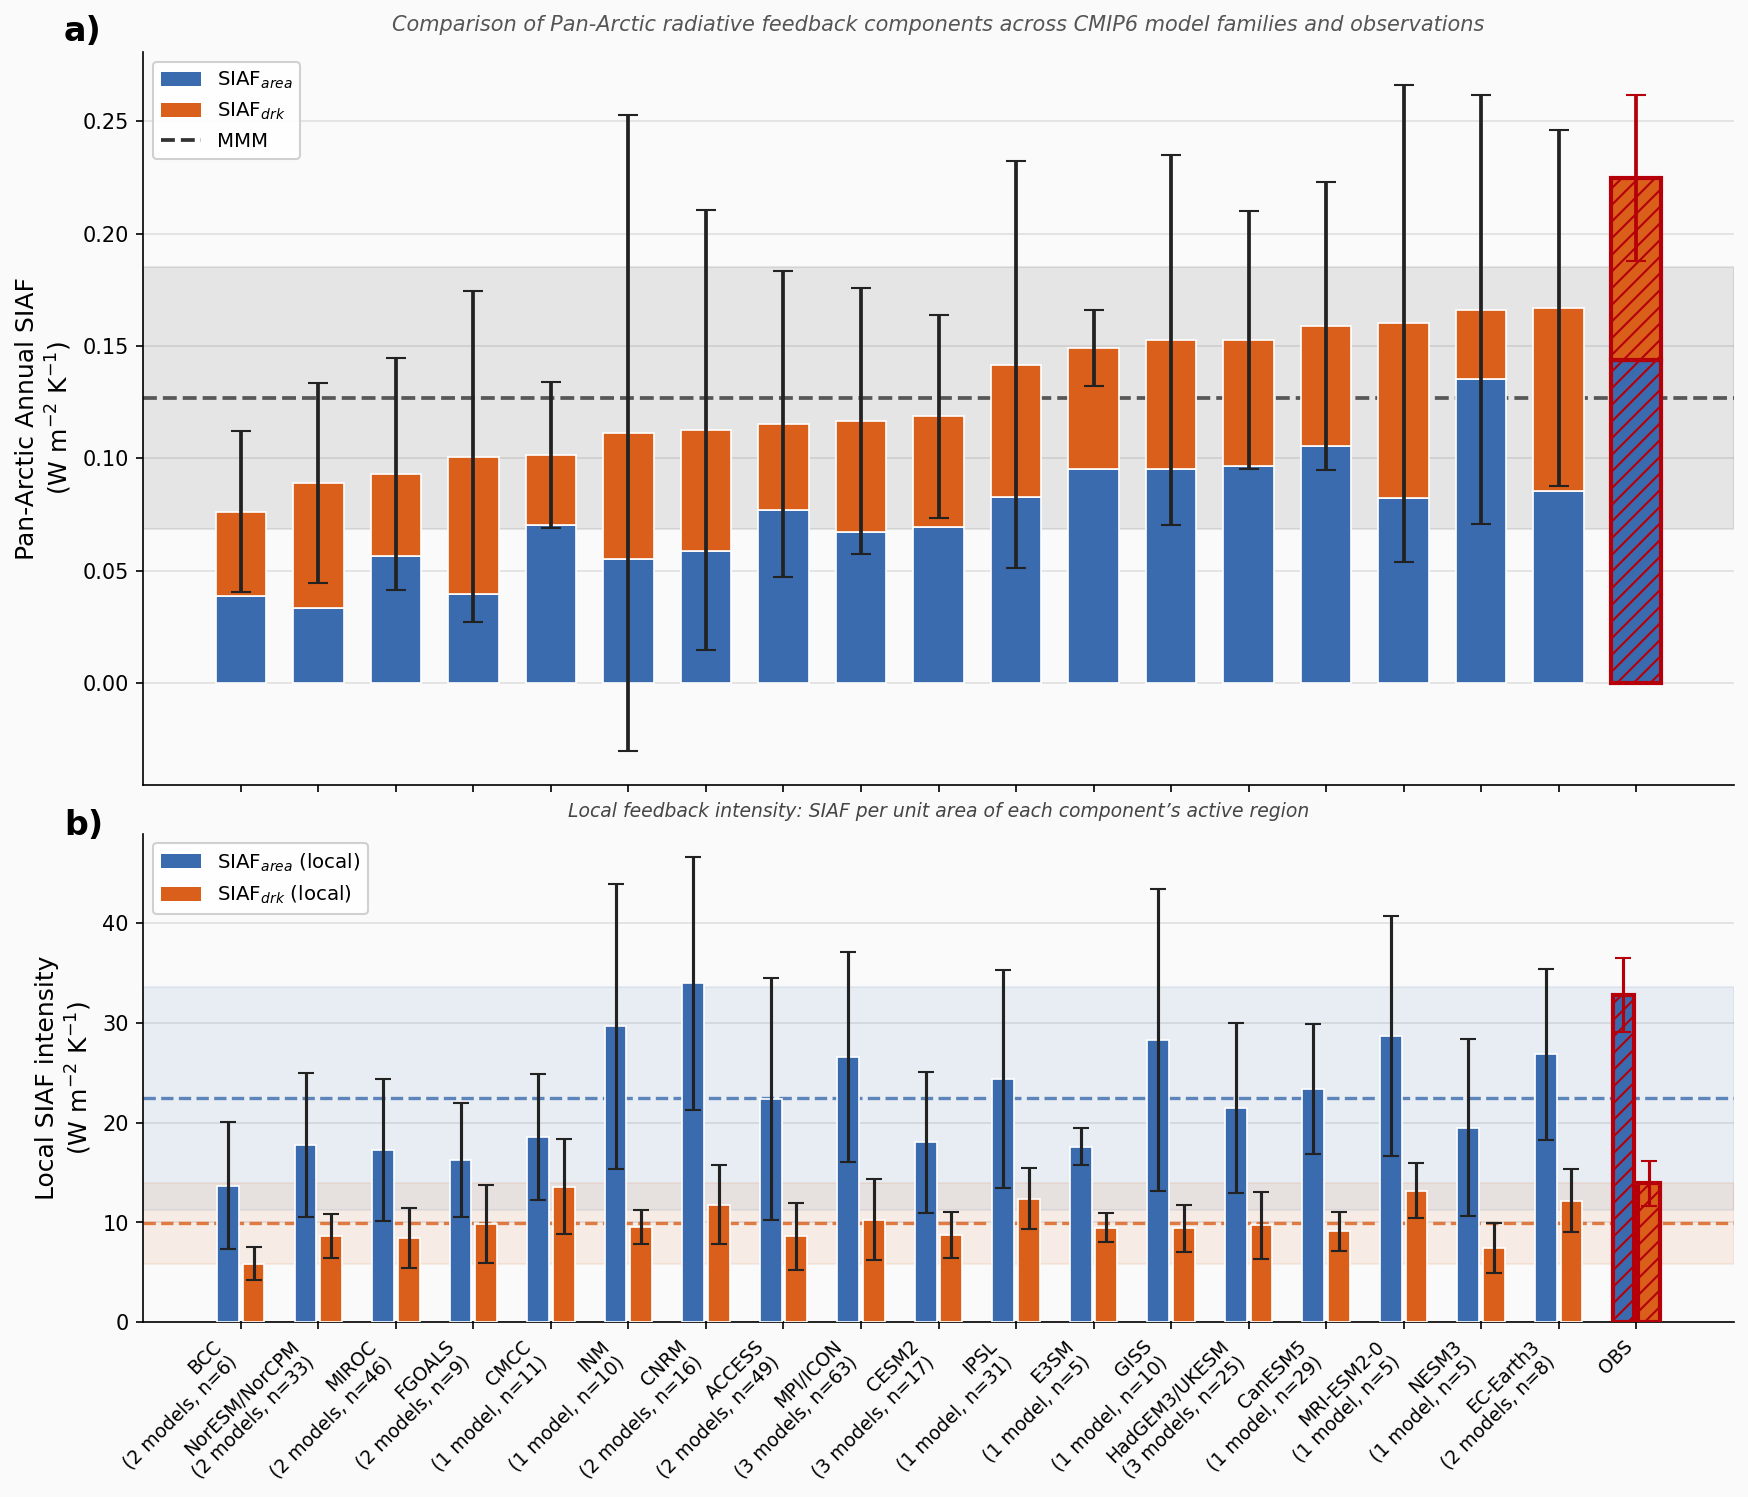

In [6]:
#!/usr/bin/env python
"""
Fig 3 (family-aggregated) — CMIP6 SIAF decomposition by model family.
(a) global-mean SIAF, stacked area-loss + darkening.
(b) LOCAL feedback intensity: mean IS x RS over each component's active
    pixels, i.e. the per-area SIAF with the global normalisation
    (AREA_RATIO x SEASON_FRAC) divided back out. Units are W m-2 K-1 per
    unit area of the active region, so panel b is ~1-2 orders of magnitude
    larger than panel a by construction.
"""
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D

CMIP6_CSV = '/glade/derecho/scratch/jrotondo/siaf_cmip6_summary_final.csv'
OBS_CSV   = '/glade/work/jrotondo/ncc_paper/plots/sensitivity/siaf_pixelwise_summary.csv'
PLOT_OUT  = '/glade/work/jrotondo/ncc_paper/plots/cmip6_pistone_only/f03_family_local.png'
MIN_MEMBERS = 3
SCALE = 0.0347 * 0.5          # AREA_RATIO_OCEAN x SEASON_FRAC, as in the pipeline

COL_EXT, COL_DRK, COL_OBS_EDGE, COL_MMM = '#3A6BAF', '#D95F1A', '#b5000a', '#333333'

FAMILY = {**{m:'CESM2' for m in ['CESM2','CESM2-WACCM','CESM2-FV2','CESM2-WACCM-FV2']},
          **{m:'EC-Earth3' for m in ['EC-Earth3','EC-Earth3-Veg','EC-Earth3-Veg-LR',
                                     'EC-Earth3-CC','EC-Earth3-AerChem','EC-Earth3-ESM-1']},
          **{m:'CMCC' for m in ['CMCC-CM2-SR5','CMCC-ESM2','CMCC-CM2-HR4']},
          **{m:'E3SM' for m in ['E3SM-1-0','E3SM-1-1','E3SM-1-1-ECA']},
          **{m:'HadGEM3/UKESM' for m in ['HadGEM3-GC31-LL','HadGEM3-GC31-MM',
                                         'UKESM1-0-LL','UKESM1-1-LL']},
          **{m:'MPI/ICON' for m in ['MPI-ESM1-2-HR','MPI-ESM1-2-LR',
                                    'MPI-ESM-1-2-HAM','ICON-ESM-LR']},
          **{m:'NorESM/NorCPM' for m in ['NorESM2-LM','NorESM2-MM','NorCPM1']},
          **{m:'CNRM' for m in ['CNRM-CM6-1','CNRM-CM6-1-HR','CNRM-ESM2-1']},
          **{m:'CanESM5' for m in ['CanESM5','CanESM5-CanOE']},
          **{m:'MIROC' for m in ['MIROC6','MIROC-ES2L']},
          **{m:'IPSL' for m in ['IPSL-CM6A-LR','IPSL-CM6A-LR-INCA','IPSL-CM5A2-INCA']},
          **{m:'INM' for m in ['INM-CM4-8','INM-CM5-0']},
          **{m:'FGOALS' for m in ['FGOALS-g3','FGOALS-f3-L']},
          **{m:'BCC' for m in ['BCC-CSM2-MR','BCC-ESM1']},
          **{m:'ACCESS' for m in ['ACCESS-CM2','ACCESS-ESM1-5']},
          **{m:'GISS' for m in ['GISS-E2-1-H','GISS-E2-1-G']}}

df = pd.read_csv(CMIP6_CSV); df = df[df.rs_method == 'full_T07'].copy()
cnt = df.groupby('model').size()
df = df[df.model.isin(cnt[cnt >= MIN_MEMBERS].index)].copy()
df['family'] = df.model.map(lambda m: FAMILY.get(m, m))

# convert per-area SIAF -> LOCAL intensity
df['ext_loc'] = df.siaf_ext_per_area / SCALE
df['drk_loc'] = df.siaf_drk_per_area / SCALE

mm = df.groupby(['family','model']).agg(
        tot=('siaf_global','mean'), ext=('siaf_ext_global','mean'),
        drk=('siaf_drk_global','mean'),
        ext_loc=('ext_loc','mean'), drk_loc=('drk_loc','mean'))
fam = mm.groupby('family').mean()
spread = df.groupby('family').agg(tot_sd=('siaf_global','std'),
                                  ext_loc_sd=('ext_loc','std'),
                                  drk_loc_sd=('drk_loc','std'))
fam = fam.join(spread)
fam['n_mod'] = mm.groupby('family').size()
fam['n_mem'] = df.groupby('family').size()
fam = fam.sort_values('tot'); fams = list(fam.index)

o = pd.read_csv(OBS_CSV)
o = o[(o.rs_method=='CERES') & (o.period=='CMIP6') & (np.isclose(o.pval,0.05))].iloc[0]
obs = dict(tot=float(o.SIAF_tot_global), ext=float(o.SIAF_ext_global),
           drk=float(o.SIAF_drk_global), err=float(o.sigma2_tot_global),
           ext_loc=float(o.SIAF_ext_per_area)/SCALE,
           drk_loc=float(o.SIAF_drk_per_area)/SCALE,
           ext_loc_e=float(o.sigma2_ext_per_area)/SCALE,
           drk_loc_e=float(o.sigma2_drk_per_area)/SCALE)

mmm      = float(fam.tot.mean());     mmm_2s   = float(2*fam.tot.std(ddof=1))
mmm_e_lc = float(fam.ext_loc.mean()); mmm_e_2s = float(2*fam.ext_loc.std(ddof=1))
mmm_d_lc = float(fam.drk_loc.mean()); mmm_d_2s = float(2*fam.drk_loc.std(ddof=1))

labels = [f'{f}\n({int(fam.n_mod[f])} model{"s" if fam.n_mod[f]>1 else ""}, '
          f'n={int(fam.n_mem[f])})' for f in fams] + ['OBS']
tot = list(fam.tot) + [obs['tot']];  ext = list(fam.ext) + [obs['ext']]
drk = list(fam.drk) + [obs['drk']];  err = list(2*fam.tot_sd.fillna(0)) + [obs['err']]
elc = list(fam.ext_loc) + [obs['ext_loc']]; dlc = list(fam.drk_loc) + [obs['drk_loc']]
ele = list(2*fam.ext_loc_sd.fillna(0)) + [obs['ext_loc_e']]
dle = list(2*fam.drk_loc_sd.fillna(0)) + [obs['drk_loc_e']]

n = len(labels); x = np.arange(n); w = 0.65
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(max(12, n*0.72), 11), dpi=150, sharex=True,
                              gridspec_kw={'height_ratios':[3,2], 'hspace':0.08})
fig.patch.set_facecolor('#FAFAFA')
for a in (ax, ax2): a.set_facecolor('#FAFAFA')

ax.text(-0.05, 1.05, 'a)', transform=ax.transAxes, fontsize=16, fontweight='bold', va='top')
ax2.text(-0.05, 1.05, 'b)', transform=ax2.transAxes, fontsize=16, fontweight='bold', va='top')
ax.set_title('Comparison of Pan-Arctic radiative feedback components across '
             'CMIP6 model families and observations',
             fontsize=10, color='#555555', style='italic', pad=10)
ax2.set_title('Local feedback intensity: SIAF per unit area of each '
              'component\u2019s active region',
              fontsize=9, color='#454545', style='italic', pad=8)

# ---- panel a: global-mean, stacked ----
ax.axhspan(mmm-mmm_2s, mmm+mmm_2s, color=COL_MMM, alpha=0.10, zorder=1)
ax.axhline(mmm, color=COL_MMM, lw=1.8, ls='--', alpha=0.80, zorder=2)
for i in range(n):
    is_obs = (i == n-1)
    edge = COL_OBS_EDGE if is_obs else 'white'; lw = 2.0 if is_obs else 0.8
    hatch = '///' if is_obs else ''
    ax.bar(x[i], ext[i], w, color=COL_EXT, edgecolor=edge, linewidth=lw, hatch=hatch, zorder=3)
    ax.bar(x[i], drk[i], w, bottom=ext[i], color=COL_DRK, edgecolor=edge,
           linewidth=lw, hatch=hatch, zorder=3)
    ax.errorbar(x[i], tot[i], yerr=err[i], fmt='none',
                color=COL_OBS_EDGE if is_obs else '#222222', capsize=5, lw=1.8, zorder=5)
ax.set_ylabel('Pan-Arctic Annual SIAF\n(W m$^{-2}$ K$^{-1}$)', fontsize=12)
ax.legend(handles=[mpatches.Patch(facecolor=COL_EXT, label=r'SIAF$_{area}$'),
                   mpatches.Patch(facecolor=COL_DRK, label=r'SIAF$_{drk}$'),
                   Line2D([0],[0], color=COL_MMM, lw=1.8, ls='--', label='MMM')],
          loc='upper left', fontsize=9.5, framealpha=0.9)

# ---- panel b: LOCAL intensity, grouped ----
w2, gap = 0.28, 0.05
ax2.axhspan(mmm_e_lc-mmm_e_2s, mmm_e_lc+mmm_e_2s, color=COL_EXT, alpha=0.09, zorder=1)
ax2.axhline(mmm_e_lc, color=COL_EXT, lw=1.6, ls='--', alpha=0.80, zorder=2)
ax2.axhspan(mmm_d_lc-mmm_d_2s, mmm_d_lc+mmm_d_2s, color=COL_DRK, alpha=0.09, zorder=1)
ax2.axhline(mmm_d_lc, color=COL_DRK, lw=1.6, ls='--', alpha=0.80, zorder=2)
for i in range(n):
    is_obs = (i == n-1)
    edge = COL_OBS_EDGE if is_obs else 'white'; hatch = '///' if is_obs else ''
    xe, xd = x[i]-w2/2-gap/2, x[i]+w2/2+gap/2
    if np.isfinite(elc[i]):
        ax2.bar(xe, elc[i], w2, color=COL_EXT, edgecolor=edge,
                lw=2.0 if is_obs else 0.8, hatch=hatch, zorder=3)
        ax2.errorbar(xe, elc[i], yerr=ele[i], fmt='none',
                     color=COL_OBS_EDGE if is_obs else '#222222', capsize=4, zorder=5)
    if np.isfinite(dlc[i]):
        ax2.bar(xd, dlc[i], w2, color=COL_DRK, edgecolor=edge,
                lw=2.0 if is_obs else 0.8, hatch=hatch, zorder=3)
        ax2.errorbar(xd, dlc[i], yerr=dle[i], fmt='none',
                     color=COL_OBS_EDGE if is_obs else '#222222', capsize=4, zorder=5)
ax2.set_xticks(x); ax2.set_xticklabels(labels, rotation=45, ha='right', fontsize=9)
ax2.set_ylabel('Local SIAF intensity\n(W m$^{-2}$ K$^{-1}$)', fontsize=12)
ax2.legend(handles=[mpatches.Patch(facecolor=COL_EXT, label=r'SIAF$_{area}$ (local)'),
                    mpatches.Patch(facecolor=COL_DRK, label=r'SIAF$_{drk}$ (local)')],
           loc='upper left', fontsize=9.5, framealpha=0.9)

for a in (ax, ax2):
    a.yaxis.grid(True, alpha=0.35, lw=0.8, zorder=0); a.set_axisbelow(True)
    for s in ('top','right'): a.spines[s].set_visible(False)
plt.savefig(PLOT_OUT, dpi=300, bbox_inches='tight', facecolor=fig.get_facecolor())
print(f'-> {PLOT_OUT}')
print(f'   local MMM: area={mmm_e_lc:.2f}  drk={mmm_d_lc:.2f}  '
      f'| obs area={obs["ext_loc"]:.2f} drk={obs["drk_loc"]:.2f} W m-2 K-1')

## Figure 4

In [21]:
#!/usr/bin/env python
"""
plot_is_rs_uncertainty.py
─────────────────────────
Decomposes the ensemble spread of CMIP6 SIAF into Ice Sensitivity (IS)
and Radiative State (RS) uncertainty. Plots the models against the
observational target zone (± 2σ).

OBS IS, RS, and SIAF are all loaded from siaf_pixelwise_summary.csv
(siaf_obs_analysis.py output), CMIP6 / CERES / p=0.05 row.
Nothing is hardcoded.

Only members using Full / Approx. T07 RS are plotted.
Only models with >= 3 valid members are plotted.
"""

import os
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D

DIR_CMIP6_CSV = '/glade/work/jrotondo/ncc_paper/plots/cmip6_pistone_only/siaf_cmip6_summary.csv'
DIR_OBS_CSV   = '/glade/work/jrotondo/ncc_paper/plots/sensitivity/siaf_pixelwise_summary.csv'
PLOT_OUT      = '/glade/work/jrotondo/ncc_paper/plots/cmip6_pistone_only/siaf_uncertainty_decomposition.png'

SCALE = 0.0347 * 0.5   # must match siaf_obs_analysis.py

MODEL_COLORS = {
    'CESM2'          : '#1f77b4',
    'E3SM-1-0'       : '#ff7f0e',
    'MPI-ESM1-2-HR'  : '#2ca02c',
    'MPI-ESM1-2-LR'  : '#98df8a',
    'IPSL-CM6A-LR'   : '#d62728',
    'MIROC6'         : '#9467bd',
    'CanESM5'        : '#8c564b',
    'ACCESS-ESM1-5'  : '#e377c2',
    'GFDL-ESM4'      : '#7f7f7f',
    'UKESM1-0-LL'    : '#17becf',
    'HadGEM3-GC31-LL': '#aec7e8',
    'CNRM-CM6-1'     : '#ffbb78',
    'BCC-CSM2-MR'    : '#ff9896',
}

KNOWN_PROXY_MODELS = {
    'MPI-ESM1-2-HR', 'MPI-ESM1-2-LR', 'CanESM5',
    'ACCESS-ESM1-5', 'GFDL-ESM4', 'UKESM1-0-LL', 'HadGEM3-GC31-LL'
}


def load_obs_values(obs_csv):
    if not os.path.exists(obs_csv):
        print(f"WARNING: Cannot find OBS CSV at {obs_csv}")
        return (np.nan,) * 6

    df_obs = pd.read_csv(obs_csv)
    match  = df_obs[(df_obs['rs_method'] == 'CERES') &
                    (df_obs['period']    == 'CMIP6') &
                    (np.isclose(df_obs['pval'], 0.05))]

    if match.empty:
        print("WARNING: Could not find matching OBS row "
              "(rs_method=CERES, period=CMIP6, pval=0.05).")
        print("  Columns found:    ", df_obs.columns.tolist())
        print("  rs_method values: ", df_obs['rs_method'].unique().tolist())
        print("  period values:    ", df_obs['period'].unique().tolist())
        return (np.nan,) * 6

    siaf_mean = float(match['SIAF_tot_global'].iloc[0])
    siaf_2sig = float(match['sigma2_tot_global'].iloc[0])
    is_mean   = float(match['IS_tot_arctic'].iloc[0])
    is_2sig   = float(match['sigma2_IS_arctic'].iloc[0])
    rs_mean   = float(match['RS_arctic'].iloc[0])
    rs_2sig   = float(match['sigma2_RS_arctic'].iloc[0])

    print(f"Loaded from CSV (CMIP6 / CERES / p=0.05):")
    print(f"  SIAF global : {siaf_mean:.5f} ± {siaf_2sig:.5f}  W m⁻² K⁻¹")
    print(f"  IS arctic   : {is_mean:.5f} ± {is_2sig:.5f}  K⁻¹")
    print(f"  RS arctic   : {rs_mean:.4f} ± {rs_2sig:.4f}  W m⁻²")
    return siaf_mean, siaf_2sig, is_mean, is_2sig, rs_mean, rs_2sig


def draw_siaf_band(ax, rs_range, siaf_lo, siaf_hi, scale,
                   color='#2166ac', alpha=0.18, n=400):
    rs_vals     = np.linspace(rs_range[0], rs_range[1], n)
    is_lo_curve = siaf_lo / (rs_vals * scale)
    is_hi_curve = siaf_hi / (rs_vals * scale)

    ax.fill_between(rs_vals, is_lo_curve, is_hi_curve,
                    color=color, alpha=alpha, zorder=1,
                    label='Obs SIAF ± 2σ band')
    for curve in [is_lo_curve, is_hi_curve]:
        ax.plot(rs_vals, curve, color=color, lw=1.0,
                linestyle=(0, (4, 3)), alpha=0.6, zorder=2)
    siaf_mid     = (siaf_lo + siaf_hi) / 2.
    is_mid_curve = siaf_mid / (rs_vals * scale)
    ax.plot(rs_vals, is_mid_curve, color=color, lw=1.4,
            linestyle='--', alpha=0.8, zorder=2)


def _in_bounds(val, centre, half_width, label):
    lo, hi = centre - half_width, centre + half_width
    inside = lo <= val <= hi
    status = '✓ WITHIN' if inside else '✗ OUTSIDE'
    print(f"  {label}: MMM = {val:.4f}  |  OBS ± 2σ = [{lo:.4f}, {hi:.4f}]  →  {status}")
    return inside


def main():
    if not os.path.exists(DIR_CMIP6_CSV):
        print(f"ERROR: Cannot find {DIR_CMIP6_CSV}")
        return

    df = pd.read_csv(DIR_CMIP6_CSV)

    # ── Load all OBS values from CSV ──────────────────────────────────────────
    (OBS_SIAF_MEAN, OBS_SIAF_2SIGMA,
     OBS_IS_MEAN,   OBS_IS_2SIGMA,
     OBS_RS_MEAN,   OBS_RS_2SIGMA) = load_obs_values(DIR_OBS_CSV)

    SIAF_LO = OBS_SIAF_MEAN - OBS_SIAF_2SIGMA
    SIAF_HI = OBS_SIAF_MEAN + OBS_SIAF_2SIGMA

    # ── Filter proxy members out ──────────────────────────────────────────────
    if 'rs_method' in df.columns:
        df['_proxy'] = df['rs_method'] == 'rsds_proxy'
    else:
        df['_proxy'] = df['model'].isin(KNOWN_PROXY_MODELS)
    df = df[~df['_proxy']].copy()

    # ── Require >= 3 valid members ────────────────────────────────────────────
    member_counts = df['model'].value_counts()
    valid_models  = member_counts[member_counts >= 3].index.tolist()
    df            = df[df['model'].isin(valid_models)].copy()

    print(f"\nRetained models (>= 3 full/approx T07 members):")
    for m in valid_models:
        print(f"  - {m}: {member_counts[m]} members")

    # ── Equal-weight MMM of RS and IS ─────────────────────────────────────────
    model_rs_means = []
    model_is_means = []
    for m in valid_models:
        sub = df[df['model'] == m]
        rs_m = sub['rs_arctic'].mean()
        is_m = sub['is_tot_arctic'].mean()
        if np.isfinite(rs_m): model_rs_means.append(rs_m)
        if np.isfinite(is_m): model_is_means.append(is_m)

    MMM_RS = float(np.mean(model_rs_means)) if model_rs_means else np.nan
    MMM_IS = float(np.mean(model_is_means)) if model_is_means else np.nan
    MMM_RS_2std = float(2. * np.std(model_rs_means, ddof=1)) if len(model_rs_means) > 1 else np.nan
    MMM_IS_2std = float(2. * np.std(model_is_means, ddof=1)) if len(model_is_means) > 1 else np.nan

    print(f"\n── Equal-weight MMM ({len(valid_models)} models) ──────────────────")
    print(f"  MMM RS = {MMM_RS:.4f} ± {MMM_RS_2std:.4f}  W m⁻²  (±2σ across models)")
    print(f"  MMM IS = {MMM_IS:.5f} ± {MMM_IS_2std:.5f}  K⁻¹   (±2σ across models)")

    print(f"\n── MMM vs OBS ± 2σ bounds ────────────────────────────────────")
    rs_in = _in_bounds(MMM_RS, OBS_RS_MEAN, OBS_RS_2SIGMA, 'RS')
    is_in = _in_bounds(MMM_IS, OBS_IS_MEAN, OBS_IS_2SIGMA, 'IS')

    # ── CV table for panel (b) ────────────────────────────────────────────────
    cv_data = []
    for m in valid_models:
        sub = df[df['model'] == m]
        is_m, is_s = sub['is_tot_arctic'].mean(), sub['is_tot_arctic'].std()
        rs_m, rs_s = sub['rs_arctic'].mean(),     sub['rs_arctic'].std()
        cv_is = (is_s / abs(is_m)) * 100 if is_m != 0 else 0
        cv_rs = (rs_s / abs(rs_m)) * 100 if rs_m != 0 else 0
        cv_data.append({'model': m, 'cv_is': cv_is, 'cv_rs': cv_rs})

    df_cv = (pd.DataFrame(cv_data)
               .sort_values('cv_is', ascending=True)
               .reset_index(drop=True))

    # ── Figure: 3-column GridSpec — scatter | legend | CV bars ───────────────
    fig = plt.figure(figsize=(17, 7), facecolor='#FAFAFA')
    gs  = GridSpec(1, 3, figure=fig,
                width_ratios=[4.5, 3, 5],
                wspace=0.08)

    ax1    = fig.add_subplot(gs[0])   # IS vs RS scatter
    ax_leg = fig.add_subplot(gs[1])   # legend only
    ax2    = fig.add_subplot(gs[2])   # CV bars

    ax_leg.axis('off')                # invisible axes, just holds the legend
    for ax in [ax1, ax2]:
        ax.set_facecolor('#FAFAFA')

    # ════════════════════════════════════════════════════════════════════════
    # PANEL (a): IS vs RS scatter
    # ════════════════════════════════════════════════════════════════════════
    all_rs = df['rs_arctic'].dropna()
    rs_pad = 5.

    rs_lo = max(all_rs.min() - rs_pad, 80.)
    rs_hi = min(all_rs.max() + rs_pad, 220.)

    if np.isfinite(MMM_RS) and np.isfinite(MMM_RS_2std):
        rs_lo = min(rs_lo, MMM_RS - MMM_RS_2std - rs_pad)
        rs_hi = max(rs_hi, MMM_RS + MMM_RS_2std + rs_pad)

    rs_range = (rs_lo, rs_hi)

    if np.isfinite(SIAF_LO) and np.isfinite(SIAF_HI):
        draw_siaf_band(ax1, rs_range, SIAF_LO, SIAF_HI, SCALE,
                       color='#2166ac', alpha=0.18)

    if not any(np.isnan(v) for v in [OBS_IS_MEAN, OBS_RS_MEAN,
                                      OBS_IS_2SIGMA, OBS_RS_2SIGMA]):
        ax1.axvspan(OBS_RS_MEAN - OBS_RS_2SIGMA,
                    OBS_RS_MEAN + OBS_RS_2SIGMA,
                    color='#b5000a', alpha=0.06, zorder=1)
        ax1.axhspan(OBS_IS_MEAN - OBS_IS_2SIGMA,
                    OBS_IS_MEAN + OBS_IS_2SIGMA,
                    color='#b5000a', alpha=0.06, zorder=1)
        ax1.add_patch(Rectangle(
            (OBS_RS_MEAN - OBS_RS_2SIGMA, OBS_IS_MEAN - OBS_IS_2SIGMA),
            OBS_RS_2SIGMA * 2, OBS_IS_2SIGMA * 2,
            fill=False, edgecolor='#b5000a',
            linestyle='--', lw=1.5, zorder=3
        ))
        ax1.plot(OBS_RS_MEAN, OBS_IS_MEAN,
                 marker='*', color='#b5000a',
                 markersize=16, markeredgecolor='white',
                 zorder=6, label='OBS Target ± 2σ')

    for m in df['model'].unique():
        sub   = df[df['model'] == m]
        color = MODEL_COLORS.get(m, '#888888')
        ax1.scatter(sub['rs_arctic'], sub['is_tot_arctic'],
                    color=color, alpha=0.85,
                    marker='o', edgecolors='white', linewidths=0.5,
                    s=70, zorder=4, label=m)

    if np.isfinite(MMM_RS) and np.isfinite(MMM_IS):
        ax1.errorbar(MMM_RS, MMM_IS,
                     xerr=MMM_RS_2std if np.isfinite(MMM_RS_2std) else None,
                     yerr=MMM_IS_2std if np.isfinite(MMM_IS_2std) else None,
                     fmt='none', color='#222222',
                     capsize=5, linewidth=1.6, capthick=1.6, zorder=7)
        ax1.scatter(MMM_RS, MMM_IS,
                    marker='D', color='#222222',
                    s=70, edgecolors='white', linewidths=0.8,
                    zorder=8,
                    label=(f'MMM RS/IS ±2σ'))

    ax1.set_xlim(rs_range)
    ax1.set_xlabel('RS [W m⁻²]', fontsize=11)
    ax1.set_ylabel('IS [K⁻¹]', fontsize=11)
    ax1.set_title('Member Distribution: IS vs RS', fontsize=12, fontweight='bold')
    ax1.grid(True, alpha=0.3, zorder=0)
    ax1.tick_params(axis='both', which='major', labelsize=12)
    for sp in ['top', 'right']:
        ax1.spines[sp].set_visible(False)

    # ── Legend in the middle column ───────────────────────────────────────────
    handles, labels = ax1.get_legend_handles_labels()
    ax_leg.legend(handles, labels,
              loc='center left',
              bbox_to_anchor=(0, 0.5),
              fontsize=7.5,
              framealpha=0.9, handlelength=1.4,
              borderpad=0.7, labelspacing=0.55)

    # ════════════════════════════════════════════════════════════════════════
    # PANEL (b): Coefficient of Variation bars (horizontal)
    # ════════════════════════════════════════════════════════════════════════
    y = np.arange(len(df_cv))
    h = 0.35

    ax2.barh(y - h / 2, df_cv['cv_is'], h,
             label='IS Spread (Ice Physics)',
             color='#17becf', edgecolor='white', alpha=0.85, zorder=3)
    ax2.barh(y + h / 2, df_cv['cv_rs'], h,
             label='RS Spread (Clouds/Radiation)',
             color='#ff7f0e', edgecolor='white', alpha=0.85, zorder=3)

    ax2.set_yticks(y)
    ax2.set_yticklabels(df_cv['model'], fontsize=12)
    ax2.set_xlabel('Coefficient of Variation (%)', fontsize=11)
    ax2.set_title('Relative Ensemble Uncertainty (σ / µ)', fontsize=12, fontweight='bold')
    ax2.grid(True, axis='x', alpha=0.3, zorder=0)
    ax2.legend(fontsize=10, framealpha=0.9, loc='lower right')
    ax2.set_axisbelow(True)
    ax2.tick_params(axis='both', which='major', labelsize=12)
    for sp in ['top', 'right']:
        ax2.spines[sp].set_visible(False)

    plt.tight_layout()
    plt.savefig(PLOT_OUT, dpi=150, bbox_inches='tight',
                facecolor=fig.get_facecolor())
    plt.close()
    print(f'\nPlot saved → {PLOT_OUT}')
    print(f'OBS SIAF band: [{SIAF_LO:.5f}, {SIAF_HI:.5f}] W m⁻² K⁻¹')


if __name__ == '__main__':
    main()

Loaded from CSV (CMIP6 / CERES / p=0.05):
  SIAF global : 0.22477 ± 0.03697  W m⁻² K⁻¹
  IS arctic   : 0.08240 ± 0.01106  K⁻¹
  RS arctic   : 150.5187 ± 0.9936  W m⁻²

Retained models (>= 3 full/approx T07 members):
  - MPI-ESM1-2-LR: 51 members
  - MIROC6: 45 members
  - CanESM5: 39 members
  - IPSL-CM6A-LR: 33 members
  - UKESM1-0-LL: 15 members
  - CNRM-CM6-1: 12 members
  - CESM2: 11 members
  - GISS-E2-1-H: 11 members
  - ACCESS-ESM1-5: 10 members
  - INM-CM5-0: 10 members
  - MPI-ESM1-2-HR: 10 members
  - CNRM-ESM2-1: 5 members
  - MRI-ESM2-0: 5 members
  - HadGEM3-GC31-LL: 4 members
  - ACCESS-CM2: 3 members
  - BCC-CSM2-MR: 3 members
  - MIROC-ES2L: 3 members

── Equal-weight MMM (17 models) ──────────────────
  MMM RS = 151.6237 ± 32.2405  W m⁻²  (±2σ across models)
  MMM IS = 0.05265 ± 0.02407  K⁻¹   (±2σ across models)

── MMM vs OBS ± 2σ bounds ────────────────────────────────────
  RS: MMM = 151.6237  |  OBS ± 2σ = [149.5251, 151.5123]  →  ✗ OUTSIDE
  IS: MMM = 0.0526  |  

/glade/derecho/scratch/jrotondo/tmp/ipykernel_58370/2091595599.py:295: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()



Plot saved → /glade/work/jrotondo/ncc_paper/plots/cmip6_pistone_only/siaf_uncertainty_decomposition.png
OBS SIAF band: [0.18780, 0.26174] W m⁻² K⁻¹


### Only plotting IS vs RS (for paper)

In [13]:
#!/usr/bin/env python
"""
Fig 4 — IS vs RS for the expanded ensemble.

Every ensemble member is plotted and coloured by model family. No per-model
markers or error bars: the member cloud carries the spread directly, and
overlapping bars from models of the same family were unreadable. Only the
observations and the multi-model mean carry error bars.
"""
import numpy as np, pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

CMIP6_CSV = '/glade/derecho/scratch/jrotondo/siaf_cmip6_summary_final.csv'
OBS_CSV   = '/glade/work/jrotondo/ncc_paper/plots/sensitivity/siaf_pixelwise_summary.csv'
PLOT_OUT  = '/glade/work/jrotondo/ncc_paper/plots/cmip6_pistone_only/f04_family.png'
MIN_MEMBERS = 3

FAMILY = {**{m:'CESM2' for m in ['CESM2','CESM2-WACCM','CESM2-FV2','CESM2-WACCM-FV2']},
          **{m:'EC-Earth3' for m in ['EC-Earth3','EC-Earth3-Veg','EC-Earth3-Veg-LR',
                                     'EC-Earth3-CC','EC-Earth3-AerChem','EC-Earth3-ESM-1']},
          **{m:'CMCC' for m in ['CMCC-CM2-SR5','CMCC-ESM2','CMCC-CM2-HR4']},
          **{m:'E3SM' for m in ['E3SM-1-0','E3SM-1-1','E3SM-1-1-ECA']},
          **{m:'HadGEM3/UKESM' for m in ['HadGEM3-GC31-LL','HadGEM3-GC31-MM',
                                         'UKESM1-0-LL','UKESM1-1-LL']},
          **{m:'MPI/ICON' for m in ['MPI-ESM1-2-HR','MPI-ESM1-2-LR',
                                    'MPI-ESM-1-2-HAM','ICON-ESM-LR']},
          **{m:'NorESM/NorCPM' for m in ['NorESM2-LM','NorESM2-MM','NorCPM1']},
          **{m:'CNRM' for m in ['CNRM-CM6-1','CNRM-CM6-1-HR','CNRM-ESM2-1']},
          **{m:'CanESM5' for m in ['CanESM5','CanESM5-CanOE']},
          **{m:'MIROC' for m in ['MIROC6','MIROC-ES2L']},
          **{m:'IPSL' for m in ['IPSL-CM6A-LR','IPSL-CM6A-LR-INCA','IPSL-CM5A2-INCA']},
          **{m:'INM' for m in ['INM-CM4-8','INM-CM5-0']},
          **{m:'FGOALS' for m in ['FGOALS-g3','FGOALS-f3-L']},
          **{m:'BCC' for m in ['BCC-CSM2-MR','BCC-ESM1']},
          **{m:'ACCESS' for m in ['ACCESS-CM2','ACCESS-ESM1-5']},
          **{m:'GISS' for m in ['GISS-E2-1-H','GISS-E2-1-G']}}

PAL = ['#1f77b4','#d62728','#2ca02c','#ff7f0e','#9467bd','#8c564b','#e377c2',
       '#17becf','#bcbd22','#7f7f7f','#aec7e8','#ff9896','#98df8a','#ffbb78',
       '#c5b0d5','#c49c94','#f7b6d2','#dbdb8d','#9edae5','#c7c7c7']

OBS_STYLE = {
    'CERES':  dict(color='#b5000a', marker='*', ms=21,
                   label='Obs · CERES APRP ($\\pm2\\sigma$)'),
    'Kernel': dict(color='#5e3c99', marker='P', ms=14,
                   label='Obs · ERA5 kernel ($\\pm2\\sigma$)'),
}


def load_obs(df_obs, method):
    m = df_obs[(df_obs.rs_method == method) & (df_obs.period == 'CMIP6') &
               (np.isclose(df_obs.pval, 0.05))]
    if m.empty:
        print(f'WARNING: no OBS row for {method}'); return None
    r = m.iloc[0]
    o = dict(is_=float(r.IS_tot_arctic), is_2s=float(r.sigma2_IS_arctic),
             rs=float(r.RS_arctic),      rs_2s=float(r.sigma2_RS_arctic))
    print(f'OBS {method:7s}: IS={o["is_"]:.4f}±{o["is_2s"]:.4f}  '
          f'RS={o["rs"]:.2f}±{o["rs_2s"]:.2f}')
    return o


# ── data ──────────────────────────────────────────────────────────────────
df = pd.read_csv(CMIP6_CSV)
df = df[df.rs_method == 'full_T07'].copy()
cnt = df.groupby('model').size()
df = df[df.model.isin(cnt[cnt >= MIN_MEMBERS].index)].copy()
df = df.dropna(subset=['rs_arctic', 'is_tot_arctic'])
df['family'] = df.model.map(lambda m: FAMILY.get(m, m))
print(f'{len(df)} members / {df.model.nunique()} models / {df.family.nunique()} families')

# per-model stats: not plotted, but printed for the text
mstat = (df.groupby(['family','model'])
           .agg(rs=('rs_arctic','mean'), is_=('is_tot_arctic','mean'),
                rs_sd=('rs_arctic','std'), is_sd=('is_tot_arctic','std'))
           .fillna(0.).reset_index())

mm  = df.groupby(['family','model'])[['rs_arctic','is_tot_arctic']].mean()
fam = mm.groupby('family').mean()
fam['n_mem'] = df.groupby('family').size()
fam = fam.sort_values('is_tot_arctic', ascending=False)   # legend tracks y-axis

MMM_RS, MMM_IS = fam.rs_arctic.mean(), fam.is_tot_arctic.mean()
MMM_RS_2s = 2 * fam.rs_arctic.std(ddof=1)
MMM_IS_2s = 2 * fam.is_tot_arctic.std(ddof=1)
print(f'family MMM: RS={MMM_RS:.2f}±{MMM_RS_2s:.2f}  IS={MMM_IS:.4f}±{MMM_IS_2s:.4f}')
print(f'family RS range: {fam.rs_arctic.min():.0f}-{fam.rs_arctic.max():.0f}')
print(f'per-model RS range: {mstat.rs.min():.0f}-{mstat.rs.max():.0f}')
print(f'median within-model RS 2-sigma: {2*mstat.rs_sd.median():.2f} W m-2')
print(f'median within-model IS 2-sigma: {2*mstat.is_sd.median():.4f} K-1')

df_obs = pd.read_csv(OBS_CSV)
obs = {m: load_obs(df_obs, m) for m in ('CERES', 'Kernel')}
o_prim = obs['CERES']

# ── figure ────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(11, 7.5), facecolor='#FAFAFA', dpi = 300)
ax.set_facecolor('#FAFAFA')

fams = list(fam.index)
cols = {f: PAL[i % len(PAL)] for i, f in enumerate(fams)}

# observational IS band (shared by both RS methods)
if o_prim:
    ax.axhspan(o_prim['is_'] - o_prim['is_2s'], o_prim['is_'] + o_prim['is_2s'],
               color='#888888', alpha=0.22, zorder=1)

# every member, coloured by family
for f in fams:
    s = df[df.family == f]
    ax.scatter(s.rs_arctic, s.is_tot_arctic, s=45, color=cols[f], alpha=0.75,
               edgecolors='white', linewidths=0.4, zorder=3,
               label=f'{f} (n={int(fam.n_mem[f])})')

# family-weighted MMM
ax.errorbar(MMM_RS, MMM_IS, xerr=MMM_RS_2s, yerr=MMM_IS_2s, fmt='none',
            color='#222222', capsize=5, lw=1.8, capthick=1.8, zorder=7)
ax.scatter(MMM_RS, MMM_IS, marker='D', color='#222222', s=95,
           edgecolors='white', linewidths=0.9, zorder=8,
           label='Family-weighted MMM ($\\pm2\\sigma$)')

# both observational RS estimates
for method in ('CERES', 'Kernel'):
    o = obs[method]
    if o is None:
        continue
    st = OBS_STYLE[method]
    ax.errorbar(o['rs'], o['is_'], xerr=o['rs_2s'], yerr=o['is_2s'],
                fmt=st['marker'], color=st['color'], markersize=st['ms'],
                markeredgecolor='white', markeredgewidth=0.9, ecolor=st['color'],
                elinewidth=1.8, capsize=4, capthick=1.8, zorder=9, label=st['label'])
if obs['CERES'] and obs['Kernel']:
    rc, rk, yc = obs['CERES']['rs'], obs['Kernel']['rs'], obs['CERES']['is_']
    ax.annotate('', xy=(rk, yc), xytext=(rc, yc),
                arrowprops=dict(arrowstyle='<->', color='#333', lw=1.3), zorder=8)

ax.set_xlabel(r'RS  [W m$^{-2}$]', fontsize=12)
ax.set_ylabel(r'IS  [K$^{-1}$]', fontsize=12)
ax.grid(True, alpha=0.3, zorder=0); ax.set_axisbelow(True)
ax.tick_params(axis='both', labelsize=11)
for sp in ('top', 'right'):
    ax.spines[sp].set_visible(False)
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1.0), fontsize=8,
          framealpha=0.9, handlelength=1.4, borderpad=0.6, labelspacing=0.45)

plt.tight_layout()
plt.savefig(PLOT_OUT, dpi=300, bbox_inches='tight', facecolor=fig.get_facecolor())
plt.close()
print(f'-> {PLOT_OUT}')

378 members / 31 models / 18 families
family MMM: RS=151.95±38.02  IS=0.0549±0.0290
family RS range: 120-191
per-model RS range: 115-191
median within-model RS 2-sigma: 1.74 W m-2
median within-model IS 2-sigma: 0.0242 K-1
OBS CERES  : IS=0.0824±0.0111  RS=150.52±0.99
OBS Kernel : IS=0.0824±0.0108  RS=163.64±0.00
-> /glade/work/jrotondo/ncc_paper/plots/cmip6_pistone_only/f04_family.png


In [12]:
#!/usr/bin/env python
"""
plot_is_rs_uncertainty.py
─────────────────────────
Five-row decomposition of CMIP6 IS vs RS spread.
Layout: 2 columns (Scatter plots | CV bars) with a global legend at the bottom.

Row axis choices
─────────────────
(1) Total    domain-norm IS  vs  full-arctic RS
(2) Extent   domain-norm IS  vs  RS averaged over extent  footprint
(3) Darkening domain-norm IS vs  RS averaged over darkening footprint
(4) Extent   per-area IS     vs  RS averaged over extent  footprint
(5) Darkening per-area IS    vs  RS averaged over darkening footprint

OBS quantities needed in siaf_pixelwise_summary.csv
─────────────────────────────────────────────────────
Rows 1–3 (x-axis / y-axis / band):
  RS_arctic, sigma2_RS_arctic          ← NEW column from siaf_analysis.py
  IS_tot_arctic, sigma2_IS_arctic      ← NEW
  IS_ext_arctic, sigma2_IS_ext_arctic  ← NEW
  IS_drk_arctic, sigma2_IS_drk_arctic  ← NEW
  SIAF_tot/ext/drk_global, sigma2_*_global  ← existing

Rows 4–5 (x-axis / y-axis / band):
  RS_ext_per_area, sigma2_RS_ext_pa    ← existing
  RS_drk_per_area, sigma2_RS_drk_pa   ← existing
  IS_ext_per_area, sigma2_IS_ext_pa   ← existing
  IS_drk_per_area, sigma2_IS_drk_pa  ← existing
  SIAF_ext_per_area, sigma2_ext_per_area  ← existing
  SIAF_drk_per_area, sigma2_drk_per_area ← existing
"""

import os
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D
import matplotlib.patches as mpatches

# ── Paths ─────────────────────────────────────────────────────────────────────
DIR_CMIP6_CSV = ('/glade/work/jrotondo/ncc_paper/plots/cmip6_pistone_only/'
                 'siaf_cmip6_pistone_summary.csv')
DIR_OBS_CSV   = ('/glade/work/jrotondo/ncc_paper/plots/sensitivity/'
                 'siaf_pixelwise_summary.csv')
PLOT_OUT      = ('/glade/work/jrotondo/ncc_paper/plots/cmip6_pistone_only/'
                 'siaf_uncertainty_decomposition_5row.png')

SCALE = 0.0347 * 0.5   # must match siaf_analysis.py

# ── Row definitions ───────────────────────────────────────────────────────────
# has_band = True  → draw hyperbolic OBS SIAF band on scatter
# obs_y    = None  → draw only vertical OBS-RS line (no obs dot)
ROW_CFG = [
    # ── (1) Total IS vs full-arctic RS ────────────────────────────────────────
    dict(
        row_label    = '(1) Total · domain-norm',
        # CMIP6 columns
        cmip_x       = 'rs_arctic',
        cmip_y       = 'is_tot_arctic',
        # OBS scatter / shading columns
        obs_x        = 'RS_arctic',        obs_x_sig    = 'sigma2_RS_arctic',
        obs_y        = 'IS_tot_arctic',    obs_y_sig    = 'sigma2_IS_arctic',
        # OBS SIAF hyperbolic band
        obs_siaf     = 'SIAF_tot_global',  obs_siaf_sig = 'sigma2_tot_global',
        has_band     = True,
        xlabel       = 'RS  [W m⁻²]',
        ylabel       = 'IS$_{tot}$  [K⁻¹]',
        # CV bar columns
        cv_is        = 'is_tot_arctic',    cv_rs        = 'rs_arctic',
    ),
    # ── (2) Extent IS (domain-norm) vs RS over extent footprint ───────────────
    dict(
        row_label    = '(2) Extent · domain-norm IS, extent-footprint RS',
        cmip_x       = 'rs_ext_per_area',
        cmip_y       = 'is_ext_arctic',
        obs_x        = 'RS_ext_per_area',  obs_x_sig    = 'sigma2_RS_ext_pa',
        obs_y        = 'IS_ext_arctic',    obs_y_sig    = 'sigma2_IS_ext_arctic',
        obs_siaf     = 'SIAF_ext_global',  obs_siaf_sig = 'sigma2_ext_global',
        has_band     = True,
        xlabel       = 'RS$_{ext}$  [W m⁻²]',
        ylabel       = 'IS$_{ext}$  [K⁻¹]',
        cv_is        = 'is_ext_arctic',    cv_rs        = 'rs_ext_per_area',
    ),
    # ── (3) Darkening IS (domain-norm) vs RS over darkening footprint ─────────
    dict(
        row_label    = '(3) Darkening · domain-norm IS, darkening-footprint RS',
        cmip_x       = 'rs_drk_per_area',
        cmip_y       = 'is_drk_arctic',
        obs_x        = 'RS_drk_per_area',  obs_x_sig    = 'sigma2_RS_drk_pa',
        obs_y        = 'IS_drk_arctic',    obs_y_sig    = 'sigma2_IS_drk_arctic',
        obs_siaf     = 'SIAF_drk_global',  obs_siaf_sig = 'sigma2_drk_global',
        has_band     = True,
        xlabel       = 'RS$_{drk}$  [W m⁻²]',
        ylabel       = 'IS$_{drk}$  [K⁻¹]',
        cv_is        = 'is_drk_arctic',    cv_rs        = 'rs_drk_per_area',
    ),
    # ── (4) Extent IS (per-area) vs RS over extent footprint ─────────────────
    dict(
        row_label    = '(4) Extent · per-area',
        cmip_x       = 'rs_ext_per_area',
        cmip_y       = 'is_ext_per_area',
        obs_x        = 'RS_ext_per_area',  obs_x_sig    = 'sigma2_RS_ext_pa',
        obs_y        = 'IS_ext_per_area',  obs_y_sig    = 'sigma2_IS_ext_pa',
        obs_siaf     = 'SIAF_ext_per_area', obs_siaf_sig = 'sigma2_ext_per_area',
        has_band     = True,
        xlabel       = 'RS$_{ext}$  [W m⁻²]',
        ylabel       = 'IS$_{ext,pa}$  [K⁻¹]',
        cv_is        = 'is_ext_per_area',  cv_rs        = 'rs_ext_per_area',
    ),
    # ── (5) Darkening IS (per-area) vs RS over darkening footprint ───────────
    dict(
        row_label    = '(5) Darkening · per-area',
        cmip_x       = 'rs_drk_per_area',
        cmip_y       = 'is_drk_per_area',
        obs_x        = 'RS_drk_per_area',  obs_x_sig    = 'sigma2_RS_drk_pa',
        obs_y        = 'IS_drk_per_area',  obs_y_sig    = 'sigma2_IS_drk_pa',
        obs_siaf     = 'SIAF_drk_per_area', obs_siaf_sig = 'sigma2_drk_per_area',
        has_band     = True,
        xlabel       = 'RS$_{drk}$  [W m⁻²]',
        ylabel       = 'IS$_{drk,pa}$  [K⁻¹]',
        cv_is        = 'is_drk_per_area',  cv_rs        = 'rs_drk_per_area',
    ),
]

MODEL_COLORS = {
    'CESM2'          : '#1f77b4',
    'E3SM-1-0'       : '#ff7f0e',
    'MPI-ESM1-2-HR'  : '#2ca02c',
    'MPI-ESM1-2-LR'  : '#98df8a',
    'IPSL-CM6A-LR'   : '#d62728',
    'MIROC6'         : '#9467bd',
    'CanESM5'        : '#8c564b',
    'ACCESS-ESM1-5'  : '#e377c2',
    'GFDL-ESM4'      : '#7f7f7f',
    'UKESM1-0-LL'    : '#17becf',
    'HadGEM3-GC31-LL': '#aec7e8',
    'CNRM-CM6-1'     : '#ffbb78',
    'BCC-CSM2-MR'    : '#ff9896',
}

# ── Helpers ───────────────────────────────────────────────────────────────────

def _get(df_obs, col, default=np.nan):
    """Safely extract a scalar from df_obs; return default if missing."""
    if col is None or col not in df_obs.columns:
        return default
    v = df_obs[col].iloc[0]
    try:
        fv = float(v)
        return fv if np.isfinite(fv) else default
    except (TypeError, ValueError):
        return default


def load_obs_row(obs_csv):
    """Return the CERES / CMIP6 / p=0.05 row from the OBS summary CSV."""
    if not os.path.exists(obs_csv):
        print(f'WARNING: OBS CSV not found: {obs_csv}')
        return None
    df = pd.read_csv(obs_csv)
    m  = df[(df['rs_method'] == 'CERES') &
            (df['period']    == 'CMIP6') &
            (np.isclose(df['pval'], 0.05))]
    if m.empty:
        print('WARNING: No matching OBS row (CERES / CMIP6 / p=0.05)')
        return None
    return m.reset_index(drop=True)


def draw_siaf_band(ax, rs_range, siaf_lo, siaf_hi,
                   color='#2166ac', alpha=0.18, n=400):
    """
    Draw the hyperbolic OBS SIAF ± 2σ band.
    Band formula:  IS = SIAF / (RS × SCALE)
    Both siaf_lo and siaf_hi must already be scaled (× SCALE).
    """
    rs  = np.linspace(rs_range[0], rs_range[1], n)
    mid = 0.5 * (siaf_lo + siaf_hi)
    ax.fill_between(rs, siaf_lo / (rs * SCALE), siaf_hi / (rs * SCALE),
                    color=color, alpha=alpha, zorder=1)
    for target in [siaf_lo, siaf_hi]:
        ax.plot(rs, target / (rs * SCALE),
                color=color, lw=1.0, linestyle=(0, (4, 3)), alpha=0.6, zorder=2)
    ax.plot(rs, mid / (rs * SCALE),
            color=color, lw=1.4, linestyle='--', alpha=0.8, zorder=2)


# ── Main ──────────────────────────────────────────────────────────────────────

def main():
    if not os.path.exists(DIR_CMIP6_CSV):
        print(f'ERROR: CMIP6 CSV not found: {DIR_CMIP6_CSV}')
        return

    df = pd.read_csv(DIR_CMIP6_CSV)
    df_obs = load_obs_row(DIR_OBS_CSV)

    # Drop rsds-proxy members
    if 'rs_method' in df.columns:
        df = df[df['rs_method'] != 'rsds_proxy'].copy()

    # Keep only models with ≥ 3 members
    counts       = df['model'].value_counts()
    valid_models = sorted(counts[counts >= 3].index.tolist())
    df           = df[df['model'].isin(valid_models)].copy()

    n_rows = len(ROW_CFG)
    fig = plt.figure(figsize=(16, 5.0 * n_rows + 1.8), facecolor='#FAFAFA')
    gs  = GridSpec(n_rows, 2, figure=fig,
                   width_ratios=[1, 1], hspace=0.40, wspace=0.22)

    scatter_axes = [fig.add_subplot(gs[r, 0]) for r in range(n_rows)]
    ax_cv        = fig.add_subplot(gs[:, 1])
    for ax in scatter_axes + [ax_cv]:
        ax.set_facecolor('#FAFAFA')

    legend_handles = []   # filled during row 0 scatter pass

    # ── Per-row scatter plots ─────────────────────────────────────────────────
    for ri, (ax, cfg) in enumerate(zip(scatter_axes, ROW_CFG)):

        # ── Extract OBS values ────────────────────────────────────────────────
        x_obs = x_sig = y_obs = y_sig = siaf_lo = siaf_hi = np.nan
        if df_obs is not None:
            x_obs = _get(df_obs, cfg['obs_x'])
            x_sig = _get(df_obs, cfg['obs_x_sig'], default=0.)
            y_obs = _get(df_obs, cfg['obs_y'])
            y_sig = _get(df_obs, cfg['obs_y_sig'], default=0.)
            siaf  = _get(df_obs, cfg['obs_siaf'])
            ssig  = _get(df_obs, cfg['obs_siaf_sig'], default=0.)
            if np.isfinite(siaf) and np.isfinite(ssig):
                siaf_lo = siaf - ssig
                siaf_hi = siaf + ssig

        # ── Determine axis x-range ────────────────────────────────────────────
        xs     = df[cfg['cmip_x']].dropna()
        rs_lo  = (xs.min() - 5) if len(xs) else 80.
        rs_hi  = (xs.max() + 5) if len(xs) else 200.
        if np.isfinite(x_obs) and np.isfinite(x_sig):
            rs_lo = min(rs_lo, x_obs - x_sig - 5)
            rs_hi = max(rs_hi, x_obs + x_sig + 5)
        rs_range = (rs_lo, rs_hi)

        # ── SIAF hyperbolic band ──────────────────────────────────────────────
        if cfg['has_band'] and np.isfinite(siaf_lo) and np.isfinite(siaf_hi):
            draw_siaf_band(ax, rs_range, siaf_lo, siaf_hi)

        # ── OBS vertical / horizontal shading ────────────────────────────────
        if np.isfinite(x_obs) and np.isfinite(x_sig) and x_sig > 0:
            ax.axvspan(x_obs - x_sig, x_obs + x_sig,
                       color='#b5000a', alpha=0.07, zorder=1)

        if np.isfinite(y_obs) and np.isfinite(y_sig) and y_sig > 0:
            ax.axhspan(y_obs - y_sig, y_obs + y_sig,
                       color='#b5000a', alpha=0.07, zorder=1)

        # ── OBS target box / star (only when we have both x and y) ───────────
        if (np.isfinite(x_obs) and np.isfinite(y_obs) and
                np.isfinite(x_sig) and np.isfinite(y_sig)):
            ax.add_patch(Rectangle(
                (x_obs - x_sig, y_obs - y_sig), x_sig * 2, y_sig * 2,
                fill=False, edgecolor='#b5000a', linestyle='--',
                lw=1.6, zorder=3))
            ax.plot(x_obs, y_obs, marker='*', color='#b5000a',
                    markersize=14, markeredgecolor='white', zorder=6)
        elif np.isfinite(x_obs):
            # Only RS known → draw a vertical dashed line
            ax.axvline(x_obs, color='#b5000a', lw=1.4, ls='--',
                       alpha=0.80, zorder=3)

        # ── CMIP6 model scatter ───────────────────────────────────────────────
        for m in valid_models:
            sub = df[df['model'] == m]
            c   = MODEL_COLORS.get(m, '#888888')
            ax.scatter(sub[cfg['cmip_x']], sub[cfg['cmip_y']],
                       color=c, alpha=0.8, edgecolors='white', s=60, zorder=4)
            if ri == 0:
                legend_handles.append(
                    mpatches.Patch(facecolor=c, label=m))

        # ── Multi-Model Mean ± 2σ ─────────────────────────────────────────────
        m_xs = [df[df['model'] == m][cfg['cmip_x']].mean() for m in valid_models]
        m_ys = [df[df['model'] == m][cfg['cmip_y']].mean() for m in valid_models]
        mx, my    = float(np.nanmean(m_xs)), float(np.nanmean(m_ys))
        mx_2s, my_2s = float(np.nanstd(m_xs)), float(np.nanstd(m_ys))
        ax.errorbar(mx, my,
                    xerr=2 * mx_2s if np.isfinite(mx_2s) else None,
                    yerr=2 * my_2s if np.isfinite(my_2s) else None,
                    fmt='none', color='#222222',
                    capsize=4, lw=1.2, zorder=7)
        ax.scatter(mx, my, marker='D', color='#222222',
                   s=55, edgecolors='white', zorder=8)

        # ── Axes cosmetics ────────────────────────────────────────────────────
        ax.set_xlim(rs_range)
        ax.set_xlabel(cfg['xlabel'], fontsize=10)
        ax.set_ylabel(cfg['ylabel'], fontsize=10)
        ax.set_title(cfg['row_label'], fontsize=11, fontweight='bold', loc='left')
        ax.grid(True, alpha=0.2)
        for s in ['top', 'right']:
            ax.spines[s].set_visible(False)

    # ── CV Bars (right column) ────────────────────────────────────────────────
    COL_IS, COL_RS = '#17becf', '#ff7f0e'
    y_pos  = 0.
    h      = 0.30
    gap    = 0.55   # vertical gap between models
    yt_vals, yt_lbls = [], []

    for model in valid_models:
        sub  = df[df['model'] == model]
        base = y_pos

        for ri, cfg in enumerate(ROW_CFG):
            is_v = sub[cfg['cv_is']].dropna()
            rs_v = sub[cfg['cv_rs']].dropna()
            cv_is = (is_v.std() / abs(is_v.mean()) * 100) if len(is_v) > 1 else 0.
            cv_rs = (rs_v.std() / abs(rs_v.mean()) * 100) if len(rs_v) > 1 else 0.

            ax_cv.barh(y_pos,     cv_is, h, color=COL_IS, alpha=0.8,
                       edgecolor='white', lw=0.5, zorder=3)
            ax_cv.barh(y_pos + h, cv_rs, h, color=COL_RS, alpha=0.8,
                       edgecolor='white', lw=0.5, zorder=3)
            ax_cv.text(max(cv_is, cv_rs) + 0.5, y_pos + h / 2,
                       f'r{ri + 1}', fontsize=7, va='center', color='#666666')
            y_pos += 2 * h + 0.04

        yt_vals.append((base + y_pos) / 2.)
        yt_lbls.append(model)
        y_pos += gap

    ax_cv.set_yticks(yt_vals)
    ax_cv.set_yticklabels(yt_lbls, fontsize=9)
    ax_cv.set_xlabel('Coefficient of Variation σ/μ (%)', fontsize=10)
    ax_cv.set_title('Ensemble Spread: IS vs RS\n'
                    'r1=tot-dom  r2=ext-dom  r3=drk-dom  r4=ext-pa  r5=drk-pa',
                    fontsize=9, fontweight='bold')
    ax_cv.grid(True, axis='x', alpha=0.2)
    for s in ['top', 'right']:
        ax_cv.spines[s].set_visible(False)

    # ── Global legend ─────────────────────────────────────────────────────────
    legend_handles += [
        Line2D([0], [0], marker='D', color='w',
               markerfacecolor='#222222', markersize=8, label='MMM ± 2σ'),
        mpatches.Patch(facecolor='#b5000a', alpha=0.20, label='OBS ± 2σ target'),
        mpatches.Patch(facecolor='#2166ac', alpha=0.30, label='OBS SIAF ± 2σ band'),
        mpatches.Patch(facecolor=COL_IS,    alpha=0.80, label='IS spread (CV)'),
        mpatches.Patch(facecolor=COL_RS,    alpha=0.80, label='RS spread (CV)'),
    ]
    fig.legend(handles=legend_handles, loc='lower center', ncol=6,
               fontsize=9, frameon=False, bbox_to_anchor=(0.5, 0.01))

    plt.savefig(PLOT_OUT, dpi=200, bbox_inches='tight', facecolor='#FAFAFA')
    print(f'Saved → {PLOT_OUT}')


if __name__ == '__main__':
    main()

Saved → /glade/work/jrotondo/ncc_paper/plots/cmip6_pistone_only/siaf_uncertainty_decomposition_5row.png


In [7]:
#!/usr/bin/env python
"""
investigate_rs_ext_vs_drk.py
─────────────────────────────
Compare RS_ext vs RS_drk across models and ensemble members.

The co-author's observation: the MMM RS spread is slightly wider for the
extent footprint than the darkening footprint.  We want to know:

  1. Which models / members predict RS_drk > RS_ext (darkening region sees
     MORE shortwave — less cloud there — vs. the broader extent footprint)?
  2. Is that shift consistent within a model's ensemble, or do members
     disagree on the sign?
  3. Does the magnitude of RS_drk − RS_ext covary with IS?

Two RS flavours are available:
  - per-area  : rs_ext_per_area  vs  rs_drk_per_area   (W m⁻², area-averaged)
  - domain    : if rs_ext_arctic / rs_drk_arctic columns exist, use those;
                otherwise fall back to noting which columns are present.
"""

import os
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import matplotlib.patches as mpatches

DIR_CMIP6_CSV = ('/glade/work/jrotondo/ncc_paper/plots/cmip6_pistone_only/'
                 'siaf_cmip6_pistone_summary.csv')
DIR_OBS_CSV   = ('/glade/work/jrotondo/ncc_paper/plots/sensitivity/'
                 'siaf_pixelwise_summary.csv')
PLOT_OUT      = ('/glade/work/jrotondo/ncc_paper/plots/cmip6_pistone_only/'
                 'rs_ext_vs_drk.png')

# ── Load & filter ─────────────────────────────────────────────────────────────
df = pd.read_csv(DIR_CMIP6_CSV)
if 'rs_method' in df.columns:
    df = df[df['rs_method'] != 'rsds_proxy'].copy()

counts       = df['model'].value_counts()
valid_models = sorted(counts[counts >= 3].index.tolist())
df           = df[df['model'].isin(valid_models)].copy()

print("Columns available:", sorted(df.columns.tolist()))

# ── Detect which RS domain columns exist ─────────────────────────────────────
has_domain = ('rs_ext_arctic' in df.columns and 'rs_drk_arctic' in df.columns)
print(f"\nDomain-level RS columns (rs_ext_arctic / rs_drk_arctic): {has_domain}")

# ── Compute per-member RS_drk − RS_ext (per-area) ────────────────────────────
df['dRS_pa']  = df['rs_drk_per_area'] - df['rs_ext_per_area']   # + means more SW in drk region
df['rRS_pa']  = df['rs_drk_per_area'] / df['rs_ext_per_area']   # ratio

if has_domain:
    df['dRS_dom'] = df['rs_drk_arctic'] - df['rs_ext_arctic']
    df['rRS_dom'] = df['rs_drk_arctic'] / df['rs_ext_arctic']

# ── OBS values — both CERES and Kernel ───────────────────────────────────────
OBS_STYLE = {
    'CERES' : dict(color='#b5000a', label='CERES'),
    'Kernel': dict(color='#1a7a1a', label='ERA5 Kernel'),
}
obs = {}   # keyed by rs_method: dict(drs, sig, rs_ext, rs_drk)

if os.path.exists(DIR_OBS_CSV):
    dfo = pd.read_csv(DIR_OBS_CSV)
    print(f"\n{'Method':<10}  {'RS_ext':>8}  {'RS_drk':>8}  "
          f"{'dRS':>8}  {'sig_ext':>8}  {'sig_drk':>8}  {'sig_dRS':>8}  {'±2σ range':>20}")
    print("-" * 90)
    for method in ['CERES', 'Kernel']:
        m = dfo[(dfo['rs_method'] == method) &
                (dfo['period']    == 'CMIP6') &
                (np.isclose(dfo['pval'], 0.05))]
        if m.empty:
            print(f"{method:<10}  (no matching row)")
            continue
        rs_ext = float(m['RS_ext_per_area'].iloc[0]) if 'RS_ext_per_area' in m.columns else np.nan
        rs_drk = float(m['RS_drk_per_area'].iloc[0]) if 'RS_drk_per_area' in m.columns else np.nan
        drs    = rs_drk - rs_ext
        sig_ext = float(m['sigma2_RS_ext_pa'].iloc[0]) if 'sigma2_RS_ext_pa' in m.columns else np.nan
        sig_drk = float(m['sigma2_RS_drk_pa'].iloc[0]) if 'sigma2_RS_drk_pa' in m.columns else np.nan
        sig_drs = np.sqrt(sig_ext**2 + sig_drk**2) if np.isfinite(sig_ext) and np.isfinite(sig_drk) else np.nan
        obs[method] = dict(drs=drs, sig=sig_drs, rs_ext=rs_ext, rs_drk=rs_drk)
        rng_str = (f"[{drs - 2*sig_drs:+.1f}, {drs + 2*sig_drs:+.1f}]"
                   if np.isfinite(sig_drs) else "n/a")
        print(f"{method:<10}  {rs_ext:>8.2f}  {rs_drk:>8.2f}  "
              f"{drs:>+8.2f}  {sig_ext:>8.2f}  {sig_drk:>8.2f}  "
              f"{sig_drs:>8.2f}  {rng_str:>20}")

# convenience alias for panels that only need CERES
obs_ceres = obs.get('CERES', {})

# ── Summary table ─────────────────────────────────────────────────────────────
print(f"\n{'Model':<22}  {'N':>3}  "
      f"{'mean dRS_pa':>12}  {'std dRS_pa':>11}  "
      f"{'frac>0':>7}  {'min→max dRS_pa':>16}")
print("-" * 80)

rows = []
for m in valid_models:
    sub  = df[df['model'] == m]['dRS_pa'].dropna()
    n    = len(sub)
    mn   = sub.mean()
    sd   = sub.std()
    fpos = (sub > 0).mean()
    rows.append(dict(model=m, n=n, mean=mn, std=sd, fpos=fpos,
                     lo=sub.min(), hi=sub.max()))
    print(f"{m:<22}  {n:>3}  {mn:>+12.2f}  {sd:>11.2f}  "
          f"{fpos:>7.2f}  [{sub.min():+6.1f} → {sub.max():+6.1f}]")

tbl = pd.DataFrame(rows)

# ── Figure layout ─────────────────────────────────────────────────────────────
# Panel A: per-model boxplot of RS_drk − RS_ext (per-area)
# Panel B: scatter RS_ext vs RS_drk coloured by model, one dot per member;
#          diagonal = no change
# Panel C: scatter dRS_pa vs IS_ext_pa (and IS_drk_pa) — does the shift
#          in RS footprint correlate with IS?

fig, axes = plt.subplots(1, 3, figsize=(18, 7), facecolor='#FAFAFA')
fig.suptitle('RS_drk − RS_ext per-area:  which models predict more SW in the darkening region?\n'
             'Positive = RS_drk > RS_ext (less cloud / more SW reaching surface in darkening footprint)',
             fontsize=11, fontweight='bold')

MODEL_COLORS = {
    'CESM2'           : '#1f77b4',
    'E3SM-1-0'        : '#ff7f0e',
    'MPI-ESM1-2-HR'   : '#2ca02c',
    'MPI-ESM1-2-LR'   : '#98df8a',
    'IPSL-CM6A-LR'    : '#d62728',
    'MIROC6'          : '#9467bd',
    'CanESM5'         : '#8c564b',
    'ACCESS-ESM1-5'   : '#e377c2',
    'GFDL-ESM4'       : '#7f7f7f',
    'UKESM1-0-LL'     : '#17becf',
    'HadGEM3-GC31-LL' : '#aec7e8',
    'CNRM-CM6-1'      : '#ffbb78',
    'BCC-CSM2-MR'     : '#ff9896',
    'ACCESS-CM2'      : '#bcbd22',
    'CNRM-ESM2-1'     : '#f7b6d2',
    'GISS-E2-1-H'     : '#c49c94',
    'INM-CM5-0'       : '#dbdb8d',
    'MIROC-ES2L'      : '#c7c7c7',
    'MRI-ESM2-0'      : '#9edae5',
}

# ── Panel A: boxplot ──────────────────────────────────────────────────────────
ax = axes[0]
plot_data  = [df[df['model'] == m]['dRS_pa'].dropna().values for m in valid_models]
colors_box = [MODEL_COLORS.get(m, '#888888') for m in valid_models]
bp = ax.boxplot(plot_data, vert=False, patch_artist=True,
                medianprops=dict(color='black', lw=1.5),
                whiskerprops=dict(lw=0.8), capprops=dict(lw=0.8),
                flierprops=dict(marker='o', markersize=3, alpha=0.5))
for patch, c in zip(bp['boxes'], colors_box):
    patch.set_facecolor(c)
    patch.set_alpha(0.7)

# MMM ± 2σ across per-model means
model_means = tbl['mean'].values
mmm      = float(np.nanmean(model_means))
mmm_2sig = 2 * float(np.nanstd(model_means))
ax.axvspan(mmm - mmm_2sig, mmm + mmm_2sig,
           color='#2166ac', alpha=0.12, zorder=1)
ax.axvline(mmm, color='#2166ac', lw=1.8, ls='-', alpha=0.7,
           label=f'MMM = {mmm:+.1f} W m⁻²', zorder=4)
ax.axvline(mmm - mmm_2sig, color='#2166ac', lw=1.0, ls=':', alpha=0.6, zorder=4)
ax.axvline(mmm + mmm_2sig, color='#2166ac', lw=1.0, ls=':', alpha=0.6,
           label=f'MMM ± 2σ  [{mmm - mmm_2sig:+.1f}, {mmm + mmm_2sig:+.1f}]', zorder=4)
print(f"\nMMM dRS_pa = {mmm:+.2f} ± {mmm_2sig:.2f} W m⁻²  (2σ range: "
      f"[{mmm - mmm_2sig:+.2f}, {mmm + mmm_2sig:+.2f}])")

ax.axvline(0, color='#333333', lw=1.2, ls='--', zorder=5)
for method, o in obs.items():
    c = OBS_STYLE[method]['color']
    lbl = OBS_STYLE[method]['label']
    drs, sig = o['drs'], o['sig']
    if not np.isfinite(drs):
        continue
    if np.isfinite(sig):
        ax.axvspan(drs - 2*sig, drs + 2*sig, color=c, alpha=0.10, zorder=2,
                   label=f'{lbl} ±2σ  [{drs - 2*sig:+.1f}, {drs + 2*sig:+.1f}]')
    ax.axvline(drs, color=c, lw=1.6, ls='--', zorder=6,
               label=f'{lbl}  {drs:+.1f} W m⁻²')
ax.legend(fontsize=8, frameon=False)

ax.set_yticks(range(1, len(valid_models) + 1))
ax.set_yticklabels(valid_models, fontsize=8)
ax.set_xlabel('RS_drk − RS_ext  [W m⁻²]', fontsize=10)
ax.set_title('(A) Per-model spread in RS_drk − RS_ext\n(per-area)', fontsize=10)
ax.grid(True, axis='x', alpha=0.25)
for s in ['top', 'right']:
    ax.spines[s].set_visible(False)
ax.set_facecolor('#FAFAFA')

# ── Panel B: RS_ext vs RS_drk scatter, diagonal = equality ───────────────────
ax = axes[1]
all_rs = pd.concat([df['rs_ext_per_area'], df['rs_drk_per_area']]).dropna()
rmin, rmax = all_rs.min() - 2, all_rs.max() + 2
ax.plot([rmin, rmax], [rmin, rmax], 'k--', lw=1, alpha=0.4,
        label='RS_ext = RS_drk')

legend_handles = [Line2D([0],[0], ls='--', color='k', alpha=0.5,
                          label='RS_ext = RS_drk (no change)')]
for m in valid_models:
    sub = df[df['model'] == m]
    c   = MODEL_COLORS.get(m, '#888888')
    ax.scatter(sub['rs_ext_per_area'], sub['rs_drk_per_area'],
               color=c, alpha=0.7, s=30, edgecolors='white', lw=0.3, zorder=3)
    # model mean
    ax.scatter(sub['rs_ext_per_area'].mean(), sub['rs_drk_per_area'].mean(),
               color=c, s=100, marker='D', edgecolors='black', lw=0.8, zorder=5)
    legend_handles.append(mpatches.Patch(facecolor=c, label=m))

for method, o in obs.items():
    c   = OBS_STYLE[method]['color']
    lbl = OBS_STYLE[method]['label']
    if np.isfinite(o['rs_ext']) and np.isfinite(o['rs_drk']):
        ax.scatter(o['rs_ext'], o['rs_drk'], marker='*', color=c,
                   s=300, edgecolors='white', zorder=8)
        legend_handles.append(
            Line2D([0],[0], marker='*', color='w', markerfacecolor=c,
                   markersize=12, label=f'OBS ({lbl})'))

ax.set_xlim(rmin, rmax)
ax.set_ylim(rmin, rmax)
ax.set_xlabel('RS_ext  [W m⁻²]', fontsize=10)
ax.set_ylabel('RS_drk  [W m⁻²]', fontsize=10)
ax.set_title('(B) RS_ext vs RS_drk per-area\n(diamonds = model mean, dots = members)',
             fontsize=10)
ax.grid(True, alpha=0.2)
for s in ['top', 'right']:
    ax.spines[s].set_visible(False)
ax.set_facecolor('#FAFAFA')
ax.legend(handles=legend_handles, fontsize=7, frameon=False,
          ncol=2, loc='upper left')

# ── Panel C: dRS_pa vs IS  ────────────────────────────────────────────────────
ax = axes[2]
for m in valid_models:
    sub = df[df['model'] == m].copy()
    c   = MODEL_COLORS.get(m, '#888888')
    # domain-norm IS_ext vs dRS
    ax.scatter(sub['dRS_pa'], sub['is_ext_arctic'],
               color=c, marker='o', alpha=0.6, s=30,
               edgecolors='white', lw=0.3, zorder=3)
    # per-area IS_drk vs dRS
    ax.scatter(sub['dRS_pa'], sub['is_drk_per_area'],
               color=c, marker='^', alpha=0.4, s=30,
               edgecolors='white', lw=0.3, zorder=3)

ax.axvline(0, color='#333333', lw=1, ls='--', alpha=0.4)
for method, o in obs.items():
    c   = OBS_STYLE[method]['color']
    lbl = OBS_STYLE[method]['label']
    if np.isfinite(o['drs']):
        ax.axvline(o['drs'], color=c, lw=1.4, ls='--', alpha=0.8,
                   label=f'{lbl}  {o["drs"]:+.1f} W m⁻²')

# Overall Pearson r
d_all  = df[['dRS_pa', 'is_ext_arctic', 'is_drk_per_area']].dropna()
if len(d_all) > 3:
    r1 = np.corrcoef(d_all['dRS_pa'], d_all['is_ext_arctic'])[0, 1]
    r2 = np.corrcoef(d_all['dRS_pa'], d_all['is_drk_per_area'])[0, 1]
    ax.set_title(f'(C) dRS_pa vs IS_ext (all members)\n'
                 f'r(IS_ext_dom)={r1:.2f}   r(IS_drk_pa)={r2:.2f}', fontsize=10)
else:
    ax.set_title('(C) dRS_pa vs IS', fontsize=10)

shape_legend = [
    Line2D([0],[0], marker='o', color='w', markerfacecolor='grey',
           markersize=8, label='IS_ext domain-norm (circles)'),
    Line2D([0],[0], marker='^', color='w', markerfacecolor='grey',
           markersize=8, label='IS_drk per-area (triangles)'),
] + [
    Line2D([0],[0], color=OBS_STYLE[method]['color'], lw=1.4, ls='--',
           label=f'{OBS_STYLE[method]["label"]}  {o["drs"]:+.1f} W m⁻²')
    for method, o in obs.items() if np.isfinite(o['drs'])
]
ax.legend(handles=shape_legend, fontsize=8, frameon=False)
ax.set_xlabel('RS_drk − RS_ext  [W m⁻²]', fontsize=10)
ax.set_ylabel('IS  [K⁻¹]', fontsize=10)
ax.grid(True, alpha=0.2)
for s in ['top', 'right']:
    ax.spines[s].set_visible(False)
ax.set_facecolor('#FAFAFA')

plt.tight_layout()
plt.savefig(PLOT_OUT, dpi=180, bbox_inches='tight', facecolor='#FAFAFA')
print(f'\nSaved → {PLOT_OUT}')

Columns available: ['delta_t', 'delta_t_arctic', 'grid_nx', 'grid_ny', 'is_drk_arctic', 'is_drk_arctic_adT', 'is_drk_per_area', 'is_ext_arctic', 'is_ext_arctic_adT', 'is_ext_per_area', 'is_tot_arctic', 'is_tot_arctic_adT', 'member', 'model', 'n_T_years', 'rs_arctic', 'rs_drk_per_area', 'rs_ext_per_area', 'rs_method', 'siaf_drk_global', 'siaf_drk_global_adT', 'siaf_drk_per_area', 'siaf_ext_global', 'siaf_ext_global_adT', 'siaf_ext_per_area', 'siaf_global', 'siaf_global_adT']

Domain-level RS columns (rs_ext_arctic / rs_drk_arctic): False

Method        RS_ext    RS_drk       dRS   sig_ext   sig_drk   sig_dRS             ±2σ range
------------------------------------------------------------------------------------------
CERES         145.95    166.42    +20.47      1.67      1.70      2.38        [+15.7, +25.2]
Kernel        153.43    166.99    +13.56      0.53      1.07      1.20        [+11.2, +15.9]

Model                     N   mean dRS_pa   std dRS_pa   frac>0    min→max dRS_pa
---

## Figure 5

In [2]:
#!/usr/bin/env python
"""
Fig 5 — CMIP6 SIAF probability distributions, expanded ensemble.
14 models with >=10 members (310 members). Observational uncertainty is
2-sigma throughout, matching Figs 3 and 4; note this enters the BMA weights
and sets the width of the variance-constrained PDF. Common x-axis across
panels so the three components are directly comparable.
"""
import numpy as np, pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

CMIP6_CSV = '/glade/derecho/scratch/jrotondo/siaf_cmip6_summary_final.csv'
OBS_CSV   = '/glade/work/jrotondo/ncc_paper/plots/sensitivity/siaf_pixelwise_summary.csv'
OUT       = '/glade/work/jrotondo/ncc_paper/plots/cmip6_pistone_only/f05_expanded.png'
MIN_MEMBERS = 5

COL_EXT, COL_DRK = '#3A6BAF', '#D95F1A'
COL_UW, COL_BMA, COL_VC, COL_OBS = '#999999', '#111111', '#2166ac', '#e8262c'

d = pd.read_csv(CMIP6_CSV); d = d[d.rs_method == 'full_T07']
cnt = d.groupby('model').size()
d = d[d.model.isin(cnt[cnt >= MIN_MEMBERS].index)]
print(f'{d.model.nunique()} models with >={MIN_MEMBERS} members, {len(d)} members')
print(sorted(d.model.unique()))

o = pd.read_csv(OBS_CSV)
o = o[(o.rs_method=='CERES') & (o.period=='CMIP6') & (np.isclose(o.pval,0.05))].iloc[0]
# sigma2_* columns are the 2-sigma bounds -> use directly
OBS  = {'area': (float(o.SIAF_ext_global), float(o.sigma2_ext_global)),
        'drk':  (float(o.SIAF_drk_global), float(o.sigma2_drk_global)),
        'tot':  (float(o.SIAF_tot_global), float(o.sigma2_tot_global))}
COLS = {'area':'siaf_ext_global','drk':'siaf_drk_global','tot':'siaf_global'}

def norm(x, mu, sd):
    sd = max(sd, 1e-6)
    return np.exp(-0.5*((x-mu)/sd)**2)/(sd*np.sqrt(2*np.pi))

# ── common x-range across all three panels ────────────────────────────────
lo_all, hi_all = np.inf, -np.inf
for key in ('area','drk','tot'):
    g = d.groupby('model')[COLS[key]].agg(['mean','std']).dropna()
    mu_o, sd_o = OBS[key]
    lo_all = min(lo_all, g['mean'].min() - 3*max(g['std'].max(), sd_o), mu_o - 3*sd_o)
    hi_all = max(hi_all, g['mean'].max() + 3*max(g['std'].max(), sd_o), mu_o + 3*sd_o)
print(f'common x-range: {lo_all:.3f} to {hi_all:.3f}')

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
fig.patch.set_facecolor('white')
x = np.linspace(lo_all, hi_all, 900)

for i, (ax, key) in enumerate(zip(axes, ['area','drk','tot'])):
    col = COLS[key]; mu_o, sd_o = OBS[key]
    g = d.groupby('model')[col].agg(['mean','std']).dropna()
    mus, sds = g['mean'].values, g['std'].values

    p_uw = np.mean([norm(x, m, s) for m, s in zip(mus, sds)], axis=0)
    w = np.array([norm(mu_o, m, np.sqrt(s**2 + sd_o**2)) for m, s in zip(mus, sds)])
    w = w/w.sum() if w.sum() > 0 else np.ones_like(w)/len(w)
    p_bma = np.sum([wi*norm(x, m, s) for wi, m, s in zip(w, mus, sds)], axis=0)
    p_vc  = np.mean([norm(x, m, sd_o) for m in mus], axis=0)
    p_obs = norm(x, mu_o, sd_o)

    ax.set_facecolor('white')
    ax.plot(x, p_uw,  color=COL_UW,  ls='--', lw=2.0)
    ax.plot(x, p_bma, color=COL_BMA, lw=2.4)
    ax.plot(x, p_vc,  color=COL_VC,  lw=2.0)
    ax.plot(x, p_obs, color=COL_OBS, lw=2.4)
    ax.fill_between(x, p_obs, color=COL_OBS, alpha=0.14)
    ax.axvline(mu_o, color=COL_OBS, ls=':', lw=1.5)

    ax.set_xlim(lo_all, hi_all)
    ax.set_xlabel('Pan-Arctic SIAF (W m$^{-2}$ K$^{-1}$)', fontsize=11)
    ax.tick_params(axis='both', labelsize=10)
    for s in ('top','right'): ax.spines[s].set_visible(False)
    ax.set_ylim(bottom=0)
    ax.text(-0.02, 1.10, chr(97+i), transform=ax.transAxes,
            fontsize=15, fontweight='bold', va='top', ha='right')

    if key == 'area':
        ax.set_title(r'SIAF$_{\mathrm{area}}$', fontsize=14, color=COL_EXT, pad=10)
    elif key == 'drk':
        ax.set_title(r'SIAF$_{\mathrm{drk}}$', fontsize=14, color=COL_DRK, pad=10)
    else:
        ax.text(0.34, 1.03, r'SIAF$_{\mathrm{area}}$', transform=ax.transAxes,
                fontsize=14, color=COL_EXT, ha='right', va='bottom')
        ax.text(0.50, 1.03, '+', transform=ax.transAxes,
                fontsize=14, color='#222', ha='center', va='bottom')
        ax.text(0.66, 1.03, r'SIAF$_{\mathrm{drk}}$', transform=ax.transAxes,
                fontsize=14, color=COL_DRK, ha='left', va='bottom')

    top = g['mean'].to_frame('mean').assign(w=w).sort_values('w', ascending=False)
    print(f'\n{key}: obs={mu_o:.4f}+/-{sd_o:.4f} (2sig)\n'
          f'{top.head(4).round(4).to_string()}')

axes[0].set_ylabel('Probability density', fontsize=11)
axes[2].legend(handles=[
    Line2D([0],[0], color=COL_UW,  ls='--', lw=2.0, label='Unweighted ensemble'),
    Line2D([0],[0], color=COL_BMA, lw=2.4, label='BMA-weighted ensemble'),
    Line2D([0],[0], color=COL_VC,  lw=2.0, label='Variance-constrained'),
    Patch(facecolor=COL_OBS, alpha=0.30, edgecolor=COL_OBS,
          label='Observational PDF ($\\pm2\\sigma$)')],
    loc='upper left', fontsize=9.5, framealpha=0.95)

plt.tight_layout()
plt.savefig(OUT, dpi=300, bbox_inches='tight', facecolor='white')
print(f'\n-> {OUT}')

21 models with >=5 members, 346 members
['ACCESS-CM2', 'ACCESS-ESM1-5', 'CESM2', 'CMCC-CM2-SR5', 'CNRM-CM6-1', 'CNRM-ESM2-1', 'CanESM5', 'E3SM-1-0', 'EC-Earth3-Veg', 'FGOALS-g3', 'GISS-E2-1-H', 'HadGEM3-GC31-LL', 'INM-CM5-0', 'IPSL-CM6A-LR', 'MIROC6', 'MPI-ESM1-2-HR', 'MPI-ESM1-2-LR', 'MRI-ESM2-0', 'NESM3', 'NorCPM1', 'UKESM1-0-LL']
common x-range: -0.152 to 0.379

area: obs=0.1435+/-0.0183 (2sig)
                   mean       w
model                          
NESM3            0.1351  0.1269
CanESM5          0.1054  0.1184
HadGEM3-GC31-LL  0.1078  0.1167
ACCESS-CM2       0.1026  0.1107

drk: obs=0.0812+/-0.0222 (2sig)
                 mean       w
model                        
MRI-ESM2-0     0.0776  0.0856
CNRM-ESM2-1    0.0702  0.0821
EC-Earth3-Veg  0.0809  0.0763
FGOALS-g3      0.0679  0.0712

tot: obs=0.2248+/-0.0370 (2sig)
               mean       w
model                      
NESM3        0.1662  0.1250
MRI-ESM2-0   0.1600  0.1133
CanESM5      0.1588  0.0994
GISS-E2-1-H  0.1526  

## Figure 6

Saved → /glade/work/jrotondo/combined_validation/combined_16panel_validation.png
Pan   Dataset                                     Product           r      bias      RMSE       n
------------------------------------------------------------------------------------------
  A    MOSAiC Tower (SZA-matched, SIC blend)       CLARA-A3      0.968   -0.0777    0.1108      20
  B    MOSAiC Transects (|ΔSZA|≤3.0°)              CLARA-A3      0.887   -0.0409    0.0930      22
  C    MOSAiC Helicopter+HELiPOD (linear SZA corr.)  CLARA-A3      0.803   -0.0515    0.0745      27
  D    Summit Greenland 2012–13 (pentad mean)      CLARA-A3      0.176   -0.0214    0.0292      67
  E    MOSAiC Tower (SZA-matched, SIC blend)       APP-x         0.681   -0.1607    0.2990      86
  F    MOSAiC Transects (|ΔSZA|≤3.0°)              APP-x         0.988   -0.1789    0.1885       7
  G    MOSAiC Helicopter+HELiPOD (linear SZA corr.)  APP-x         0.492   -0.1513    0.1662      19
  H    Summit Greenland 2012–13 (

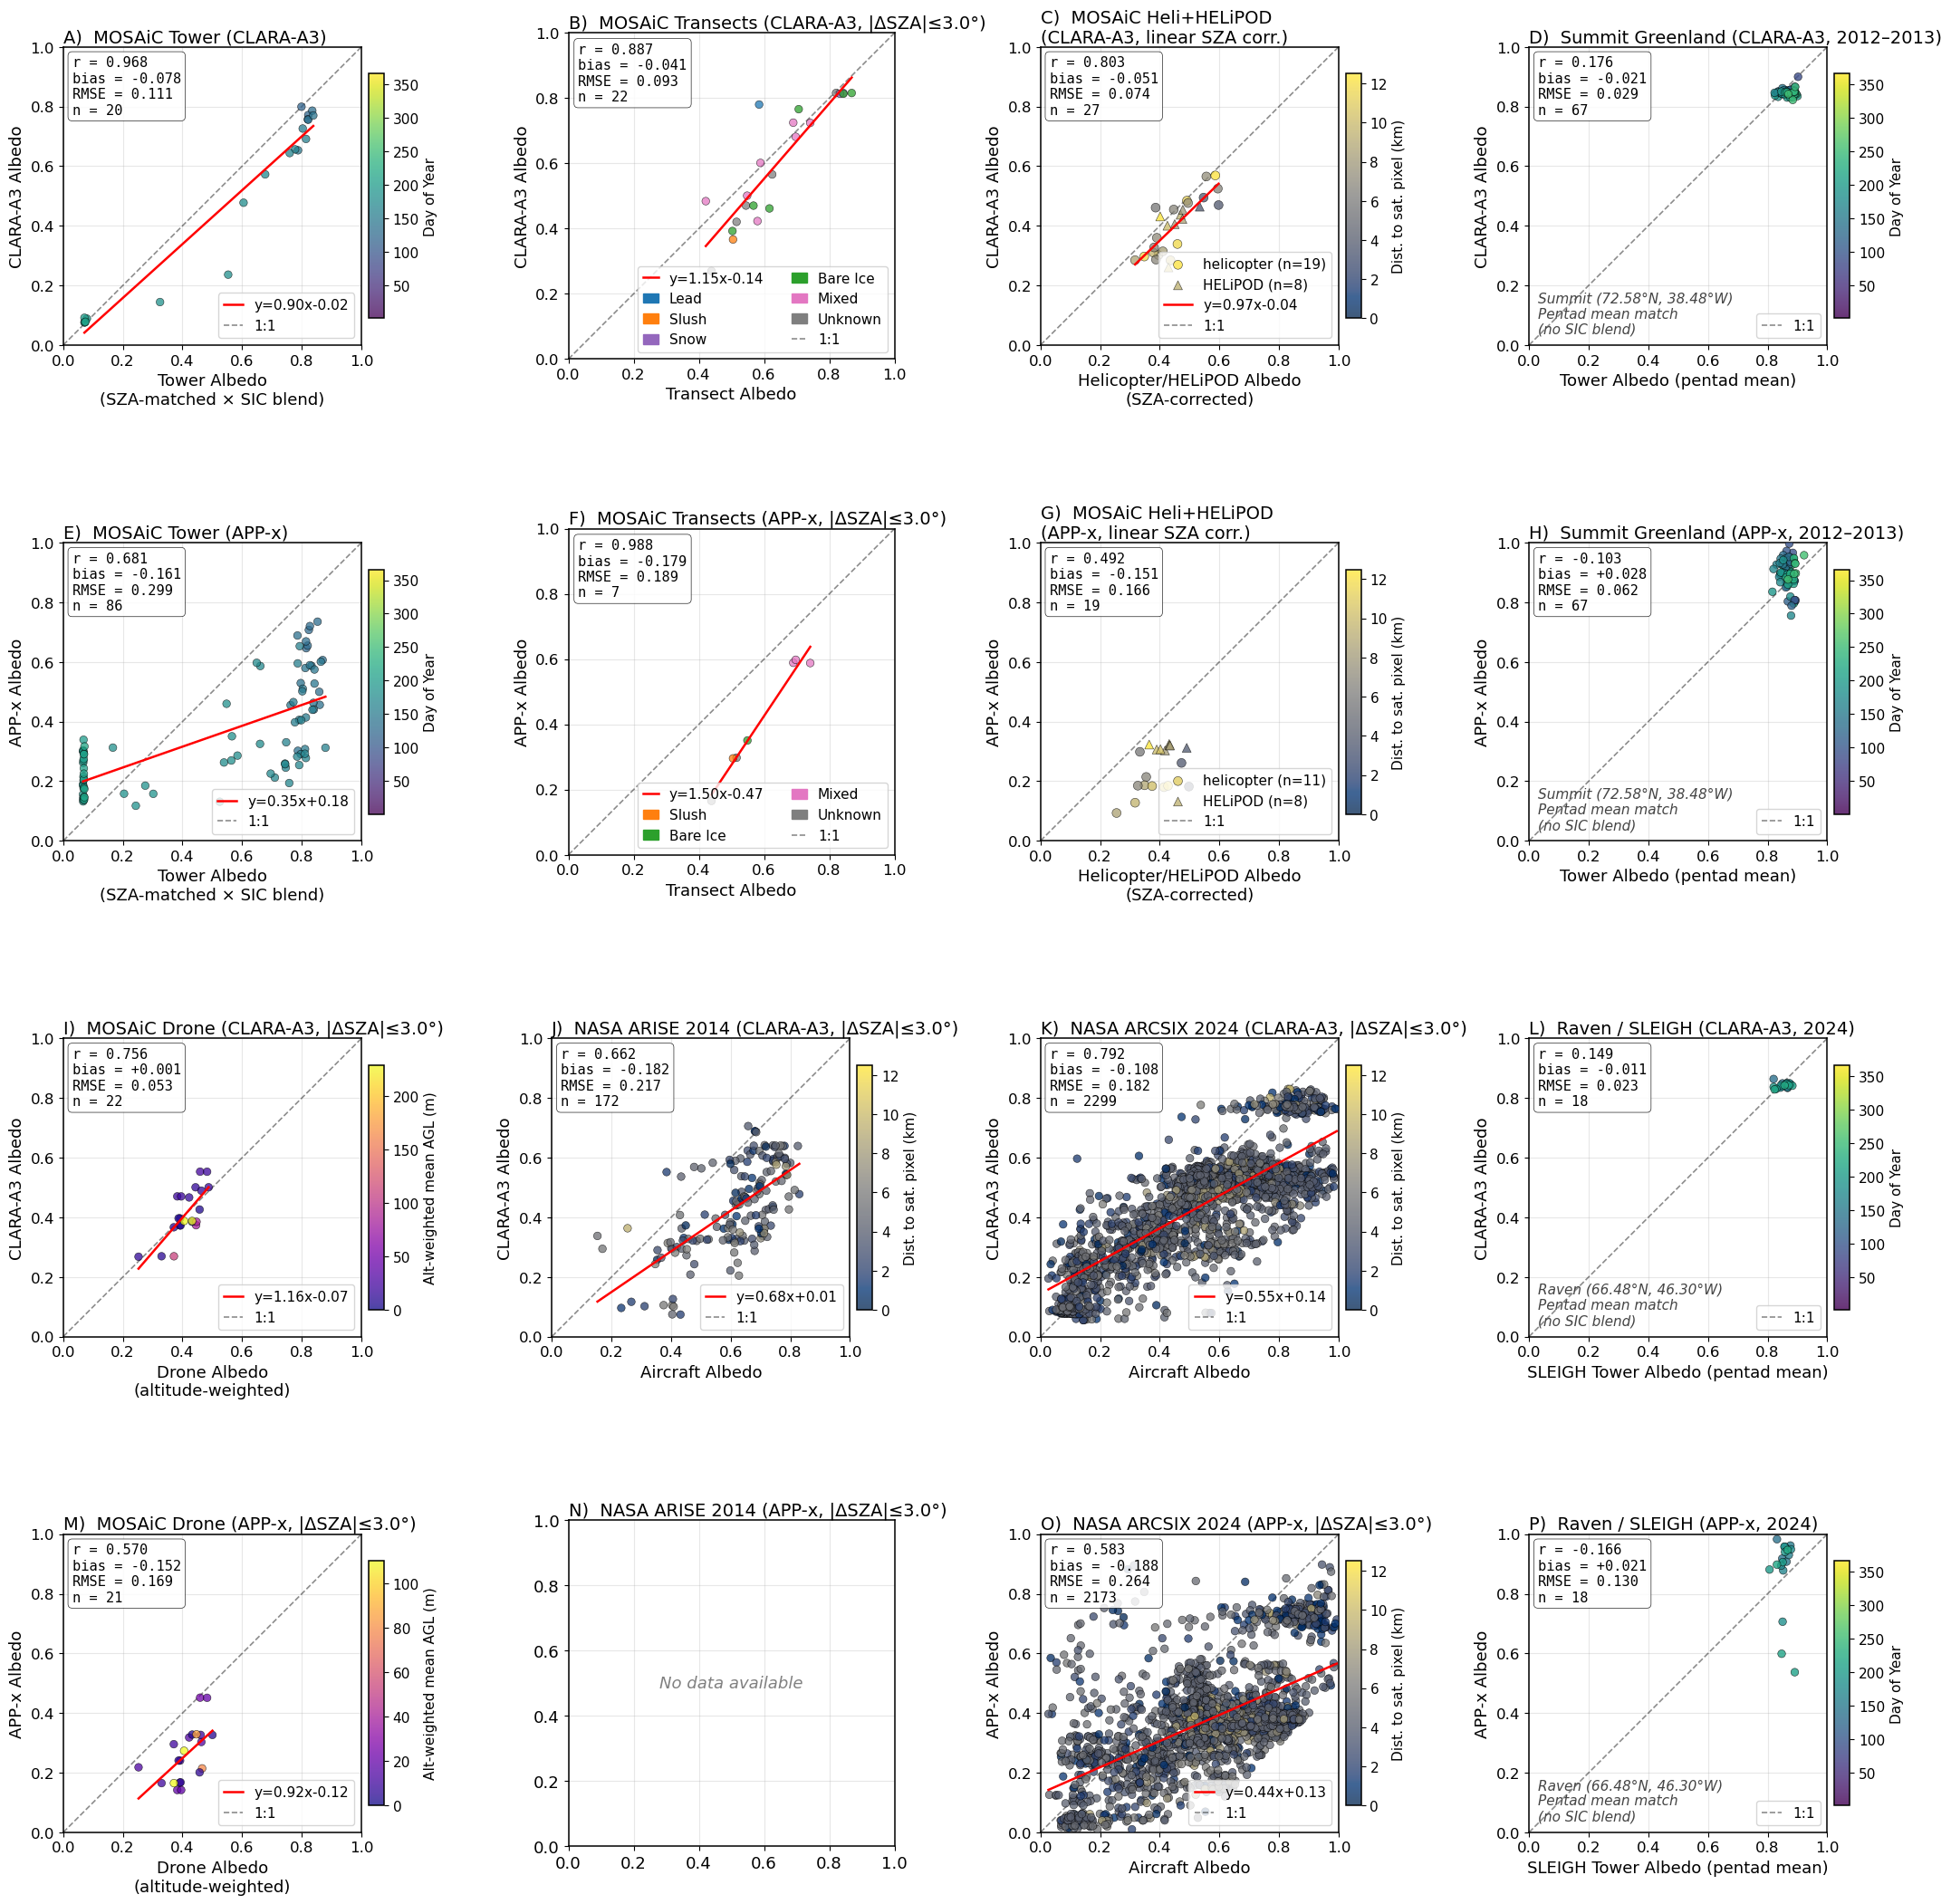

In [3]:
# %% [markdown]
# # 16-Panel In-Situ Validation: CLARA-A3 and APP-x
# Load pre-computed data from `save_validation_data.py` and render the figure.

# %%
import pickle
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D

# ── Font size constants ────────────────────────────────────────────────────────
FS_TITLE  = 14   # panel title (letter + name)
FS_LABEL  = 13   # axis labels
FS_TICK   = 12   # tick labels
FS_STATS  = 11   # stats text box
FS_LEGEND = 11   # legend entries
FS_CB     = 11   # colorbar label & ticks
FS_NOTE   = 11   # italic site notes

plt.rcParams.update({
    'font.size': FS_LABEL,
    'font.family': 'sans-serif',
    'axes.linewidth': 1.1,
    'grid.alpha': 0.3,
})

# %% [markdown]
# ## Load pickle

# %%
PKL_PATH = "/glade/work/jrotondo/combined_validation/validation_data.pkl"

with open(PKL_PATH, 'rb') as f:
    D = pickle.load(f)

# Unpack DataFrames
df_tower_c   = D['df_tower_c'];   df_tower_a   = D['df_tower_a']
df_transect_c= D['df_transect_c'];df_transect_a= D['df_transect_a']
df_heli_c    = D['df_heli_c'];    df_heli_a    = D['df_heli_a']
df_summit_c  = D['df_summit_c'];  df_summit_a  = D['df_summit_a']
df_raven_c   = D['df_raven_c'];   df_raven_a   = D['df_raven_a']
df_drone_c   = D['df_drone_c'];   df_drone_a   = D['df_drone_a']
df_arise_c   = D['df_arise_c'];   df_arise_a   = D['df_arise_a']
df_arcsix_c  = D['df_arcsix_c'];  df_arcsix_a  = D['df_arcsix_a']

# Unpack arrays
x_tower_c  = D['x_tower_c'];  y_tower_c  = D['y_tower_c'];  doy_tower_c = D['doy_tower_c']
x_tower_a  = D['x_tower_a'];  y_tower_a  = D['y_tower_a'];  doy_tower_a = D['doy_tower_a']

# Unpack stats
stats_tower_c   = D['stats_tower_c'];   stats_tower_a   = D['stats_tower_a']
stats_transect_c= D['stats_transect_c'];stats_transect_a= D['stats_transect_a']
stats_heli_c    = D['stats_heli_c'];    stats_heli_a    = D['stats_heli_a']
stats_summit_c  = D['stats_summit_c'];  stats_summit_a  = D['stats_summit_a']
stats_raven_c   = D['stats_raven_c'];   stats_raven_a   = D['stats_raven_a']
stats_drone_c   = D['stats_drone_c'];   stats_drone_a   = D['stats_drone_a']
stats_arise_c   = D['stats_arise_c'];   stats_arise_a   = D['stats_arise_a']
stats_arcsix_c  = D['stats_arcsix_c'];  stats_arcsix_a  = D['stats_arcsix_a']

# Unpack metadata
MAX_SZA         = D['MAX_SZA']
MAX_DELTA_SZA   = D['MAX_DELTA_SZA']
MAX_DIST_HELI   = D['MAX_DIST_HELI']
MAX_DIST_ARISE  = D['MAX_DIST_ARISE']
MAX_DIST_ARCSIX = D['MAX_DIST_ARCSIX']
SUMMIT_LAT      = D['SUMMIT_LAT'];  SUMMIT_LON = D['SUMMIT_LON']
RAVEN_LAT       = D['RAVEN_LAT'];   RAVEN_LON  = D['RAVEN_LON']
SURFACE_COLORS  = D['SURFACE_COLORS']
SURFACE_PRIORITY= D['SURFACE_PRIORITY']
valid_surf      = D['valid_surf']
output_dir      = D['output_dir']

# %% [markdown]
# ## Rebuild surface-type legend patches

# %%
surf_patches = [
    mpatches.Patch(color=SURFACE_COLORS.get(s, '#7f7f7f'), label=s.title())
    for s in valid_surf
]

surf_patches_a = [
    mpatches.Patch(color=SURFACE_COLORS.get(s, '#7f7f7f'), label=s.title())
    for s in SURFACE_PRIORITY + ['unknown']
    if len(df_transect_a) and s in df_transect_a['surface_type'].values
]

# %% [markdown]
# ## Drawing helpers

# %%
def _stats_text(s):
    return (f"r = {s['r']:.3f}\nbias = {s['bias']:+.3f}\n"
            f"RMSE = {s['rmse']:.3f}\nn = {s['n']}")


def _add_trend(ax, x, y):
    x = np.asarray(x, dtype=float); y = np.asarray(y, dtype=float)
    valid = np.isfinite(x) & np.isfinite(y)
    if valid.sum() < 2:
        return np.nan, np.nan
    r = float(np.corrcoef(x[valid], y[valid])[0, 1])
    if r < 0.5:
        return np.nan, np.nan
    z  = np.polyfit(x[valid], y[valid], 1)
    xf = np.linspace(float(x[valid].min()), float(x[valid].max()), 200)
    ax.plot(xf, np.polyval(z, xf), 'r-', lw=1.8, zorder=4,
            label=f'y={z[0]:.2f}x{z[1]:+.2f}')
    return z[0], z[1]


def _frame_ax(ax, s_d, panel_label, title, xlabel, ylabel,
              xlim=(0, 1), ylim=(0, 1)):
    lo = max(xlim[0], ylim[0]); hi = min(xlim[1], ylim[1])
    ax.plot([lo, hi], [lo, hi], 'k--', lw=1.2, alpha=0.45, zorder=2, label='1:1')
    ax.set_xlabel(xlabel, fontsize=FS_LABEL)
    ax.set_ylabel(ylabel, fontsize=FS_LABEL)
    ax.set_xlim(xlim); ax.set_ylim(ylim)
    ax.set_aspect('equal'); ax.grid(True, alpha=0.3)
    ax.tick_params(labelsize=FS_TICK)
    ax.text(0.03, 0.97, _stats_text(s_d), transform=ax.transAxes,
            fontsize=FS_STATS, va='top', ha='left', family='monospace',
            bbox=dict(boxstyle='round,pad=0.3', fc='white', alpha=0.85, lw=0.5))
    ax.set_title(f'{panel_label}  {title}', loc='left', fontsize=FS_TITLE, pad=4)


def draw_panel(ax, x, y, c_vals, cmap, norm, s_d,
               panel_label, title, xlabel, ylabel,
               colorbar_label=None, xlim=(0, 1), ylim=(0, 1)):
    x = np.asarray(x, dtype=float); y = np.asarray(y, dtype=float)
    sc = ax.scatter(x, y, c=c_vals, cmap=cmap, norm=norm,
                    s=38, edgecolors='k', linewidth=0.4, alpha=0.75, zorder=3)
    _add_trend(ax, x, y)
    _frame_ax(ax, s_d, panel_label, title, xlabel, ylabel, xlim=xlim, ylim=ylim)
    ax.legend(fontsize=FS_LEGEND, loc='lower right', framealpha=0.8, handlelength=1.4)
    if colorbar_label is not None:
        cb = fig.colorbar(sc, ax=ax, pad=0.02, shrink=0.75, aspect=16)
        cb.set_label(colorbar_label, fontsize=FS_CB)
        cb.ax.tick_params(labelsize=FS_CB)
    return sc


def draw_surface_panel(ax, x, y, surface_col, surf_patches_,
                        s_d, panel_label, title, xlabel, ylabel):
    x = np.asarray(x, dtype=float); y = np.asarray(y, dtype=float)
    c_vals = [SURFACE_COLORS.get(s, '#7f7f7f') for s in surface_col]
    ax.scatter(x, y, c=c_vals, s=38, edgecolors='k',
               linewidth=0.4, alpha=0.75, zorder=3)
    z0, z1 = _add_trend(ax, x, y)
    _frame_ax(ax, s_d, panel_label, title, xlabel, ylabel)
    handles = surf_patches_[:]
    if np.isfinite(z0):
        handles = [Line2D([0], [0], color='r', lw=1.8,
                          label=f'y={z0:.2f}x{z1:+.2f}')] + handles
    handles += [Line2D([0], [0], color='k', ls='--', lw=1.2,
                       alpha=0.45, label='1:1')]
    ax.legend(handles=handles, fontsize=FS_LEGEND, loc='lower right',
              framealpha=0.8, ncol=2, handlelength=1.1)


def draw_greenland_panel(ax, x, y, doy, s_d,
                          panel_label, title, xlabel, ylabel, site_label=''):
    x = np.asarray(x, dtype=float); y = np.asarray(y, dtype=float)
    sc = ax.scatter(x, y, c=doy, cmap='viridis',
                    norm=plt.Normalize(vmin=1, vmax=366),
                    s=38, edgecolors='k', linewidth=0.4, alpha=0.8, zorder=3)
    _add_trend(ax, x, y)
    _frame_ax(ax, s_d, panel_label, title, xlabel, ylabel,
              xlim=(0, 1), ylim=(0, 1))
    if site_label:
        ax.text(0.03, 0.03, f'{site_label}\nPentad mean match\n(no SIC blend)',
                transform=ax.transAxes, fontsize=FS_NOTE, va='bottom', ha='left',
                style='italic', color='#444444')
    ax.legend(fontsize=FS_LEGEND, loc='lower right', framealpha=0.8, handlelength=1.4)
    cb = fig.colorbar(sc, ax=ax, pad=0.02, shrink=0.75, aspect=16)
    cb.set_label('Day of Year', fontsize=FS_CB)
    cb.ax.tick_params(labelsize=FS_CB)


def no_data_panel(ax, panel_label, title, reason='No data available'):
    ax.text(0.5, 0.5, reason, ha='center', va='center',
            transform=ax.transAxes, fontsize=FS_LABEL, color='gray', style='italic')
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect('equal')
    ax.grid(True, alpha=0.3)
    ax.set_title(f'{panel_label}  {title}', loc='left', fontsize=FS_TITLE, pad=4)

# %% [markdown]
# ## Create figure

# %%
fig, axes = plt.subplots(4, 4, figsize=(26, 26),
                          gridspec_kw={'hspace': 0.52, 'wspace': 0.36})

CLARA_Y = 'CLARA-A3 Albedo'
APPX_Y  = 'APP-x Albedo'

# %% [markdown]
# ### Row 0 — CLARA-A3: Tower | Transects | Helicopter | Summit

# %%
# A) Tower CLARA-A3
ax = axes[0, 0]
if len(x_tower_c) > 0:
    draw_panel(ax, x_tower_c, y_tower_c, doy_tower_c,
               'viridis', plt.Normalize(1, 366), stats_tower_c,
               'A)', 'MOSAiC Tower (CLARA-A3)',
               'Tower Albedo\n(SZA-matched × SIC blend)', CLARA_Y,
               colorbar_label='Day of Year')
else:
    no_data_panel(ax, 'A)', 'MOSAiC Tower (CLARA-A3)')

# B) Transects CLARA-A3
ax = axes[0, 1]
if len(df_transect_c) > 0:
    draw_surface_panel(ax,
        df_transect_c['transect_albedo'].values,
        df_transect_c['sat_albedo'].values,
        df_transect_c['surface_type'].values,
        surf_patches, stats_transect_c,
        'B)', f'MOSAiC Transects (CLARA-A3, |ΔSZA|≤{MAX_DELTA_SZA}°)',
        'Transect Albedo', CLARA_Y)
else:
    no_data_panel(ax, 'B)', f'MOSAiC Transects (CLARA-A3, |ΔSZA|≤{MAX_DELTA_SZA}°)')

# C) Helicopter CLARA-A3
ax = axes[0, 2]
if len(df_heli_c) > 0 and 'heli_albedo_corr' in df_heli_c.columns:
    df_ch   = df_heli_c[df_heli_c['heli_albedo_corr'].notna()].copy()
    norm_ch = plt.Normalize(vmin=0, vmax=MAX_DIST_HELI)
    sc_ch   = None
    for instr, mkr in {'helicopter': 'o', 'HELiPOD': '^'}.items():
        sub = df_ch[df_ch['instrument'] == instr]
        if sub.empty: continue
        sc_ch = ax.scatter(sub['heli_albedo_corr'], sub['sat_albedo'],
                           c=sub['mean_dist_km'], cmap='cividis', norm=norm_ch,
                           s=50, marker=mkr, edgecolors='k', linewidth=0.4,
                           alpha=0.75, zorder=3, label=f'{instr} (n={len(sub)})')
    _add_trend(ax, df_ch['heli_albedo_corr'].values, df_ch['sat_albedo'].values)
    _frame_ax(ax, stats_heli_c, 'C)',
              'MOSAiC Heli+HELiPOD\n(CLARA-A3, linear SZA corr.)',
              'Helicopter/HELiPOD Albedo\n(SZA-corrected)', CLARA_Y)
    ax.legend(fontsize=FS_LEGEND, loc='lower right', framealpha=0.8)
    if sc_ch is not None:
        cb = fig.colorbar(sc_ch, ax=ax, pad=0.02, shrink=0.75, aspect=16)
        cb.set_label('Dist. to sat. pixel (km)', fontsize=FS_CB)
        cb.ax.tick_params(labelsize=FS_CB)
else:
    no_data_panel(ax, 'C)', 'MOSAiC Heli+HELiPOD (CLARA-A3)')

# D) Summit CLARA-A3
ax = axes[0, 3]
if len(df_summit_c) > 0:
    draw_greenland_panel(ax,
        df_summit_c['tower_albedo'].values, df_summit_c['sat_albedo'].values,
        df_summit_c['doy'].values, stats_summit_c,
        'D)', 'Summit Greenland (CLARA-A3, 2012–2013)',
        'Tower Albedo (pentad mean)', CLARA_Y,
        site_label=f'Summit ({SUMMIT_LAT:.2f}°N, {abs(SUMMIT_LON):.2f}°W)')
else:
    no_data_panel(ax, 'D)', 'Summit Greenland (CLARA-A3, 2012–2013)')

# %% [markdown]
# ### Row 1 — APP-x: Tower | Transects | Helicopter | Summit

# %%
# E) Tower APP-x
ax = axes[1, 0]
if len(x_tower_a) > 0:
    draw_panel(ax, x_tower_a, y_tower_a, doy_tower_a,
               'viridis', plt.Normalize(1, 366), stats_tower_a,
               'E)', 'MOSAiC Tower (APP-x)',
               'Tower Albedo\n(SZA-matched × SIC blend)', APPX_Y,
               colorbar_label='Day of Year')
else:
    no_data_panel(ax, 'E)', 'MOSAiC Tower (APP-x)')

# F) Transects APP-x
ax = axes[1, 1]
if len(df_transect_a) > 0:
    draw_surface_panel(ax,
        df_transect_a['transect_albedo'].values,
        df_transect_a['sat_albedo'].values,
        df_transect_a['surface_type'].values,
        surf_patches_a, stats_transect_a,
        'F)', f'MOSAiC Transects (APP-x, |ΔSZA|≤{MAX_DELTA_SZA}°)',
        'Transect Albedo', APPX_Y)
else:
    no_data_panel(ax, 'F)', f'MOSAiC Transects (APP-x, |ΔSZA|≤{MAX_DELTA_SZA}°)')

# G) Helicopter APP-x
ax = axes[1, 2]
if len(df_heli_a) > 0 and 'heli_albedo_corr' in df_heli_a.columns:
    df_ah   = df_heli_a[df_heli_a['heli_albedo_corr'].notna()].copy()
    norm_ah = plt.Normalize(vmin=0, vmax=MAX_DIST_HELI)
    sc_ah   = None
    for instr, mkr in {'helicopter': 'o', 'HELiPOD': '^'}.items():
        sub = df_ah[df_ah['instrument'] == instr]
        if sub.empty: continue
        sc_ah = ax.scatter(sub['heli_albedo_corr'], sub['sat_albedo'],
                           c=sub['mean_dist_km'], cmap='cividis', norm=norm_ah,
                           s=50, marker=mkr, edgecolors='k', linewidth=0.4,
                           alpha=0.75, zorder=3, label=f'{instr} (n={len(sub)})')
    _add_trend(ax, df_ah['heli_albedo_corr'].values, df_ah['sat_albedo'].values)
    _frame_ax(ax, stats_heli_a, 'G)',
              'MOSAiC Heli+HELiPOD\n(APP-x, linear SZA corr.)',
              'Helicopter/HELiPOD Albedo\n(SZA-corrected)', APPX_Y)
    ax.legend(fontsize=FS_LEGEND, loc='lower right', framealpha=0.8)
    if sc_ah is not None:
        cb = fig.colorbar(sc_ah, ax=ax, pad=0.02, shrink=0.75, aspect=16)
        cb.set_label('Dist. to sat. pixel (km)', fontsize=FS_CB)
        cb.ax.tick_params(labelsize=FS_CB)
else:
    no_data_panel(ax, 'G)', 'MOSAiC Heli+HELiPOD (APP-x)')

# H) Summit APP-x
ax = axes[1, 3]
if len(df_summit_a) > 0:
    draw_greenland_panel(ax,
        df_summit_a['tower_albedo'].values, df_summit_a['sat_albedo'].values,
        df_summit_a['doy'].values, stats_summit_a,
        'H)', 'Summit Greenland (APP-x, 2012–2013)',
        'Tower Albedo (pentad mean)', APPX_Y,
        site_label=f'Summit ({SUMMIT_LAT:.2f}°N, {abs(SUMMIT_LON):.2f}°W)')
else:
    no_data_panel(ax, 'H)', 'Summit Greenland (APP-x, 2012–2013)')

# %% [markdown]
# ### Row 2 — CLARA-A3: Drone | ARISE | ARCSIX | Raven

# %%
# I) Drone CLARA-A3
ax = axes[2, 0]
if len(df_drone_c) > 0:
    alt_vals = df_drone_c['alt_mean_w'].values
    draw_panel(ax,
        df_drone_c['drone_albedo'].values, df_drone_c['sat_albedo'].values,
        alt_vals, 'plasma',
        plt.Normalize(vmin=0, vmax=float(np.nanpercentile(alt_vals, 95))),
        stats_drone_c,
        'I)', f'MOSAiC Drone (CLARA-A3, |ΔSZA|≤{MAX_DELTA_SZA}°)',
        'Drone Albedo\n(altitude-weighted)', CLARA_Y,
        colorbar_label='Alt-weighted mean AGL (m)')
else:
    no_data_panel(ax, 'I)', f'MOSAiC Drone (CLARA-A3, |ΔSZA|≤{MAX_DELTA_SZA}°)')

# J) ARISE CLARA-A3
ax = axes[2, 1]
if len(df_arise_c) > 0:
    draw_panel(ax,
        df_arise_c['aircraft_albedo'].values, df_arise_c['sat_albedo'].values,
        df_arise_c['mean_dist_km'].values,
        'cividis', plt.Normalize(vmin=0, vmax=MAX_DIST_ARISE), stats_arise_c,
        'J)', f'NASA ARISE 2014 (CLARA-A3, |ΔSZA|≤{MAX_DELTA_SZA}°)',
        'Aircraft Albedo', CLARA_Y,
        colorbar_label='Dist. to sat. pixel (km)')
else:
    no_data_panel(ax, 'J)', f'NASA ARISE 2014 (CLARA-A3, |ΔSZA|≤{MAX_DELTA_SZA}°)')

# K) ARCSIX CLARA-A3
ax = axes[2, 2]
if len(df_arcsix_c) > 0:
    draw_panel(ax,
        df_arcsix_c['aircraft_albedo'].values, df_arcsix_c['sat_albedo'].values,
        df_arcsix_c['mean_dist_km'].values,
        'cividis', plt.Normalize(vmin=0, vmax=MAX_DIST_ARCSIX), stats_arcsix_c,
        'K)', f'NASA ARCSIX 2024 (CLARA-A3, |ΔSZA|≤{MAX_DELTA_SZA}°)',
        'Aircraft Albedo', CLARA_Y,
        colorbar_label='Dist. to sat. pixel (km)')
else:
    no_data_panel(ax, 'K)', f'NASA ARCSIX 2024 (CLARA-A3, |ΔSZA|≤{MAX_DELTA_SZA}°)')

# L) Raven CLARA-A3
ax = axes[2, 3]
if len(df_raven_c) > 0:
    draw_greenland_panel(ax,
        df_raven_c['tower_albedo'].values, df_raven_c['sat_albedo'].values,
        df_raven_c['doy'].values, stats_raven_c,
        'L)', 'Raven / SLEIGH (CLARA-A3, 2024)',
        'SLEIGH Tower Albedo (pentad mean)', CLARA_Y,
        site_label=f'Raven ({RAVEN_LAT:.2f}°N, {abs(RAVEN_LON):.2f}°W)')
else:
    no_data_panel(ax, 'L)', 'Raven / SLEIGH (CLARA-A3, 2024)')

# %% [markdown]
# ### Row 3 — APP-x: Drone | ARISE | ARCSIX | Raven

# %%
# M) Drone APP-x
ax = axes[3, 0]
if len(df_drone_a) > 0:
    alt_vals_a = df_drone_a['alt_mean_w'].values
    draw_panel(ax,
        df_drone_a['drone_albedo'].values, df_drone_a['sat_albedo'].values,
        alt_vals_a, 'plasma',
        plt.Normalize(vmin=0, vmax=float(np.nanpercentile(alt_vals_a, 95))),
        stats_drone_a,
        'M)', f'MOSAiC Drone (APP-x, |ΔSZA|≤{MAX_DELTA_SZA}°)',
        'Drone Albedo\n(altitude-weighted)', APPX_Y,
        colorbar_label='Alt-weighted mean AGL (m)')
else:
    no_data_panel(ax, 'M)', f'MOSAiC Drone (APP-x, |ΔSZA|≤{MAX_DELTA_SZA}°)')

# N) ARISE APP-x
ax = axes[3, 1]
if len(df_arise_a) > 0:
    draw_panel(ax,
        df_arise_a['aircraft_albedo'].values, df_arise_a['sat_albedo'].values,
        df_arise_a['mean_dist_km'].values,
        'cividis', plt.Normalize(vmin=0, vmax=MAX_DIST_ARISE), stats_arise_a,
        'N)', f'NASA ARISE 2014 (APP-x, |ΔSZA|≤{MAX_DELTA_SZA}°)',
        'Aircraft Albedo', APPX_Y,
        colorbar_label='Dist. to sat. pixel (km)')
else:
    no_data_panel(ax, 'N)', f'NASA ARISE 2014 (APP-x, |ΔSZA|≤{MAX_DELTA_SZA}°)')

# O) ARCSIX APP-x
ax = axes[3, 2]
if len(df_arcsix_a) > 0:
    draw_panel(ax,
        df_arcsix_a['aircraft_albedo'].values, df_arcsix_a['sat_albedo'].values,
        df_arcsix_a['mean_dist_km'].values,
        'cividis', plt.Normalize(vmin=0, vmax=MAX_DIST_ARCSIX), stats_arcsix_a,
        'O)', f'NASA ARCSIX 2024 (APP-x, |ΔSZA|≤{MAX_DELTA_SZA}°)',
        'Aircraft Albedo', APPX_Y,
        colorbar_label='Dist. to sat. pixel (km)')
else:
    no_data_panel(ax, 'O)', f'NASA ARCSIX 2024 (APP-x, |ΔSZA|≤{MAX_DELTA_SZA}°)')

# P) Raven APP-x
ax = axes[3, 3]
if len(df_raven_a) > 0:
    draw_greenland_panel(ax,
        df_raven_a['tower_albedo'].values, df_raven_a['sat_albedo'].values,
        df_raven_a['doy'].values, stats_raven_a,
        'P)', 'Raven / SLEIGH (APP-x, 2024)',
        'SLEIGH Tower Albedo (pentad mean)', APPX_Y,
        site_label=f'Raven ({RAVEN_LAT:.2f}°N, {abs(RAVEN_LON):.2f}°W)')
else:
    no_data_panel(ax, 'P)', 'Raven / SLEIGH (APP-x, 2024)')

# %% [markdown]
# ## Save figure

# %%
import os
outpath = os.path.join(output_dir, 'combined_16panel_validation.png')
fig.savefig(outpath, dpi=200, bbox_inches='tight')
print(f"Saved → {outpath}")
fig.show()

# %% [markdown]
# ## Summary table

# %%
all_stats_list = [
    ('A', 'MOSAiC Tower (SZA-matched, SIC blend)',              'CLARA-A3', stats_tower_c),
    ('B', f'MOSAiC Transects (|ΔSZA|≤{MAX_DELTA_SZA}°)',       'CLARA-A3', stats_transect_c),
    ('C', 'MOSAiC Helicopter+HELiPOD (linear SZA corr.)',       'CLARA-A3', stats_heli_c),
    ('D', 'Summit Greenland 2012–13 (pentad mean)',              'CLARA-A3', stats_summit_c),
    ('E', 'MOSAiC Tower (SZA-matched, SIC blend)',              'APP-x',    stats_tower_a),
    ('F', f'MOSAiC Transects (|ΔSZA|≤{MAX_DELTA_SZA}°)',       'APP-x',    stats_transect_a),
    ('G', 'MOSAiC Helicopter+HELiPOD (linear SZA corr.)',       'APP-x',    stats_heli_a),
    ('H', 'Summit Greenland 2012–13 (pentad mean)',              'APP-x',    stats_summit_a),
    ('I', f'HELiX Drone (|ΔSZA|≤{MAX_DELTA_SZA}°)',            'CLARA-A3', stats_drone_c),
    ('J', f'ARISE 2014 nobs_snow>0 (|ΔSZA|≤{MAX_DELTA_SZA}°)','CLARA-A3', stats_arise_c),
    ('K', f'ARCSIX 2024 (|ΔSZA|≤{MAX_DELTA_SZA}°)',            'CLARA-A3', stats_arcsix_c),
    ('L', 'Raven Greenland 2024 SLEIGH (pentad mean)',           'CLARA-A3', stats_raven_c),
    ('M', f'HELiX Drone (|ΔSZA|≤{MAX_DELTA_SZA}°)',            'APP-x',    stats_drone_a),
    ('N', f'ARISE 2014 (|ΔSZA|≤{MAX_DELTA_SZA}°)',             'APP-x',    stats_arise_a),
    ('O', f'ARCSIX 2024 (|ΔSZA|≤{MAX_DELTA_SZA}°)',            'APP-x',    stats_arcsix_a),
    ('P', 'Raven Greenland 2024 SLEIGH (pentad mean)',           'APP-x',    stats_raven_a),
]
print(f"{'Pan':<4}  {'Dataset':<42}  {'Product':<10}  {'r':>7}  {'bias':>8}  {'RMSE':>8}  {'n':>6}")
print("-" * 90)
for label, name, product, s in all_stats_list:
    r_s    = f"{s['r']:7.3f}"     if np.isfinite(s['r'])    else '    nan'
    bias_s = f"{s['bias']:+8.4f}" if np.isfinite(s['bias']) else '     nan'
    rmse_s = f"{s['rmse']:8.4f}"  if np.isfinite(s['rmse']) else '     nan'
    print(f"  {label:<3}  {name:<42}  {product:<10}  {r_s}  {bias_s}  {rmse_s}  {s['n']:>6d}")

## Plot of just CLARA-A3

Saved → /glade/work/jrotondo/combined_validation/clara_8panel_validation_ppt.png


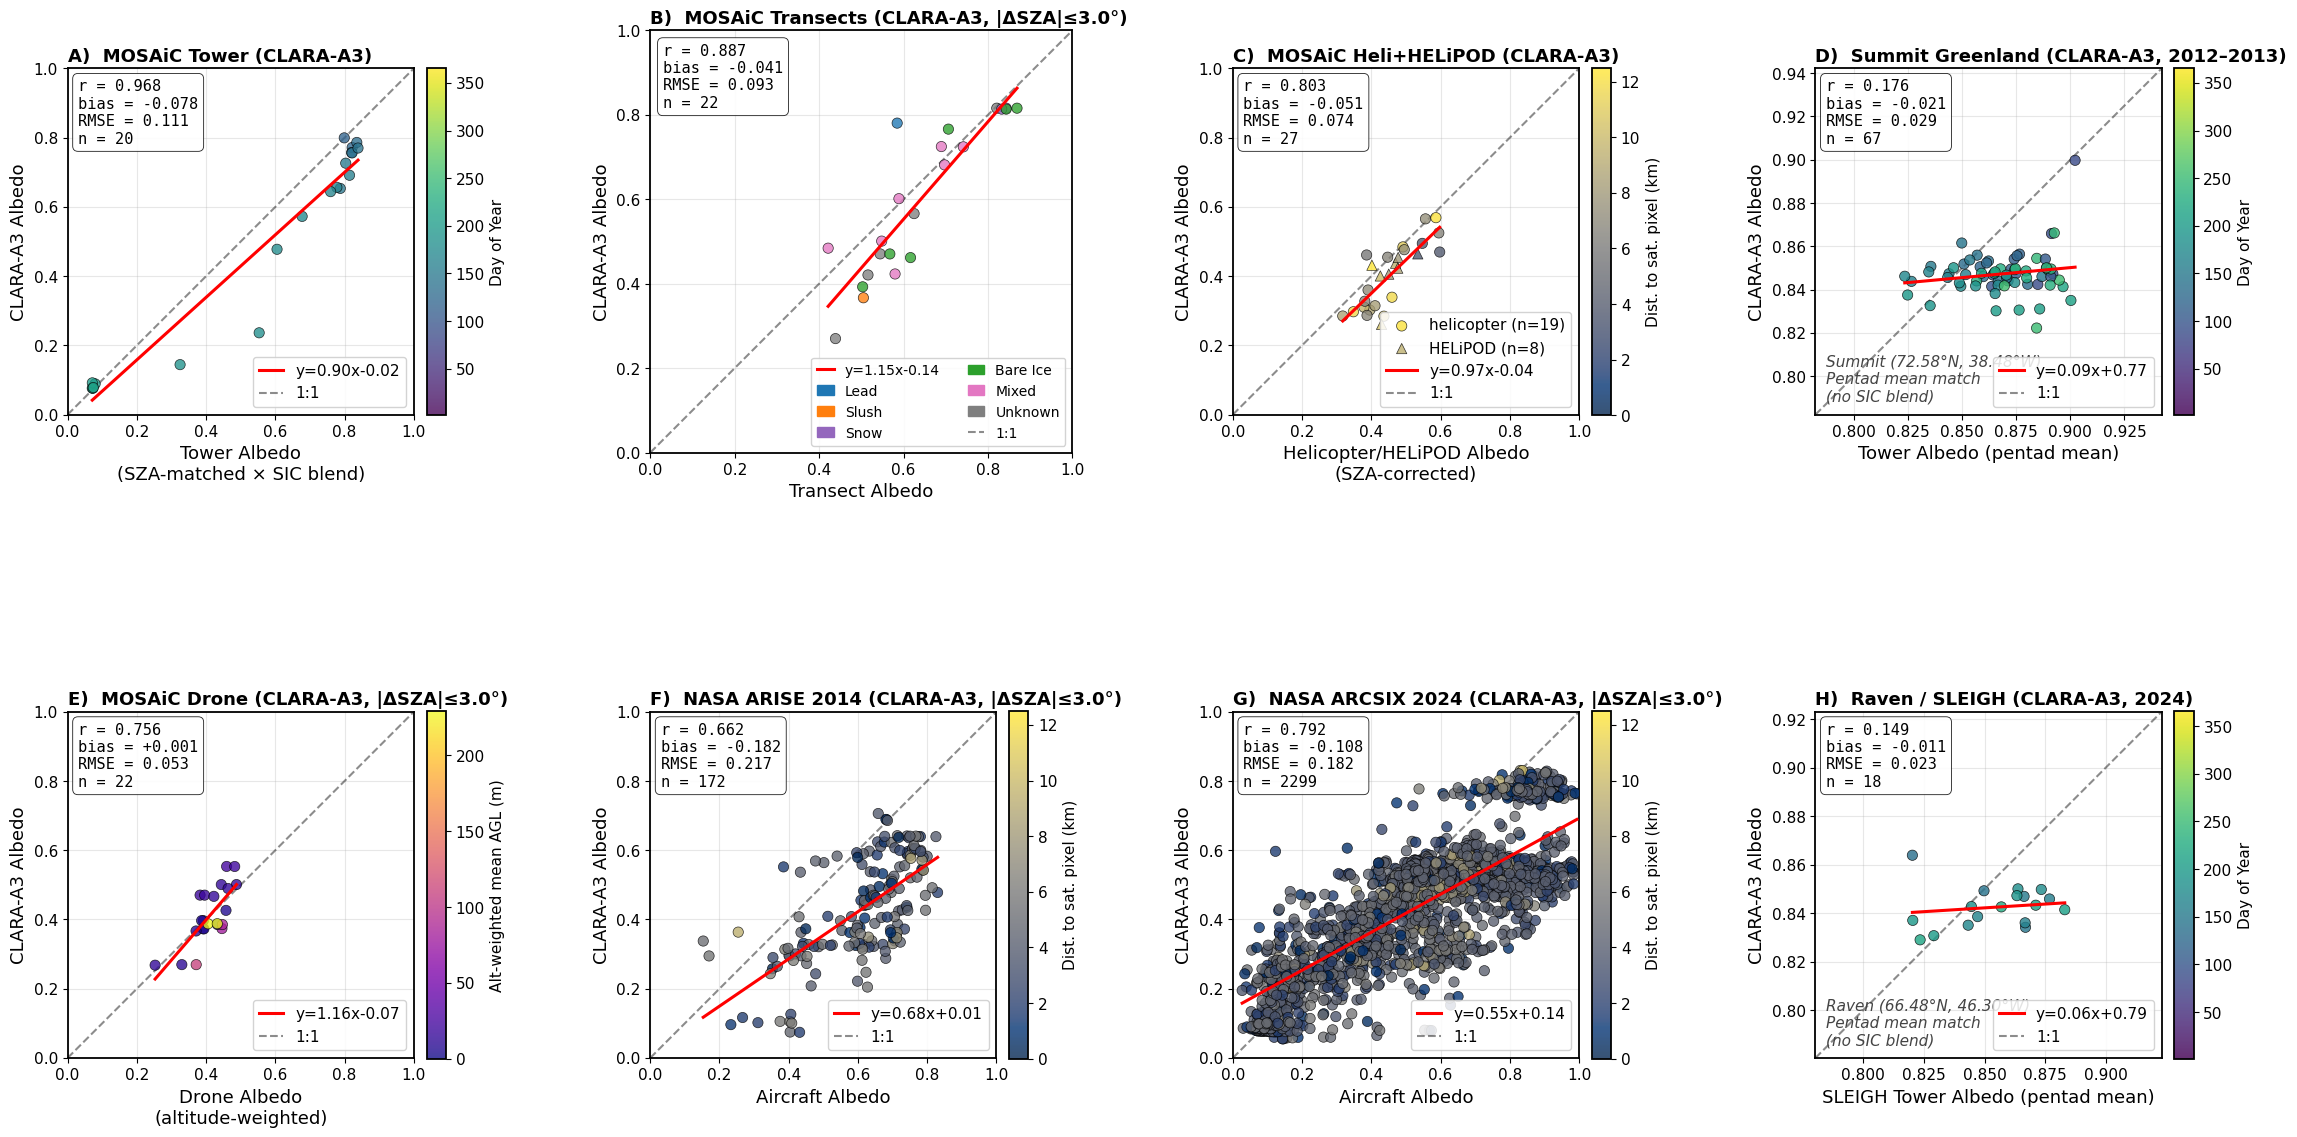

In [2]:
# %% [markdown]
# # 8-Panel In-Situ Validation: CLARA-A3 only (2-row PowerPoint layout)

# %%
import pickle, os
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D

plt.rcParams.update({
    'font.size': 18,
    'font.family': 'sans-serif',
    'axes.linewidth': 1.3,
    'grid.alpha': 0.3,
})

# %% [markdown]
# ## Load pickle

# %%
PKL_PATH = "/glade/work/jrotondo/combined_validation/validation_data.pkl"

with open(PKL_PATH, 'rb') as f:
    D = pickle.load(f)

df_tower_c    = D['df_tower_c']
df_transect_c = D['df_transect_c']
df_heli_c     = D['df_heli_c']
df_summit_c   = D['df_summit_c']
df_raven_c    = D['df_raven_c']
df_drone_c    = D['df_drone_c']
df_arise_c    = D['df_arise_c']
df_arcsix_c   = D['df_arcsix_c']

x_tower_c   = D['x_tower_c'];  y_tower_c   = D['y_tower_c'];  doy_tower_c = D['doy_tower_c']

stats_tower_c    = D['stats_tower_c']
stats_transect_c = D['stats_transect_c']
stats_heli_c     = D['stats_heli_c']
stats_summit_c   = D['stats_summit_c']
stats_raven_c    = D['stats_raven_c']
stats_drone_c    = D['stats_drone_c']
stats_arise_c    = D['stats_arise_c']
stats_arcsix_c   = D['stats_arcsix_c']

MAX_SZA         = D['MAX_SZA']
MAX_DELTA_SZA   = D['MAX_DELTA_SZA']
MAX_DIST_HELI   = D['MAX_DIST_HELI']
MAX_DIST_ARISE  = D['MAX_DIST_ARISE']
MAX_DIST_ARCSIX = D['MAX_DIST_ARCSIX']
SUMMIT_LAT      = D['SUMMIT_LAT'];  SUMMIT_LON = D['SUMMIT_LON']
RAVEN_LAT       = D['RAVEN_LAT'];   RAVEN_LON  = D['RAVEN_LON']
SURFACE_COLORS  = D['SURFACE_COLORS']
SURFACE_PRIORITY= D['SURFACE_PRIORITY']
valid_surf      = D['valid_surf']
output_dir      = D['output_dir']

# %% [markdown]
# ## Surface legend patches (CLARA-A3)

# %%
surf_patches = [
    mpatches.Patch(color=SURFACE_COLORS.get(s, '#7f7f7f'), label=s.title())
    for s in valid_surf
]

# %% [markdown]
# ## Drawing helpers

# %%
FS_STATS  = 11    # monospace stats box
FS_TICK   = 11
FS_LABEL  = 13
FS_TITLE  = 13
FS_LEGEND = 11
FS_CB     = 11
PT_SIZE   = 55    # scatter point size

CLARA_Y = 'CLARA-A3 Albedo'


def _stats_text(s):
    return (f"r = {s['r']:.3f}\nbias = {s['bias']:+.3f}\n"
            f"RMSE = {s['rmse']:.3f}\nn = {s['n']}")


def _add_trend(ax, x, y):
    x = np.asarray(x, dtype=float); y = np.asarray(y, dtype=float)
    valid = np.isfinite(x) & np.isfinite(y)
    if valid.sum() < 2:
        return np.nan, np.nan
    z  = np.polyfit(x[valid], y[valid], 1)
    xf = np.linspace(float(x[valid].min()), float(x[valid].max()), 200)
    ax.plot(xf, np.polyval(z, xf), 'r-', lw=2.2, zorder=4,
            label=f'y={z[0]:.2f}x{z[1]:+.2f}')
    return z[0], z[1]


def _frame_ax(ax, s_d, panel_label, title, xlabel, ylabel,
              xlim=(0, 1), ylim=(0, 1)):
    lo = max(xlim[0], ylim[0]); hi = min(xlim[1], ylim[1])
    ax.plot([lo, hi], [lo, hi], 'k--', lw=1.5, alpha=0.45, zorder=2, label='1:1')
    ax.set_xlabel(xlabel, fontsize=FS_LABEL)
    ax.set_ylabel(ylabel, fontsize=FS_LABEL)
    ax.set_xlim(xlim); ax.set_ylim(ylim)
    ax.set_aspect('equal'); ax.grid(True, alpha=0.3)
    ax.tick_params(labelsize=FS_TICK)
    ax.text(0.03, 0.97, _stats_text(s_d), transform=ax.transAxes,
            fontsize=FS_STATS, va='top', ha='left', family='monospace',
            bbox=dict(boxstyle='round,pad=0.35', fc='white', alpha=0.88, lw=0.6))
    ax.set_title(f'{panel_label}  {title}', loc='left',
                 fontsize=FS_TITLE, pad=5, fontweight='bold')


def draw_panel(ax, x, y, c_vals, cmap, norm, s_d,
               panel_label, title, xlabel, ylabel, colorbar_label=None,
               xlim=(0, 1), ylim=(0, 1)):
    x = np.asarray(x, dtype=float); y = np.asarray(y, dtype=float)
    sc = ax.scatter(x, y, c=c_vals, cmap=cmap, norm=norm,
                    s=PT_SIZE, edgecolors='k', linewidth=0.5, alpha=0.78, zorder=3)
    _add_trend(ax, x, y)
    _frame_ax(ax, s_d, panel_label, title, xlabel, ylabel, xlim=xlim, ylim=ylim)
    ax.legend(fontsize=FS_LEGEND, loc='lower right', framealpha=0.85, handlelength=1.6)
    if colorbar_label is not None:
        cb = fig.colorbar(sc, ax=ax, pad=0.03, shrink=0.80, aspect=18)
        cb.set_label(colorbar_label, fontsize=FS_CB)
        cb.ax.tick_params(labelsize=FS_CB)
    return sc


def draw_surface_panel(ax, x, y, surface_col, surf_patches_,
                        s_d, panel_label, title, xlabel, ylabel):
    x = np.asarray(x, dtype=float); y = np.asarray(y, dtype=float)
    c_vals = [SURFACE_COLORS.get(s, '#7f7f7f') for s in surface_col]
    ax.scatter(x, y, c=c_vals, s=PT_SIZE, edgecolors='k',
               linewidth=0.5, alpha=0.78, zorder=3)
    z0, z1 = _add_trend(ax, x, y)
    _frame_ax(ax, s_d, panel_label, title, xlabel, ylabel)
    handles = surf_patches_[:]
    if np.isfinite(z0):
        handles = [Line2D([0], [0], color='r', lw=2.2,
                          label=f'y={z0:.2f}x{z1:+.2f}')] + handles
    handles += [Line2D([0], [0], color='k', ls='--', lw=1.5,
                       alpha=0.45, label='1:1')]
    ax.legend(handles=handles, fontsize=FS_LEGEND - 1, loc='lower right',
              framealpha=0.85, ncol=2, handlelength=1.2)


def draw_greenland_panel(ax, x, y, doy, s_d,
                          panel_label, title, xlabel, ylabel, site_label=''):
    x = np.asarray(x, dtype=float); y = np.asarray(y, dtype=float)
    valid = np.isfinite(x) & np.isfinite(y)
    if valid.sum() > 0:
        pad  = 0.04
        dmin = max(0.0, min(x[valid].min(), y[valid].min()) - pad)
        dmax = min(1.0, max(x[valid].max(), y[valid].max()) + pad)
    else:
        dmin, dmax = 0.5, 1.0
    sc = ax.scatter(x, y, c=doy, cmap='viridis',
                    norm=plt.Normalize(vmin=1, vmax=366),
                    s=PT_SIZE, edgecolors='k', linewidth=0.5, alpha=0.82, zorder=3)
    _add_trend(ax, x, y)
    _frame_ax(ax, s_d, panel_label, title, xlabel, ylabel,
              xlim=(dmin, dmax), ylim=(dmin, dmax))
    if site_label:
        ax.text(0.03, 0.03, f'{site_label}\nPentad mean match\n(no SIC blend)',
                transform=ax.transAxes, fontsize=FS_STATS, va='bottom', ha='left',
                style='italic', color='#444444')
    ax.legend(fontsize=FS_LEGEND, loc='lower right', framealpha=0.85, handlelength=1.6)
    cb = fig.colorbar(sc, ax=ax, pad=0.03, shrink=0.80, aspect=18)
    cb.set_label('Day of Year', fontsize=FS_CB)
    cb.ax.tick_params(labelsize=FS_CB)


def no_data_panel(ax, panel_label, title, reason='No data available'):
    ax.text(0.5, 0.5, reason, ha='center', va='center',
            transform=ax.transAxes, fontsize=13, color='gray', style='italic')
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect('equal')
    ax.grid(True, alpha=0.3)
    ax.set_title(f'{panel_label}  {title}', loc='left',
                 fontsize=FS_TITLE, pad=5, fontweight='bold')

# %% [markdown]
# ## Create figure — 2 rows × 4 cols, CLARA-A3 only

# %%
fig, axes = plt.subplots(2, 4, figsize=(28, 14),
                          gridspec_kw={'hspace': 0.48, 'wspace': 0.38})

# ── Row 0: Tower | Transects | Helicopter | Summit ─────────────────────────

# A) Tower
ax = axes[0, 0]
if len(x_tower_c) > 0:
    draw_panel(ax, x_tower_c, y_tower_c, doy_tower_c,
               'viridis', plt.Normalize(1, 366), stats_tower_c,
               'A)', 'MOSAiC Tower (CLARA-A3)',
               'Tower Albedo\n(SZA-matched × SIC blend)', CLARA_Y,
               colorbar_label='Day of Year')
else:
    no_data_panel(ax, 'A)', 'MOSAiC Tower (CLARA-A3)')

# B) Transects
ax = axes[0, 1]
if len(df_transect_c) > 0:
    draw_surface_panel(ax,
        df_transect_c['transect_albedo'].values,
        df_transect_c['sat_albedo'].values,
        df_transect_c['surface_type'].values,
        surf_patches, stats_transect_c,
        'B)', f'MOSAiC Transects (CLARA-A3, |ΔSZA|≤{MAX_DELTA_SZA}°)',
        'Transect Albedo', CLARA_Y)
else:
    no_data_panel(ax, 'B)', f'MOSAiC Transects (CLARA-A3, |ΔSZA|≤{MAX_DELTA_SZA}°)')

# C) Helicopter
ax = axes[0, 2]
if len(df_heli_c) > 0 and 'heli_albedo_corr' in df_heli_c.columns:
    df_ch   = df_heli_c[df_heli_c['heli_albedo_corr'].notna()].copy()
    norm_ch = plt.Normalize(vmin=0, vmax=MAX_DIST_HELI)
    sc_ch   = None
    for instr, mkr in {'helicopter': 'o', 'HELiPOD': '^'}.items():
        sub = df_ch[df_ch['instrument'] == instr]
        if sub.empty: continue
        sc_ch = ax.scatter(sub['heli_albedo_corr'], sub['sat_albedo'],
                           c=sub['mean_dist_km'], cmap='cividis', norm=norm_ch,
                           s=PT_SIZE, marker=mkr, edgecolors='k', linewidth=0.5,
                           alpha=0.78, zorder=3, label=f'{instr} (n={len(sub)})')
    _add_trend(ax, df_ch['heli_albedo_corr'].values, df_ch['sat_albedo'].values)
    _frame_ax(ax, stats_heli_c, 'C)',
              'MOSAiC Heli+HELiPOD (CLARA-A3)',
              'Helicopter/HELiPOD Albedo\n(SZA-corrected)', CLARA_Y)
    ax.legend(fontsize=FS_LEGEND, loc='lower right', framealpha=0.85)
    if sc_ch is not None:
        cb = fig.colorbar(sc_ch, ax=ax, pad=0.03, shrink=0.80, aspect=18)
        cb.set_label('Dist. to sat. pixel (km)', fontsize=FS_CB)
        cb.ax.tick_params(labelsize=FS_CB)
else:
    no_data_panel(ax, 'C)', 'MOSAiC Heli+HELiPOD (CLARA-A3)')

# D) Summit Greenland
ax = axes[0, 3]
if len(df_summit_c) > 0:
    draw_greenland_panel(ax,
        df_summit_c['tower_albedo'].values, df_summit_c['sat_albedo'].values,
        df_summit_c['doy'].values, stats_summit_c,
        'D)', 'Summit Greenland (CLARA-A3, 2012–2013)',
        'Tower Albedo (pentad mean)', CLARA_Y,
        site_label=f'Summit ({SUMMIT_LAT:.2f}°N, {abs(SUMMIT_LON):.2f}°W)')
else:
    no_data_panel(ax, 'D)', 'Summit Greenland (CLARA-A3, 2012–2013)')

# ── Row 1: Drone | ARISE | ARCSIX | Raven ─────────────────────────────────

# E) Drone
ax = axes[1, 0]
if len(df_drone_c) > 0:
    alt_vals = df_drone_c['alt_mean_w'].values
    draw_panel(ax,
        df_drone_c['drone_albedo'].values, df_drone_c['sat_albedo'].values,
        alt_vals, 'plasma',
        plt.Normalize(vmin=0, vmax=float(np.nanpercentile(alt_vals, 95))),
        stats_drone_c,
        'E)', f'MOSAiC Drone (CLARA-A3, |ΔSZA|≤{MAX_DELTA_SZA}°)',
        'Drone Albedo\n(altitude-weighted)', CLARA_Y,
        colorbar_label='Alt-weighted mean AGL (m)')
else:
    no_data_panel(ax, 'E)', f'MOSAiC Drone (CLARA-A3, |ΔSZA|≤{MAX_DELTA_SZA}°)')

# F) ARISE
ax = axes[1, 1]
if len(df_arise_c) > 0:
    draw_panel(ax,
        df_arise_c['aircraft_albedo'].values, df_arise_c['sat_albedo'].values,
        df_arise_c['mean_dist_km'].values,
        'cividis', plt.Normalize(vmin=0, vmax=MAX_DIST_ARISE), stats_arise_c,
        'F)', f'NASA ARISE 2014 (CLARA-A3, |ΔSZA|≤{MAX_DELTA_SZA}°)',
        'Aircraft Albedo', CLARA_Y,
        colorbar_label='Dist. to sat. pixel (km)')
else:
    no_data_panel(ax, 'F)', f'NASA ARISE 2014 (CLARA-A3, |ΔSZA|≤{MAX_DELTA_SZA}°)')

# G) ARCSIX
ax = axes[1, 2]
if len(df_arcsix_c) > 0:
    draw_panel(ax,
        df_arcsix_c['aircraft_albedo'].values, df_arcsix_c['sat_albedo'].values,
        df_arcsix_c['mean_dist_km'].values,
        'cividis', plt.Normalize(vmin=0, vmax=MAX_DIST_ARCSIX), stats_arcsix_c,
        'G)', f'NASA ARCSIX 2024 (CLARA-A3, |ΔSZA|≤{MAX_DELTA_SZA}°)',
        'Aircraft Albedo', CLARA_Y,
        colorbar_label='Dist. to sat. pixel (km)')
else:
    no_data_panel(ax, 'G)', f'NASA ARCSIX 2024 (CLARA-A3, |ΔSZA|≤{MAX_DELTA_SZA}°)')

# H) Raven / SLEIGH
ax = axes[1, 3]
if len(df_raven_c) > 0:
    draw_greenland_panel(ax,
        df_raven_c['tower_albedo'].values, df_raven_c['sat_albedo'].values,
        df_raven_c['doy'].values, stats_raven_c,
        'H)', 'Raven / SLEIGH (CLARA-A3, 2024)',
        'SLEIGH Tower Albedo (pentad mean)', CLARA_Y,
        site_label=f'Raven ({RAVEN_LAT:.2f}°N, {abs(RAVEN_LON):.2f}°W)')
else:
    no_data_panel(ax, 'H)', 'Raven / SLEIGH (CLARA-A3, 2024)')

# %% [markdown]
# ## Save figure

# %%
outpath = os.path.join(output_dir, 'clara_8panel_validation_ppt.png')
fig.savefig(outpath, dpi=200, bbox_inches='tight')
print(f"Saved → {outpath}")
plt.show()


# Extended Data Figures

## Extended Data Figure 1

In [3]:
#!/usr/bin/env python
"""
plot_sial_darkening.py
======================
Loads sial_darkening_ts.csv and plots monthly albedo trends
on darkening pixels (1982–2024).
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy import stats
import os

# ── CONFIG ───────────────────────────────────────────────────────────────────
CSV_PATH   = '/glade/work/jrotondo/ncc_paper/sensitivity_cache_obs/sial_darkening_ts.csv'
output_dir = '/glade/work/jrotondo/ncc_paper/plots/'
os.makedirs(output_dir, exist_ok=True)

PVAL   = 0.05
MONTHS = ['April', 'May', 'June', 'July', 'August', 'September']
COLORS = {'April': '#e41a1c', 'May': '#ff7f00', 'June': '#4daf4a',
          'July': '#377eb8', 'August': '#984ea3', 'September': '#a65628'}

plt.rcParams.update({'font.size': 18, 'axes.linewidth': 1.1})

# ── LOAD ──────────────────────────────────────────────────────────────────────
df = pd.read_csv(CSV_PATH, index_col='year')

# ── PLOT ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(13, 6))
ax.set_facecolor('white')
ax.grid(True, alpha=0.25, linestyle='--', color='#cccccc', zorder=0)

for month in MONTHS:
    col  = df[month].dropna()
    if len(col) < 5:
        print(f"  [!] Skipping {month} — only {len(col)} years")
        continue
    yrs  = col.index.values.astype(float)
    vals = col.values
    sl, ic, r2, p, _ = stats.linregress(yrs, vals)
    ax.scatter(yrs, vals, color=COLORS[month], s=20, alpha=0.6, zorder=3)
    ax.plot(yrs, sl * yrs + ic, color=COLORS[month],
            lw=2.0, linestyle='-' if p < PVAL else '--', zorder=4,
            label=f"{month:<10} {sl*10:+.4f} dec⁻¹   R²={r2:.2f}"
                  f"   {'*' if p < PVAL else 'ns'}")

ax.set_xlabel('Year', fontsize=18)
ax.set_ylabel(r'Mean $\alpha_{\mathrm{drk}}$', fontsize=18)
ax.set_xlim(1981, 2025)
ax.xaxis.set_major_locator(mticker.MultipleLocator(5))
ax.tick_params(labelsize=18)

# NOTE: when using prop=, put 'size' inside the dict — a separate fontsize=
# kwarg is silently ignored once prop= is provided.
ax.legend(loc='upper right', framealpha=0.95,
          title='Month          slope              fit   sig',
          title_fontsize=18,
          prop={'family': 'monospace', 'size': 14})

for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
fpath = os.path.join(output_dir, 'sial_darkening_all_months_full.png')
plt.savefig(fpath, dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print(f"Saved: {fpath}")


Saved: /glade/work/jrotondo/ncc_paper/plots/sial_darkening_all_months_full.png


## Extended Data Figure 2

In [6]:
#!/usr/bin/env python
"""
plot_siaf_monthly.py
──────────────────────────────────────────────────────
Monthly Arctic SIAF (Extent vs. Darkening) — new CSV schema.
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# ── CONFIG ───────────────────────────────────────────────────────────
CSV_FILE    = '/glade/work/jrotondo/ncc_paper/plots/sensitivity/siaf_pixelwise_summary_monthly.csv'
OUT_PLOT    = '/glade/work/jrotondo/ncc_paper/plots/sensitivity/monthly_arctic_siaf_barchart.png'
PVAL_TARGET = 0.05

MONTHS  = ['April', 'May', 'June', 'July', 'August', 'September']
PERIODS = ['CMIP6', 'Obs-era']

METHODS = [
    ('CERES',  'CERES APRP (Donohoe et al. 2020)'),
    ('Kernel', 'ERA5 Radiative Kernel (Huang and Huang, 2023)'),
]

COL_EXT = '#3A6BAF'
COL_DRK = '#D95F1A'
ALPHA   = {'CMIP6': 0.50, 'Obs-era': 1.00}
HATCHES = {'CMIP6': '////', 'Obs-era': ''}
PCT_FONTSIZE = 7


def _pct_label(val, total):
    if not np.isfinite(total) or total == 0:
        return ''
    return f'{val / total * 100:.0f}%'


def plot_monthly_siaf():
    df = pd.read_csv(CSV_FILE)
    df = df[np.isclose(df['pval'], PVAL_TARGET)].copy()

    fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True, dpi=300)
    fig.patch.set_facecolor('#FAFAFA')

    x       = np.arange(len(MONTHS))
    width   = 0.35
    offsets = {'CMIP6': -width / 2 - 0.02, 'Obs-era': width / 2 + 0.02}

    for ax, (rs_method, title) in zip(axes, METHODS):
        ax.set_facecolor('#FAFAFA')

        for period in PERIODS:
            a   = ALPHA[period]
            hat = HATCHES[period]
            xp  = x + offsets[period]

            subset = (df[(df['rs_method'] == rs_method) &
                         (df['period']    == period)]
                      .set_index('month')
                      .reindex(MONTHS)
                      .reset_index())

            ext_vals = subset['SIAF_ext_global'].values
            drk_vals = subset['SIAF_drk_global'].values
            tot_vals = subset['SIAF_tot_global'].values
            err_vals = subset['sigma2_tot_global'].values

            ax.bar(xp, ext_vals, width,
                   color=COL_EXT, alpha=a, hatch=hat,
                   edgecolor='white', linewidth=0.5, zorder=3)
            ax.bar(xp, drk_vals, width, bottom=ext_vals,
                   color=COL_DRK, alpha=a, hatch=hat,
                   edgecolor='white', linewidth=0.5, zorder=3)
            ax.errorbar(xp, tot_vals, yerr=err_vals, fmt='none',
                        color='#222222', capsize=4,
                        linewidth=1.2, capthick=1.2, zorder=5)

            for xe, ext, drk, tot in zip(xp, ext_vals, drk_vals, tot_vals):
                if not (np.isfinite(ext) and np.isfinite(drk)
                        and np.isfinite(tot) and tot != 0):
                    continue
                ax.text(xe, ext / 2,          _pct_label(ext, tot),
                        ha='center', va='center', fontsize=PCT_FONTSIZE,
                        color='white', zorder=6, clip_on=True)
                ax.text(xe, ext + drk / 2,    _pct_label(drk, tot),
                        ha='center', va='center', fontsize=PCT_FONTSIZE,
                        color='white', zorder=6, clip_on=True)

        ax.set_title(title, fontsize=12, pad=10)
        ax.set_ylabel('Pan-Arctic SIAF (W m⁻² K⁻¹)', fontsize=11)
        ax.yaxis.grid(True, alpha=0.35, linewidth=0.8, zorder=0)
        ax.set_axisbelow(True)
        for sp in ['top', 'right']:
            ax.spines[sp].set_visible(False)
        ax.spines['left'].set_color('#CCCCCC')
        ax.spines['bottom'].set_color('#CCCCCC')

    axes[1].set_xticks(x)
    axes[1].set_xticklabels(MONTHS, fontsize=11)

    legend_handles = [
        mpatches.Patch(facecolor=COL_EXT, alpha=ALPHA['CMIP6'],
                       hatch=HATCHES['CMIP6'], edgecolor='#555',
                       label=r'SIAF$_{area}$ (CMIP6)'),
        mpatches.Patch(facecolor=COL_DRK, alpha=ALPHA['CMIP6'],
                       hatch=HATCHES['CMIP6'], edgecolor='#555',
                       label=r'SIAF$_{drk}$ (CMIP6)'),
        mpatches.Patch(facecolor=COL_EXT, alpha=ALPHA['Obs-era'],
                       hatch=HATCHES['Obs-era'], edgecolor='#555',
                       label=r'SIAF$_{area}$ (Obs-Early)'),
        mpatches.Patch(facecolor=COL_DRK, alpha=ALPHA['Obs-era'],
                       hatch=HATCHES['Obs-era'], edgecolor='#555',
                       label=r'SIAF_{drk} (Obs-Full)'),
    ]
    fig.legend(handles=legend_handles,
               loc='upper center', bbox_to_anchor=(0.5, 1.05),
               fontsize=10, ncol=4, framealpha=0.9, columnspacing=1.0)

    plt.tight_layout()
    plt.savefig(OUT_PLOT, dpi=150, bbox_inches='tight',
                facecolor=fig.get_facecolor())
    print(f"Saved → {OUT_PLOT}")


if __name__ == '__main__':
    plot_monthly_siaf()

Saved → /glade/work/jrotondo/ncc_paper/plots/sensitivity/monthly_arctic_siaf_barchart.png


## Extended Data Figure 3

April: 65% negative residual  |  α_ice=0.662  α_ocn=0.060  n_ext=3,393
May: 77% negative residual  |  α_ice=0.627  α_ocn=0.060  n_ext=4,580
June: 78% negative residual  |  α_ice=0.489  α_ocn=0.060  n_ext=7,246
July: 87% negative residual  |  α_ice=0.355  α_ocn=0.060  n_ext=9,254
August: 93% negative residual  |  α_ice=0.344  α_ocn=0.060  n_ext=6,618
September: 85% negative residual  |  α_ice=0.358  α_ocn=0.060  n_ext=4,179
Saved → /glade/work/jrotondo/ncc_paper/plots/extended_data_figs//fe_covariance.pdf
Saved → /glade/work/jrotondo/ncc_paper/plots/extended_data_figs//fe_covariance.png


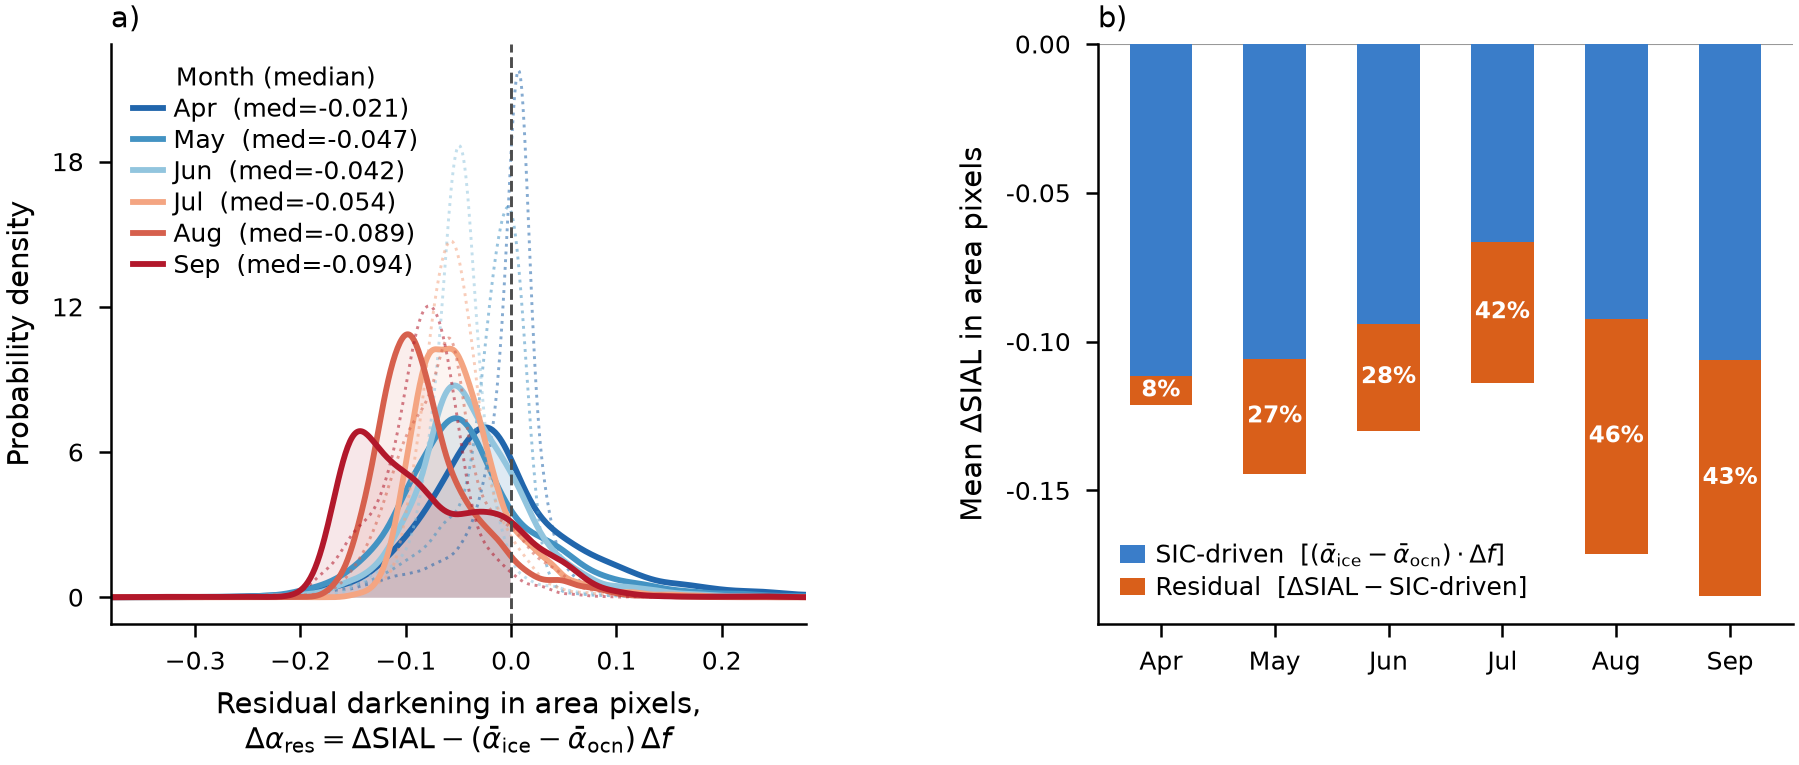

In [2]:
# %%
import pickle
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy.stats import gaussian_kde

PKL_PATH = ('/glade/work/jrotondo/ncc_paper/plots/'
            'extended_data_figs/plot_data_covariance.pkl')
OUT_DIR  = '/glade/work/jrotondo/ncc_paper/plots/extended_data_figs/'

# ── load ──────────────────────────────────────────────────────────────
with open(PKL_PATH, 'rb') as fh:
    d = pickle.load(fh)

monthly_res_ext  = d['monthly_res_ext']
monthly_dalb_drk = d['monthly_dalb_drk']
monthly_dalb_ext = d['monthly_dalb_ext']
monthly_dalb_sic = d['monthly_dalb_sic']
monthly_dalb_res = d['monthly_dalb_res']
monthly_meta     = d['monthly_meta']
MONTHS           = d['MONTHS']

# ── style ─────────────────────────────────────────────────────────────
mpl.rcParams.update({
    'font.family': 'sans-serif', 'font.sans-serif': ['Arial','Helvetica','DejaVu Sans'],
    'font.size': 7, 'axes.titlesize': 7, 'axes.labelsize': 7,
    'xtick.labelsize': 6, 'ytick.labelsize': 6,
    'legend.fontsize': 6, 'legend.title_fontsize': 6,
    'axes.linewidth': 0.6, 'xtick.major.width': 0.6, 'ytick.major.width': 0.6,
    'xtick.major.size': 3, 'ytick.major.size': 3,
    'xtick.direction': 'out', 'ytick.direction': 'out',
    'lines.linewidth': 1.2, 'figure.dpi': 300, 'savefig.dpi': 300,
    'savefig.bbox': 'tight', 'savefig.pad_inches': 0.02,
    'axes.spines.top': False, 'axes.spines.right': False,
    'pdf.fonttype': 42, 'ps.fonttype': 42,
})

COL_EXT = '#3A7DC9'
COL_RES = '#D95F1A'
MONTH_COLORS = {4:'#2166AC', 5:'#4393C3', 6:'#92C5DE',
                7:'#F4A582', 8:'#D6604D', 9:'#B2182B'}

# ── figure ────────────────────────────────────────────────────────────
fig, (ax, ax2) = plt.subplots(
    1, 2, figsize=(6.30, 2.76),
    gridspec_kw={'wspace': 0.42, 'left': 0.09, 'right': 0.98,
                 'bottom': 0.18, 'top': 0.88}, dpi=300,
)

# panel (a) — KDE of residual darkening
x_kde = np.linspace(-0.38, 0.28, 600)
for mn in sorted(monthly_res_ext):
    res = monthly_res_ext[mn][np.isfinite(monthly_res_ext[mn])]
    col = MONTH_COLORS[mn]
    kde = gaussian_kde(res, bw_method='silverman')
    y   = kde(x_kde)
    ax.plot(x_kde, y, color=col, lw=1.4,
            label=f"{MONTHS[mn][:3]}  (med={np.median(res):+.3f})")
    ax.fill_between(x_kde, y, where=(x_kde < 0), color=col, alpha=0.10, lw=0)
    if mn in monthly_dalb_drk:
        drk = monthly_dalb_drk[mn][np.isfinite(monthly_dalb_drk[mn])]
        if len(drk) > 50:
            ax.plot(x_kde, gaussian_kde(drk, bw_method='silverman')(x_kde),
                    color=col, lw=0.7, ls=':', alpha=0.55)
    pct = (res < 0).mean() * 100
    print(f"{MONTHS[mn]}: {pct:.0f}% negative residual  |  "
          f"α_ice={monthly_meta[mn]['alpha_ice']:.3f}  "
          f"α_ocn={monthly_meta[mn]['alpha_ocn']:.3f}  "
          f"n_ext={monthly_meta[mn]['n_ext_px']:,}")

ax.axvline(0, color='0.3', lw=0.7, ls='--', zorder=5)
ax.set_xlabel(
    r'Residual darkening in area pixels,'
    '\n'
    r'$\Delta\alpha_\mathrm{res}=\Delta\mathrm{SIAL}'
    r'-(\bar{\alpha}_\mathrm{ice}-\bar{\alpha}_\mathrm{ocn})\,\Delta f$',
    labelpad=3)
ax.set_ylabel('Probability density')
ax.set_title('a)', loc='left', pad=4)
ax.set_xlim(-0.38, 0.28)
ax.yaxis.set_major_locator(mticker.MaxNLocator(4, integer=True))
ax.xaxis.set_major_locator(mticker.MultipleLocator(0.1))
leg = ax.legend(loc='upper left', frameon=False, title='Month (median)',
                handlelength=1.2, handletextpad=0.4, labelspacing=0.25)
leg.get_title().set_fontsize(6)

# panel (b) — stacked bar decomposition
mn_list  = sorted(monthly_dalb_ext)
x_pos    = np.arange(len(mn_list))
tot_vals = np.array([monthly_dalb_ext[m] for m in mn_list])
sic_vals = np.array([monthly_dalb_sic[m] for m in mn_list])
res_vals = np.array([monthly_dalb_res[m] for m in mn_list])

ax2.bar(x_pos, sic_vals, width=0.55, color=COL_EXT, zorder=3,
        label=r'SIC-driven  $[(\bar{\alpha}_\mathrm{ice}-\bar{\alpha}_\mathrm{ocn})\cdot\Delta f]$')
ax2.bar(x_pos, res_vals,  width=0.55, bottom=sic_vals, color=COL_RES, zorder=3,
        label=r'Residual  $[\Delta\mathrm{SIAL}-\mathrm{SIC\text{-}driven}]$')

for i, (sv, rv, tv) in enumerate(zip(sic_vals, res_vals, tot_vals)):
    if tv != 0 and np.isfinite(rv) and abs(rv / tv) > 0.02:
        ax2.text(x_pos[i], sv + rv / 2, f'{rv/tv*100:.0f}%',
                 ha='center', va='center', fontsize=5.5,
                 color='white', fontweight='bold', zorder=6)

ax2.axhline(0, color='0.6', lw=0.5, zorder=1)
ax2.set_xticks(x_pos)
ax2.set_xticklabels([MONTHS[m][:3] for m in mn_list])
ax2.set_ylabel(r'Mean $\Delta$SIAL in area pixels')
ax2.set_title('b)', loc='left', pad=4)
ax2.yaxis.set_major_locator(mticker.MultipleLocator(0.05))
ax2.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.2f'))
ax2.legend(loc='lower left', frameon=False,
           handlelength=1.0, handletextpad=0.4, labelspacing=0.3)

# ── save ──────────────────────────────────────────────────────────────
for ext in ('pdf', 'png'):
    out = f'{OUT_DIR}/fe_covariance.{ext}'
    fig.savefig(out)
    print(f'Saved → {out}')
plt.show()

## Extended Data Figure 6

In [2]:
#!/usr/bin/env python
"""
Extended Data Fig. 6 (formerly fe04) — BMA-selected model subset.
Top 10% of models by BMA weight on TOTAL SIAF, drawn from the 21 models
retaining >=5 ensemble members. Observational uncertainty is 2-sigma
throughout, matching Figs 3-5.
"""
import numpy as np, pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

CMIP6_CSV = '/glade/derecho/scratch/jrotondo/siaf_cmip6_summary_final.csv'
OBS_CSV   = '/glade/work/jrotondo/ncc_paper/plots/sensitivity/siaf_pixelwise_summary.csv'
OUT       = '/glade/work/jrotondo/ncc_paper/plots/cmip6_pistone_only/fe06.png'

MIN_MEMBERS = 5        # 21 models, 346 members
TOP_PCT     = 90       # keep models above this percentile of BMA weight
SELECT_ON   = 'tot'    # 'area' | 'drk' | 'tot'  -- subset chosen on total SIAF
COMMON_X    = False    # True -> one shared x-range across all three panels

COL_EXT, COL_DRK = '#3A6BAF', '#D95F1A'
COL_UW, COL_BMA, COL_VC, COL_OBS = '#999999', '#111111', '#2166ac', '#e8262c'
COL_MDL = ['#7EB2DD', '#F0A860', '#8FBF7F', '#C08BC0']

# ── data ──────────────────────────────────────────────────────────────────
d = pd.read_csv(CMIP6_CSV)
d = d[d.rs_method == 'full_T07']
cnt = d.groupby('model').size()
d = d[d.model.isin(cnt[cnt >= MIN_MEMBERS].index)]
print(f'pool: {d.model.nunique()} models, {len(d)} members')

o = pd.read_csv(OBS_CSV)
o = o[(o.rs_method == 'CERES') & (o.period == 'CMIP6')
      & (np.isclose(o.pval, 0.05))].iloc[0]

OBS  = {'area': (float(o.SIAF_ext_global), float(o.sigma2_ext_global)),
        'drk':  (float(o.SIAF_drk_global), float(o.sigma2_drk_global)),
        'tot':  (float(o.SIAF_tot_global), float(o.sigma2_tot_global))}
COLS = {'area': 'siaf_ext_global', 'drk': 'siaf_drk_global', 'tot': 'siaf_global'}

def norm(x, mu, sd):
    sd = max(sd, 1e-6)
    return np.exp(-0.5*((x-mu)/sd)**2)/(sd*np.sqrt(2*np.pi))

def bma_w(g, mu_o, sd_o):
    w = np.array([norm(mu_o, m, np.sqrt(s**2 + sd_o**2))
                  for m, s in zip(g['mean'], g['std'])])
    return w/w.sum() if w.sum() > 0 else np.ones(len(g))/len(g)

# ── choose the subset ─────────────────────────────────────────────────────
g_sel = d.groupby('model')[COLS[SELECT_ON]].agg(['mean', 'std']).dropna()
w_sel = bma_w(g_sel, *OBS[SELECT_ON])
wmap  = dict(zip(g_sel.index, w_sel))
keep  = g_sel.index[w_sel >= np.percentile(w_sel, TOP_PCT)].tolist()
pmap  = {m: 100*(w_sel <= wmap[m]).mean() for m in keep}
keep  = sorted(keep, key=lambda m: -wmap[m])

# colour keyed on model NAME so curves and legend cannot desynchronise
CMAP = {m: COL_MDL[j % len(COL_MDL)] for j, m in enumerate(keep)}

sub = d[d.model.isin(keep)]
print(f'subset selected on SIAF_{SELECT_ON}: {len(keep)} of {len(g_sel)} models, '
      f'{len(sub)} members')
for m in keep:
    print(f'   {m:18s} w={wmap[m]:.3f}  {pmap[m]:.0f}th pct  colour={CMAP[m]}')

if COMMON_X:
    lo_all, hi_all = np.inf, -np.inf
    for k in ('area', 'drk', 'tot'):
        g = sub.groupby('model')[COLS[k]].agg(['mean', 'std']).dropna()
        m_o, s_o = OBS[k]
        lo_all = min(lo_all, g['mean'].min()-3*max(g['std'].max(), s_o), m_o-3*s_o)
        hi_all = max(hi_all, g['mean'].max()+3*max(g['std'].max(), s_o), m_o+3*s_o)

# ── figure ────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
fig.patch.set_facecolor('white')

for i, (ax, key) in enumerate(zip(axes, ['area', 'drk', 'tot'])):
    col = COLS[key]; mu_o, sd_o = OBS[key]
    g = sub.groupby('model')[col].agg(['mean', 'std']).dropna()
    mus, sds = g['mean'].values, g['std'].values

    if COMMON_X:
        lo, hi = lo_all, hi_all
    else:
        lo = min(mus.min()-3*max(sds.max(), sd_o), mu_o-3*sd_o)
        hi = max(mus.max()+3*max(sds.max(), sd_o), mu_o+3*sd_o)
    x = np.linspace(lo, hi, 900)

    w = bma_w(g, mu_o, sd_o)
    p_uw  = np.mean([norm(x, m, s) for m, s in zip(mus, sds)], axis=0)
    p_bma = np.sum([wi*norm(x, m, s) for wi, m, s in zip(w, mus, sds)], axis=0)
    p_vc  = np.mean([norm(x, m, sd_o) for m in mus], axis=0)
    p_obs = norm(x, mu_o, sd_o)

    ax.set_facecolor('white')
    for m in g.index:
        ax.plot(x, norm(x, g.loc[m, 'mean'], g.loc[m, 'std']),
                color=CMAP[m], lw=1.5, zorder=2)
    ax.plot(x, p_uw,  color=COL_UW,  ls='--', lw=2.4, zorder=3)
    ax.plot(x, p_bma, color=COL_BMA, lw=2.4, zorder=4)
    ax.plot(x, p_vc,  color=COL_VC,  lw=2.4, zorder=4)
    ax.plot(x, p_obs, color=COL_OBS, lw=2.4, zorder=5)
    ax.fill_between(x, p_obs, color=COL_OBS, alpha=0.14, zorder=1)
    ax.axvline(mu_o, color=COL_OBS, ls=':', lw=1.5, zorder=5)

    ax.set_xlim(lo, hi); ax.set_ylim(bottom=0)
    ax.set_xlabel('Pan-Arctic SIAF (W m$^{-2}$ K$^{-1}$)', fontsize=11)
    ax.tick_params(axis='both', labelsize=10)
    for s in ('top', 'right'):
        ax.spines[s].set_visible(False)
    ax.text(-0.02, 1.10, chr(97+i), transform=ax.transAxes,
            fontsize=15, fontweight='bold', va='top', ha='right')

    if key == 'area':
        ax.set_title(r'SIAF$_{\mathrm{area}}$', fontsize=14, color=COL_EXT, pad=10)
    elif key == 'drk':
        ax.set_title(r'SIAF$_{\mathrm{drk}}$', fontsize=14, color=COL_DRK, pad=10)
    else:
        ax.text(0.34, 1.03, r'SIAF$_{\mathrm{area}}$', transform=ax.transAxes,
                fontsize=14, color=COL_EXT, ha='right', va='bottom')
        ax.text(0.50, 1.03, '+', transform=ax.transAxes,
                fontsize=14, color='#222', ha='center', va='bottom')
        ax.text(0.66, 1.03, r'SIAF$_{\mathrm{drk}}$', transform=ax.transAxes,
                fontsize=14, color=COL_DRK, ha='left', va='bottom')

    print(f'\n  {key}: obs={mu_o:.4f}+/-{sd_o:.4f}  '
          f'subset mean={mus.mean():.4f} ({100*(mu_o-mus.mean())/mu_o:.1f}% low)')
    for m in keep:
        if m in g.index:
            print(f'    {m:18s} {g.loc[m,"mean"]:.4f} '
                  f'({100*(g.loc[m,"mean"]-mu_o)/mu_o:+.0f}%)')

axes[0].set_ylabel('Probability density', fontsize=11)

lbl = {'area': r'SIAF$_{\mathrm{area}}$', 'drk': r'SIAF$_{\mathrm{drk}}$',
       'tot': 'total SIAF'}[SELECT_ON]
fig.suptitle(f'BMA-selected subset: {len(keep)} models  '
             f'(top {100-TOP_PCT}% by BMA weight on {lbl})\n'
             f'({", ".join(keep)})', fontsize=12, color='#555', y=1.06)

handles = [Line2D([0], [0], color=COL_UW,  ls='--', lw=2.4, label='Unweighted ensemble'),
           Line2D([0], [0], color=COL_BMA, lw=2.4, label='BMA-weighted ensemble'),
           Line2D([0], [0], color=COL_VC,  lw=2.4, label='Variance-constrained'),
           Patch(facecolor=COL_OBS, alpha=0.30, edgecolor=COL_OBS,
                 label='Observational PDF ($\\pm2\\sigma$)')]
handles += [Line2D([0], [0], color=CMAP[m], lw=1.8,
                   label=f'{m}  (w={wmap[m]:.3f}, {pmap[m]:.0f}th pct)')
            for m in keep]
fig.legend(handles=handles, loc='upper center', bbox_to_anchor=(0.5, -0.02),
           ncol=4, fontsize=9.5, framealpha=0.95)

plt.tight_layout()
plt.savefig(OUT, dpi=300, bbox_inches='tight', facecolor='white')
print(f'\n-> {OUT}')

pool: 21 models, 346 members
subset selected on SIAF_tot: 3 of 21 models, 39 members
   NESM3              w=0.125  100th pct  colour=#7EB2DD
   MRI-ESM2-0         w=0.113  95th pct  colour=#F0A860
   CanESM5            w=0.099  90th pct  colour=#8FBF7F

  area: obs=0.1435+/-0.0183  subset mean=0.1077 (25.0% low)
    NESM3              0.1351 (-6%)
    MRI-ESM2-0         0.0825 (-43%)
    CanESM5            0.1054 (-27%)

  drk: obs=0.0812+/-0.0222  subset mean=0.0540 (33.5% low)
    NESM3              0.0311 (-62%)
    MRI-ESM2-0         0.0776 (-5%)
    CanESM5            0.0533 (-34%)

  tot: obs=0.2248+/-0.0370  subset mean=0.1617 (28.1% low)
    NESM3              0.1662 (-26%)
    MRI-ESM2-0         0.1600 (-29%)
    CanESM5            0.1588 (-29%)

-> /glade/work/jrotondo/ncc_paper/plots/cmip6_pistone_only/fe06.png


## Extended Data Figure 4

In [4]:
#!/usr/bin/env python
"""
Extended Data — SIE bias vs SIAF structure, family-grouped.

SIE from sie_df_common.pkl: all 31 models, computed by remapping siconc onto a
common 0.5-degree grid (nearest neighbour) and summing the analytic spherical
cell area where SIC >= 15%. This removes any dependence on model-specific
areacello fields -- unpublished for several models, and unreliable when
reconstructed from cell vertices -- and measures every model identically.
Validated against native-grid areacello values: agreement 0.1-3.7%.

Error bars are +/-2 sigma across ensemble members, matching Figs 3 and 4.
"""
import os, pickle
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import scipy.stats as stats

PLOT_DIR  = '/glade/work/jrotondo/ncc_paper/plots/cmip6_pistone_only/sie_comparison/'
CACHE_DIR = os.path.join(PLOT_DIR, 'cache')
OUT_DIR   = os.path.join(PLOT_DIR, 'family')
os.makedirs(OUT_DIR, exist_ok=True)

CMIP6_SIAF_CSV = '/glade/derecho/scratch/jrotondo/siaf_cmip6_summary_final.csv'
OBS_SIAF_CSV   = ('/glade/work/jrotondo/ncc_paper/plots/sensitivity/'
                  'siaf_pixelwise_summary.csv')
SIE_PKL        = '/glade/derecho/scratch/jrotondo/sie_df_common.pkl'   # CHANGED

MONTH_NUMS  = [4, 5, 6, 7, 8, 9]
EARLY_YEARS = list(range(1982, 1992))
TREND_YEARS = list(range(1982, 2015))
FOCUS_RS_METHOD, MIN_MEMBERS = 'full_T07', 3
OBS_PERIOD, OBS_RS, OBS_PVAL = 'CMIP6', 'CERES', 0.05
COL_OBS = '#b5000a'

FAMILY = {**{m:'CESM2' for m in ['CESM2','CESM2-WACCM','CESM2-FV2','CESM2-WACCM-FV2']},
          **{m:'EC-Earth3' for m in ['EC-Earth3','EC-Earth3-Veg','EC-Earth3-Veg-LR',
                                     'EC-Earth3-CC','EC-Earth3-AerChem','EC-Earth3-ESM-1']},
          **{m:'CMCC' for m in ['CMCC-CM2-SR5','CMCC-ESM2','CMCC-CM2-HR4']},
          **{m:'E3SM' for m in ['E3SM-1-0','E3SM-1-1','E3SM-1-1-ECA']},
          **{m:'HadGEM3/UKESM' for m in ['HadGEM3-GC31-LL','HadGEM3-GC31-MM',
                                         'UKESM1-0-LL','UKESM1-1-LL']},
          **{m:'MPI/ICON' for m in ['MPI-ESM1-2-HR','MPI-ESM1-2-LR',
                                    'MPI-ESM-1-2-HAM','ICON-ESM-LR']},
          **{m:'NorESM/NorCPM' for m in ['NorESM2-LM','NorESM2-MM','NorCPM1']},
          **{m:'CNRM' for m in ['CNRM-CM6-1','CNRM-CM6-1-HR','CNRM-ESM2-1']},
          **{m:'CanESM5' for m in ['CanESM5','CanESM5-CanOE']},
          **{m:'MIROC' for m in ['MIROC6','MIROC-ES2L']},
          **{m:'IPSL' for m in ['IPSL-CM6A-LR','IPSL-CM6A-LR-INCA','IPSL-CM5A2-INCA']},
          **{m:'INM' for m in ['INM-CM4-8','INM-CM5-0']},
          **{m:'FGOALS' for m in ['FGOALS-g3','FGOALS-f3-L']},
          **{m:'BCC' for m in ['BCC-CSM2-MR','BCC-ESM1']},
          **{m:'ACCESS' for m in ['ACCESS-CM2','ACCESS-ESM1-5']},
          **{m:'GISS' for m in ['GISS-E2-1-H','GISS-E2-1-G']}}

def load_cache(name):
    p = os.path.join(CACHE_DIR, f'{name}.pkl')
    with open(p, 'rb') as f: obj = pickle.load(f)
    print(f'  [cache] loaded ← {p}')
    return obj

def _style_ax(ax):
    ax.yaxis.grid(True, alpha=0.35, linewidth=0.7, zorder=0)
    ax.xaxis.grid(True, alpha=0.35, linewidth=0.7, zorder=0)
    ax.set_axisbelow(True)
    for sp in ['top','right']: ax.spines[sp].set_visible(False)

def _ols_line(ax, xs, ys, color='#222', ls='--'):
    ok = np.isfinite(xs) & np.isfinite(ys)
    if ok.sum() < 3: return None, None
    r, p = stats.pearsonr(xs[ok], ys[ok])
    sl, b = np.polyfit(xs[ok], ys[ok], 1)
    xr_ = np.linspace(xs[ok].min(), xs[ok].max(), 100)
    ax.plot(xr_, sl*xr_ + b, color=color, linestyle=ls, linewidth=1.8,
            label=f'r = {r:.2f}, p = {p:.3f}', zorder=3)
    return r, p

def _season_mean(row, key):
    v = [row.get(f'm{mn}_{key}', np.nan) for mn in MONTH_NUMS]
    f = [x for x in v if np.isfinite(x)]
    return float(np.nanmean(f)) if f else np.nan

def _scatter(ax, xs, ys, labels, colors, x_errs=None, y_errs=None,
             obs_xy=None, obs_err_x=None, obs_err_y=None, obs_label='OBS'):
    xs = np.asarray(xs, float); ys = np.asarray(ys, float)
    if x_errs is not None or y_errs is not None:
        xe = np.asarray(x_errs, float) if x_errs is not None else np.zeros_like(xs)
        ye = np.asarray(y_errs, float) if y_errs is not None else np.zeros_like(ys)
        for xi, yi, xei, yei, c in zip(xs, ys, xe, ye, colors):
            ax.errorbar(xi, yi,
                        xerr=float(xei) if np.isfinite(xei) and xei > 0 else None,
                        yerr=float(yei) if np.isfinite(yei) and yei > 0 else None,
                        fmt='none', color=c, alpha=0.55, linewidth=1.1,
                        capsize=3.0, capthick=1.1, zorder=2)
    ax.scatter(xs, ys, c=colors, s=95, edgecolors='white', linewidths=0.8, zorder=4)
    for xi, yi, l in zip(xs, ys, labels):
        ax.annotate(l, (xi, yi), textcoords='offset points', xytext=(4,3),
                    fontsize=7.5, zorder=5)
    _ols_line(ax, xs, ys)
    if obs_xy is not None:
        ox, oy = obs_xy
        if np.isfinite(ox) and np.isfinite(oy):
            ax.scatter([ox],[oy], marker='*', s=280, c=COL_OBS,
                       edgecolors='#800000', linewidths=0.8, zorder=7, label=obs_label)
            xv = float(obs_err_x) if obs_err_x and np.isfinite(obs_err_x) else None
            yv = float(obs_err_y) if obs_err_y and np.isfinite(obs_err_y) else None
            if xv or yv:
                ax.errorbar(ox, oy, xerr=xv, yerr=yv, fmt='none', color=COL_OBS,
                            linewidth=1.4, capsize=4, capthick=1.4, zorder=6)

# ── data ──────────────────────────────────────────────────────────────────
sie_df = pd.read_pickle(SIE_PKL)
print(f'SIE: {len(sie_df)} members / {sie_df.model.nunique()} models')
if 'area_source' in sie_df:
    print('  areas:', sie_df.area_source.value_counts().to_dict())
obs_sie_by_month = load_cache('obs_sie_by_month')

o = pd.read_csv(OBS_SIAF_CSV)
row = o[(o.period == OBS_PERIOD) & (o.rs_method == OBS_RS) &
        np.isclose(o.pval, OBS_PVAL)].iloc[0]
OBS_TOT, OBS_EXT = float(row.SIAF_tot_global), float(row.SIAF_ext_global)
OBS_ERR = float(row.sigma2_tot_global)          # CHANGED: already 2-sigma
obs_prop = OBS_EXT / OBS_TOT
obs_prop_err = OBS_ERR / OBS_TOT * obs_prop

s = pd.read_csv(CMIP6_SIAF_CSV); s = s[s.rs_method == FOCUS_RS_METHOD]
c = s.groupby('model').size(); s = s[s.model.isin(c[c >= MIN_MEMBERS].index)]

msie = {}
for m in sie_df.model.unique():
    sub = sie_df[sie_df.model == m]
    msie[m] = dict(trend=float(np.nanmean([_season_mean(r,'trend_slope')
                                           for _, r in sub.iterrows()])),
                   early=float(np.nanmean([_season_mean(r,'early_mean')
                                           for _, r in sub.iterrows()])))
msiaf = {}
for m in s.model.unique():
    sub = s[s.model == m]
    sv = sub.siaf_global.values.astype(float); ev = sub.siaf_ext_global.values.astype(float)
    pr = np.clip(np.where(sv > 0, ev/sv, np.nan), 0, 1)
    msiaf[m] = dict(siaf=float(np.nanmean(sv)), prop=float(np.nanmean(pr)), n=len(sub))

common  = sorted(set(msie) & set(msiaf))
excluded = sorted(set(msiaf) - set(msie))
print(f'{len(common)} models with SIE'
      + (f'; {len(excluded)} without: {excluded}' if excluded else '; none missing'))

md = pd.DataFrame([dict(model=m, family=FAMILY.get(m, m), n=msiaf[m]['n'],
                        trend=msie[m]['trend'], early=msie[m]['early'],
                        siaf=msiaf[m]['siaf'], prop=msiaf[m]['prop'])
                   for m in common])

# family means from model means (one vote per model)
fam = md.groupby('family')[['trend','early','siaf','prop']].mean()
fam['n_mod'] = md.groupby('family').size()
fam['n_mem'] = md.groupby('family')['n'].sum()

# CHANGED: spread across MEMBERS (2 sigma), so every family gets an error bar
sie_mem = sie_df[sie_df.model.isin(common)].copy()
sie_mem['trend'] = [_season_mean(r, 'trend_slope') for _, r in sie_mem.iterrows()]
sie_mem['early'] = [_season_mean(r, 'early_mean')  for _, r in sie_mem.iterrows()]
sie_mem['family'] = sie_mem.model.map(lambda m: FAMILY.get(m, m))

siaf_mem = s[s.model.isin(common)].copy()
siaf_mem['prop'] = np.clip(np.where(siaf_mem.siaf_global > 0,
                                    siaf_mem.siaf_ext_global / siaf_mem.siaf_global,
                                    np.nan), 0, 1)
siaf_mem['family'] = siaf_mem.model.map(lambda m: FAMILY.get(m, m))

fam_sd = pd.DataFrame(index=fam.index)
fam_sd['trend'] = 2 * sie_mem.groupby('family')['trend'].std()
fam_sd['early'] = 2 * sie_mem.groupby('family')['early'].std()
fam_sd['siaf']  = 2 * siaf_mem.groupby('family')['siaf_global'].std()
fam_sd['prop']  = 2 * siaf_mem.groupby('family')['prop'].std()
fam_sd = fam_sd.fillna(0.)

fam = fam.sort_values('siaf'); fam_sd = fam_sd.reindex(fam.index)
print(f'{len(fam)} families')

# ── OBS SIE ───────────────────────────────────────────────────────────────
sl_, sl_e, ea_, ea_e = [], [], [], []
for mn in MONTH_NUMS:
    ser = obs_sie_by_month.get(mn)
    if ser is None or len(ser) < 5: continue
    st = ser[(ser.index >= TREND_YEARS[0]) & (ser.index <= TREND_YEARS[-1])].dropna()
    if len(st) < 5: continue
    res = stats.linregress(st.index.values.astype(float), st.values)
    sl_.append(float(res.slope)); sl_e.append(float(res.stderr))
    se = ser[ser.index.isin(EARLY_YEARS)].dropna()
    if len(se):
        ea_.append(float(se.mean()))
        ea_e.append(float(se.std(ddof=1)) if len(se) > 1 else 0.)
obs_slope, obs_slope_err = np.nanmean(sl_), np.nanmean(sl_e)
obs_early, obs_early_err = np.nanmean(ea_), np.nanmean(ea_e)
print(f'OBS SIE slope {obs_slope:+.4f} ± {obs_slope_err:.4f}, '
      f'early {obs_early:.3f} ± {obs_early_err:.3f}')

lbls = list(fam.index)
pal  = list(plt.get_cmap('tab20').colors)
cols = [pal[i % len(pal)] for i in range(len(lbls))]
SLOPE_LABEL = 'SIE trend  (10⁶ km² yr⁻¹)'
EARLY_LABEL = 'Early-period SIE, 1982–1991  (10⁶ km²)'

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.patch.set_facecolor('#FAFAFA')
specs = [
 (axes[0,0], 'trend','siaf', SLOPE_LABEL, 'Pan-Arctic SIAF  (W m⁻² K⁻¹)',
  'SIE Trend vs SIAF', (obs_slope, OBS_TOT), obs_slope_err, OBS_ERR, None),
 (axes[0,1], 'early','siaf', EARLY_LABEL, 'Pan-Arctic SIAF  (W m⁻² K⁻¹)',
  'Early SIE vs SIAF', (obs_early, OBS_TOT), obs_early_err, OBS_ERR, None),
 (axes[1,0], 'trend','prop', SLOPE_LABEL, r'Pan-Arctic SIAF$_{\mathrm{area}}$ Proportion',
  r'SIE Trend vs SIAF$_{\mathrm{area}}$ Proportion',
  (obs_slope, obs_prop), obs_slope_err, obs_prop_err, 1.0),
 (axes[1,1], 'early','prop', EARLY_LABEL, r'Pan-Arctic SIAF$_{\mathrm{area}}$ Proportion',
  r'Early SIE vs SIAF$_{\mathrm{area}}$ Proportion',
  (obs_early, obs_prop), obs_early_err, obs_prop_err, 1.0),
]
for i, (ax, xk, yk, xl, yl, ttl, oxy, oex, oey, top) in enumerate(specs):
    ax.set_facecolor('#FAFAFA')
    _scatter(ax, fam[xk].values, fam[yk].values, lbls, cols,
             x_errs=fam_sd[xk].values, y_errs=fam_sd[yk].values,
             obs_xy=oxy, obs_err_x=oex, obs_err_y=oey, obs_label='OBS')
    ax.set_xlabel(xl, fontsize=14); ax.set_ylabel(yl, fontsize=14)
    ax.set_title(ttl, fontsize=14, fontweight='bold', pad=8)
    ax.set_title(f'{chr(97+i)})', loc='left', fontsize=16, fontweight='bold', pad=8)
    ax.legend(fontsize=8, framealpha=0.85); _style_ax(ax)
    ax.tick_params(axis='both', which='major', labelsize=12)
    if top is not None: ax.set_ylim(top=top)
plt.tight_layout(pad=2.0, w_pad=3.5, h_pad=4.0)
out = os.path.join(OUT_DIR, 'ed_sie_siaf_family.png')
fig.savefig(out, dpi=300, bbox_inches='tight', facecolor=fig.get_facecolor())
plt.close(fig)
print(f'  → {out}')

print('\n=== stats for the Results paragraph ===')
for xk, yk, lab in (('trend','siaf','SIE trend vs SIAF_tot'),
                    ('early','siaf','early SIE vs SIAF_tot'),
                    ('trend','prop','SIE trend vs area prop'),
                    ('early','prop','early SIE vs area prop')):
    r, p = stats.pearsonr(fam[xk], fam[yk])
    print(f'  {lab:24s} r={r:+.3f}  r2={r**2:.3f}  p={p:.4f}')

SIE: 378 members / 31 models
  areas: {'common-0.5deg': 378}
  [cache] loaded ← /glade/work/jrotondo/ncc_paper/plots/cmip6_pistone_only/sie_comparison/cache/obs_sie_by_month.pkl
31 models with SIE; none missing
18 families
OBS SIE slope -0.0565 ± 0.0062, early 10.423 ± 0.373
  → /glade/work/jrotondo/ncc_paper/plots/cmip6_pistone_only/sie_comparison/family/ed_sie_siaf_family.png

=== stats for the Results paragraph ===
  SIE trend vs SIAF_tot    r=-0.655  r2=0.429  p=0.0032
  early SIE vs SIAF_tot    r=+0.369  r2=0.136  p=0.1319
  SIE trend vs area prop   r=-0.565  r2=0.319  p=0.0146
  early SIE vs area prop   r=-0.066  r2=0.004  p=0.7936


## Extended Data Figure 5

In [2]:
#!/usr/bin/env python
"""Extended Data — SIAF vs Arctic Amplification, family-grouped, 2-sigma bars."""
import os, glob
import numpy as np, pandas as pd, xarray as xr
from scipy import stats
import matplotlib; matplotlib.use('Agg')
import matplotlib.pyplot as plt

DIR_CMIP6_CSV = '/glade/derecho/scratch/jrotondo/siaf_cmip6_summary_final.csv'
DIR_OBS_CSV   = '/glade/work/jrotondo/ncc_paper/plots/sensitivity/siaf_pixelwise_summary.csv'
NCEP_PATH     = '/glade/work/jrotondo/ncep_air_sig995.nc'
ERA5_GLOB     = ('/glade/campaign/collections/rda/data/d633001/e5.moda.an.sfc/'
                 '*/e5.moda.an.sfc.128_167_2t.ll025sc.*.nc')
PLOT_OUT      = ('/glade/work/jrotondo/ncc_paper/plots/cmip6_pistone_only/'
                 'siaf_cmip6_vs_AA_family.png')
OBS_RS, OBS_PVAL = 'CERES', 0.05
EARLY_YEARS      = list(range(1982, 1992))
LATE_YEARS_CMIP6 = list(range(2005, 2015))
LATE_YEARS_OBS   = list(range(2015, 2025))
ARCTIC_LAT       = 60.

FAMILY = {**{m:'CESM2' for m in ['CESM2','CESM2-WACCM','CESM2-FV2','CESM2-WACCM-FV2']},
          **{m:'EC-Earth3' for m in ['EC-Earth3','EC-Earth3-Veg','EC-Earth3-Veg-LR',
                                     'EC-Earth3-CC','EC-Earth3-AerChem','EC-Earth3-ESM-1']},
          **{m:'CMCC' for m in ['CMCC-CM2-SR5','CMCC-ESM2','CMCC-CM2-HR4']},
          **{m:'E3SM' for m in ['E3SM-1-0','E3SM-1-1','E3SM-1-1-ECA']},
          **{m:'HadGEM3/UKESM' for m in ['HadGEM3-GC31-LL','HadGEM3-GC31-MM',
                                         'UKESM1-0-LL','UKESM1-1-LL']},
          **{m:'MPI/ICON' for m in ['MPI-ESM1-2-HR','MPI-ESM1-2-LR',
                                    'MPI-ESM-1-2-HAM','ICON-ESM-LR']},
          **{m:'NorESM/NorCPM' for m in ['NorESM2-LM','NorESM2-MM','NorCPM1']},
          **{m:'CNRM' for m in ['CNRM-CM6-1','CNRM-CM6-1-HR','CNRM-ESM2-1']},
          **{m:'CanESM5' for m in ['CanESM5','CanESM5-CanOE']},
          **{m:'MIROC' for m in ['MIROC6','MIROC-ES2L']},
          **{m:'IPSL' for m in ['IPSL-CM6A-LR','IPSL-CM6A-LR-INCA','IPSL-CM5A2-INCA']},
          **{m:'INM' for m in ['INM-CM4-8','INM-CM5-0']},
          **{m:'FGOALS' for m in ['FGOALS-g3','FGOALS-f3-L']},
          **{m:'BCC' for m in ['BCC-CSM2-MR','BCC-ESM1']},
          **{m:'ACCESS' for m in ['ACCESS-CM2','ACCESS-ESM1-5']},
          **{m:'GISS' for m in ['GISS-E2-1-H','GISS-E2-1-G']}}

def _epoch_means(da, lat_name, years):
    yrs = np.array([int(t.dt.year) for t in da.time]); mask = np.isin(yrs, years)
    if not mask.any(): return np.nan, np.nan
    arr = da.isel(time=mask).mean('time').values.astype(float)
    lat = da[lat_name].values.astype(float)
    if lat.ndim == 1:
        lon_name = 'longitude' if 'longitude' in da.coords else 'lon'
        _, lat2d = np.meshgrid(da[lon_name].values, lat)
    else:
        lat2d = lat
    w_glob = np.cos(np.deg2rad(lat2d))
    w_arct = np.where(lat2d >= ARCTIC_LAT, w_glob, 0.)
    def _wm(w):
        ok = np.isfinite(arr) & (w > 0)
        return float(np.sum(arr[ok]*w[ok])/np.sum(w[ok])) if ok.any() else np.nan
    return _wm(w_glob), _wm(w_arct)

def _aa_from_da(da, lat_name, late_years):
    g_e, a_e = _epoch_means(da, lat_name, EARLY_YEARS)
    g_l, a_l = _epoch_means(da, lat_name, late_years)
    dg, da_ = g_l - g_e, a_l - a_e
    return float(da_/dg) if (np.isfinite(dg) and dg > 0 and np.isfinite(da_)) else np.nan

def compute_obs_AA(late_years):
    aas = {}
    try:
        if os.path.exists(NCEP_PATH):
            ds = xr.open_dataset(NCEP_PATH); air = ds['air']
            ln = 'lat' if 'lat' in air.coords else 'latitude'
            aa = _aa_from_da(air, ln, late_years); ds.close()
            if np.isfinite(aa): aas['NCEP'] = aa
    except Exception as e: print(f'  NCEP AA failed: {e}')
    try:
        files = sorted(glob.glob(ERA5_GLOB))
        if files:
            ds = xr.open_mfdataset(files, combine='by_coords'); t2m = ds['VAR_2T']
            ln = 'latitude' if 'latitude' in t2m.coords else 'lat'
            aa = _aa_from_da(t2m, ln, late_years); ds.close()
            if np.isfinite(aa): aas['ERA5'] = aa
    except Exception as e: print(f'  ERA5 AA failed: {e}')
    if not aas: return np.nan, np.nan
    v = list(aas.values())
    return float(np.mean(v)), float(np.std(v)) if len(v) > 1 else 0.

df = pd.read_csv(DIR_CMIP6_CSV); df = df[df.rs_method == 'full_T07'].copy()
c = df.groupby('model').size(); df = df[df.model.isin(c[c >= 3].index)].copy()
df['AA'] = df.delta_t_arctic / df.delta_t
df = df.dropna(subset=['AA','siaf_global']); df = df[df.AA > 0].copy()
df['family'] = df.model.map(lambda m: FAMILY.get(m, m))

mm  = df.groupby(['family','model'])[['AA','siaf_global']].mean()
fam = mm.groupby('family').mean()
sp  = 2 * df.groupby('family')[['AA','siaf_global']].std().fillna(0.)   # 2-sigma
fam['aa_sd'], fam['siaf_sd'] = sp.AA, sp.siaf_global
fam['n_mod'] = mm.groupby('family').size()
fam['n_mem'] = df.groupby('family').size()
fam = fam.sort_values('siaf_global'); order = list(fam.index)
print(f'{len(order)} families, {df.model.nunique()} models, {len(df)} members')

obs = {}; df_obs = pd.read_csv(DIR_OBS_CSV)
for pk, lab in [('CMIP6','CMIP6-era (1982–2014)'), ('Obs-era','Obs-era (1982–2024)')]:
    r_ = df_obs[(df_obs.period == pk) & (df_obs.rs_method == OBS_RS) &
                np.isclose(df_obs.pval, OBS_PVAL)]
    if len(r_):
        obs[pk] = dict(siaf=float(r_.iloc[0].SIAF_tot_global),
                       siaf_err=float(r_.iloc[0].sigma2_tot_global),   # 2-sigma
                       label=lab)
print('Computing observed AA...')
a1, s1 = compute_obs_AA(LATE_YEARS_CMIP6); a2, s2 = compute_obs_AA(LATE_YEARS_OBS)
if 'CMIP6'   in obs: obs['CMIP6'].update(aa_mean=a1, aa_std=2*s1)
if 'Obs-era' in obs: obs['Obs-era'].update(aa_mean=a2, aa_std=2*s2)
print(f'  CMIP6-era AA={a1:.3f}  Obs-era AA={a2:.3f}')

aa_arr, si_arr = fam.AA.values, fam.siaf_global.values
fin_ = np.isfinite(aa_arr) & np.isfinite(si_arr)
slope, intercept, r, p_ols, _ = stats.linregress(aa_arr[fin_], si_arr[fin_])
print(f'OLS (family means): r={r:+.3f} r2={r**2:.3f} p={p_ols:.4f}')

pal = list(plt.get_cmap('tab20').colors)
cols = {f: pal[i % len(pal)] for i, f in enumerate(order)}
fig, ax = plt.subplots(figsize=(9.5, 7), dpi=300)
fig.patch.set_facecolor('#FAFAFA'); ax.set_facecolor('#FAFAFA')

for f in order:
    s_ = df[df.family == f]
    ax.scatter(s_.AA, s_.siaf_global, color=cols[f], s=12, alpha=0.40,
               zorder=1, edgecolors='none')
for f in order:
    x_m, y_m = fam.AA[f], fam.siaf_global[f]
    ax.errorbar(x_m, y_m, xerr=fam.aa_sd[f] or None, yerr=fam.siaf_sd[f] or None,
                fmt='none', color=cols[f], alpha=0.5, lw=1.0, capsize=2.5, zorder=2)
    ax.scatter(x_m, y_m, color=cols[f], s=75, zorder=4,
               edgecolors='white', linewidths=0.6)
    ax.annotate(f'{f} (n={int(fam.n_mem[f])})', xy=(x_m, y_m), xytext=(6, 3),
                textcoords='offset points', fontsize=7, color=cols[f],
                zorder=5, fontweight='bold')

xx = np.linspace(aa_arr[fin_].min()*0.9, aa_arr[fin_].max()*1.1, 100)
ax.plot(xx, slope*xx + intercept, color='#333333', lw=1.5, ls='--', zorder=3,
        label=f'OLS (family means): r²={r**2:.2f}, p={p_ols:.3f}')
for pk, st in (('CMIP6', dict(marker='D', ms=13)), ('Obs-era', dict(marker='*', ms=18))):
    if pk not in obs: continue
    o = obs[pk]
    if not (np.isfinite(o['siaf']) and np.isfinite(o.get('aa_mean', np.nan))): continue
    ax.errorbar(o['aa_mean'], o['siaf'],
                xerr=o['aa_std'] if o['aa_std'] > 0 else None,
                yerr=o['siaf_err'] if o['siaf_err'] > 0 else None,
                fmt=st['marker'], color='#b5000a', markersize=st['ms']/1.5,
                markeredgecolor='white', markeredgewidth=0.8, capsize=4,
                elinewidth=1.8, ecolor='#b5000a', zorder=7, label=o['label'])
if 'CMIP6' in obs and 'Obs-era' in obs:
    o1, o2 = obs['CMIP6'], obs['Obs-era']
    if all(np.isfinite([o1.get('aa_mean',np.nan), o1['siaf'],
                        o2.get('aa_mean',np.nan), o2['siaf']])):
        ax.annotate('', xy=(o2['aa_mean'], o2['siaf']),
                    xytext=(o1['aa_mean'], o1['siaf']),
                    arrowprops=dict(arrowstyle='->', color='#b5000a', lw=1.6,
                                    linestyle='dashed', connectionstyle='arc3,rad=0.18'))
ax.set_xlabel(r'Arctic Amplification ($\Delta T_\mathrm{Arctic}\ /\ \Delta T_\mathrm{global}$)',
              fontsize=11)
ax.set_ylabel(r'Pan-Arctic Annual SIAF (W m$^{-2}$ K$^{-1}$)', fontsize=11)
ax.tick_params(axis='both', labelsize=10)
ax.legend(loc='upper left', fontsize=9.5, framealpha=0.9)
ax.grid(True, alpha=0.2, zorder=0)
for sp_ in ['top','right']: ax.spines[sp_].set_visible(False)
fig.tight_layout(); fig.savefig(PLOT_OUT, facecolor=fig.get_facecolor()); plt.close(fig)
print(f'Saved → {PLOT_OUT}')

18 families, 31 models, 378 members
Computing observed AA...
  CMIP6-era AA=4.130  Obs-era AA=3.216
OLS (family means): r=+0.470 r2=0.221 p=0.0488
Saved → /glade/work/jrotondo/ncc_paper/plots/cmip6_pistone_only/siaf_cmip6_vs_AA_family.png


## Extended Data Figure 7

/glade/derecho/scratch/jrotondo/tmp/ipykernel_12683/181487008.py:48: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  aucs.append(float(np.trapz(tpr[order], fpr[order])))


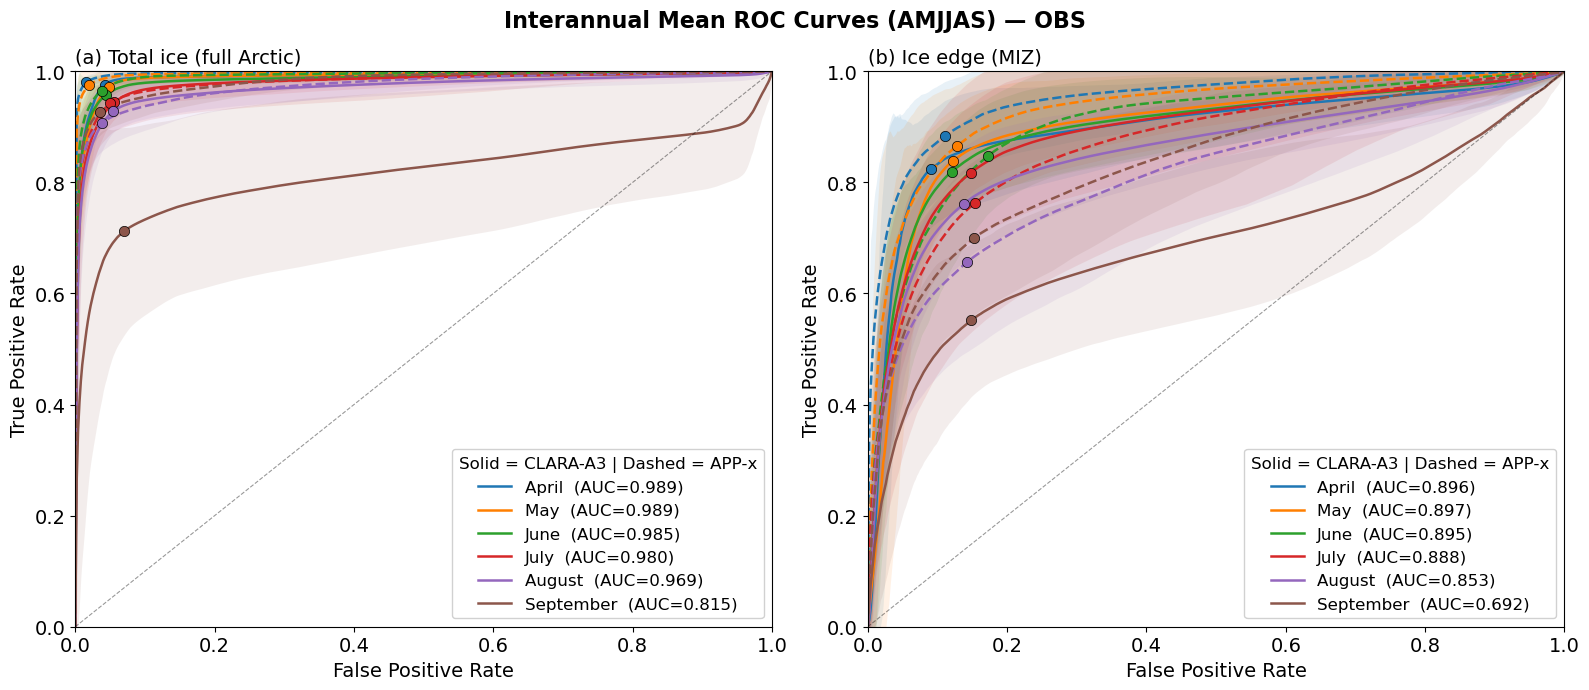

Saved → /glade/work/jrotondo/j_of_clim_dk_sea_ice_paper/output/albedo_disc//obs/roc_curves_obs.png


In [1]:
# %%
import pickle
import numpy as np
import matplotlib.pyplot as plt


# ── Config ────────────────────────────────────────────────────────────
EXP         = 'obs'   # change to 'cmip6' for the other experiment
OUTPUT_ROOT = "/glade/work/jrotondo/j_of_clim_dk_sea_ice_paper/output/albedo_disc/"
PKL_PATH    = f"{OUTPUT_ROOT}/{EXP}/plot_data_{EXP}.pkl"

N_SIGMA = 2   # shading half-width, matching the 2-sigma convention used throughout


# ── Load ──────────────────────────────────────────────────────────────
with open(PKL_PATH, 'rb') as fh:
    d = pickle.load(fh)


exp_key        = d['exp_key']
exp_label      = d['exp_label']
roc_store      = d['roc_store']
roc_edge_store = d['roc_edge_store']
MONTH_ORDER    = d['MONTH_ORDER']


# ── Helpers ───────────────────────────────────────────────────────────
MONTH_COLORS = {
    'April':     '#1f77b4',
    'May':       '#ff7f00',
    'June':      '#2ca02c',
    'July':      '#d62728',
    'August':    '#9467bd',
    'September': '#8c564b',
}
FPR_GRID = np.linspace(0, 1, 500)


FS = 14   # master font size — change one place to rescale everything


def mean_roc(roc_dict):
    """Interpolate per-year curves to common FPR grid, return mean ± std."""
    tprs, aucs = [], []
    for tpr, fpr in roc_dict.values():
        order = np.argsort(fpr)
        tprs.append(np.interp(FPR_GRID, fpr[order], tpr[order]))
        aucs.append(float(np.trapz(tpr[order], fpr[order])))
    if not tprs:
        return None
    tprs = np.array(tprs)
    m = np.nanmean(tprs, axis=0)
    s = np.nanstd(tprs,  axis=0)
    i = int(np.argmax(m - FPR_GRID))          # Youden index
    return dict(mean=m, std=s, auc=float(np.mean(aucs)),
                opt_fpr=FPR_GRID[i], opt_tpr=m[i])


# ── Figure ────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle(f'Interannual Mean ROC Curves (AMJJAS) — {exp_key.upper()}',
             fontsize=FS + 2, fontweight='bold')


for ax, store, panel_label, title in [
    (axes[0], roc_store,      'a', 'Total ice (full Arctic)'),
    (axes[1], roc_edge_store, 'b', 'Ice edge (MIZ)'),
]:
    leg_handles, leg_labels = [], []


    for month in MONTH_ORDER:
        col = MONTH_COLORS[month]
        for product, ls in [('CLARA-A3', '-'), ('APP-x', '--')]:
            roc_dict = store[month][product]
            if not roc_dict:
                continue
            s = mean_roc(roc_dict)
            if s is None:
                continue

            # +/- N_SIGMA band, clipped to [0, 1] since TPR is bounded
            lo = np.clip(s['mean'] - N_SIGMA * s['std'], 0, 1)
            hi = np.clip(s['mean'] + N_SIGMA * s['std'], 0, 1)
            ax.fill_between(FPR_GRID, lo, hi,
                            color=col, alpha=0.10, linewidth=0)
            line, = ax.plot(FPR_GRID, s['mean'],
                            color=col, ls=ls, lw=1.8,
                            label=f"{month} {product} (AUC={s['auc']:.3f})")
            ax.scatter(s['opt_fpr'], s['opt_tpr'],
                       color=col, marker='o', s=55, zorder=5,
                       edgecolors='k', linewidths=0.5)
            if product == 'CLARA-A3':
                leg_handles.append(line)
                leg_labels.append(f"{month}  (AUC={s['auc']:.3f})")


    ax.plot([0, 1], [0, 1], 'k--', lw=0.8, alpha=0.4)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_xlabel('False Positive Rate', fontsize=FS)
    ax.set_ylabel('True Positive Rate', fontsize=FS)
    ax.set_title(f'({panel_label}) {title}', fontsize=FS, loc='left')
    ax.tick_params(labelsize=FS)
    ax.legend(leg_handles, leg_labels,
              prop={'size': FS - 2},
              loc='lower right', framealpha=0.9,
              title='Solid = CLARA-A3 | Dashed = APP-x',
              title_fontsize=FS - 2)


plt.tight_layout()
out_png = f"{OUTPUT_ROOT}/{EXP}/roc_curves_{EXP}.png"
plt.savefig(out_png, dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved → {out_png}")

## Extended Data Figure 8

Saved → /glade/work/jrotondo/ncc_paper/plots/extended_data_fig_unified_masks.pdf
Saved → /glade/work/jrotondo/ncc_paper/plots/extended_data_fig_unified_masks.png


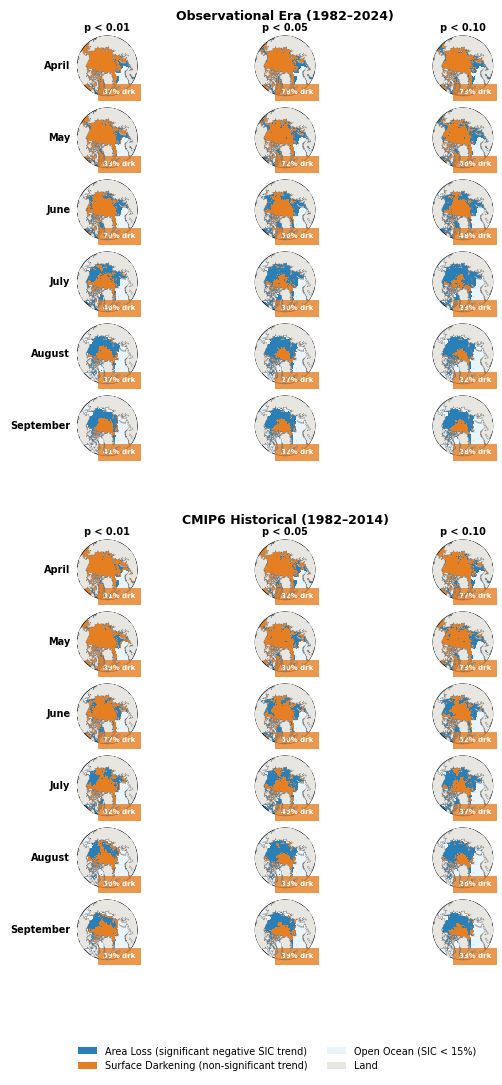

In [7]:
# %%
import pickle
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.path as mpath
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.gridspec import GridSpec

PKL_PATH = '/glade/work/jrotondo/ncc_paper/plots/plot_data_sic_trend_maps.pkl'
OUT_PATH = '/glade/work/jrotondo/ncc_paper/plots/extended_data_fig_unified_masks'

# ── load ──────────────────────────────────────────────────────────────
with open(PKL_PATH, 'rb') as fh:
    d = pickle.load(fh)

sig_maps        = d['sig_maps']
meta            = d['meta']
lons            = d['lons']
lats            = d['lats']
EXPERIMENTS     = d['EXPERIMENTS']
MONTHS          = d['MONTHS']
PVAL_THRESHOLDS = d['PVAL_THRESHOLDS']

# ── style ─────────────────────────────────────────────────────────────
mpl.rcParams.update({
    'font.family': 'sans-serif', 'font.sans-serif': ['Arial','Helvetica','DejaVu Sans'],
    'font.size': 7, 'axes.titlesize': 7, 'axes.labelsize': 7,
    'xtick.labelsize': 6, 'ytick.labelsize': 6, 'legend.fontsize': 7,
    'axes.linewidth': 0.5, 'pdf.fonttype': 42, 'ps.fonttype': 42,
})

# Updated colors: Blue for significant extent loss, Orange for darkening
COLOR_SIG    = '#2980b9'  # Deep Blue
COLOR_NONSIG = '#e67e22'  # Vibrant Orange
COLOR_OCEAN  = '#eaf4fb'
COLOR_LAND   = '#e8e6e1'

proj          = ccrs.NorthPolarStereo(central_longitude=-45)
data_crs      = ccrs.PlateCarree()
cmap_discrete = mcolors.ListedColormap([COLOR_NONSIG, COLOR_SIG])

def make_circle_boundary(ax, n=100):
    theta = np.linspace(0, 2 * np.pi, n)
    verts = np.vstack([np.sin(theta), np.cos(theta)]).T * 0.5 + 0.5
    ax.set_boundary(mpath.Path(verts), transform=ax.transAxes)

# ── layout ────────────────────────────────────────────────────────────
# 13 rows: 6 obs + 1 spacer + 6 cmip6

gs = GridSpec(13, 3, figure=plt.figure(figsize=(6.5, 12)))

fig = plt.gcf()

obs_axes   = np.array([[fig.add_subplot(gs[r,   c], projection=proj) for c in range(3)] for r in range(6)])
cmip6_axes = np.array([[fig.add_subplot(gs[r+7, c], projection=proj) for c in range(3)] for r in range(6)])
exp_axes   = [obs_axes, cmip6_axes]

# ── draw ──────────────────────────────────────────────────────────────
for exp_idx, (exp_name, exp_label, _) in enumerate(EXPERIMENTS):
    axes_block = exp_axes[exp_idx]

    axes_block[0, 1].text(0.5, 1.22, exp_label,
                          transform=axes_block[0, 1].transAxes,
                          ha='center', va='bottom', fontsize=9, fontweight='bold')

    for r_idx, mname in enumerate(MONTHS):
        for c_idx, pthresh in enumerate(PVAL_THRESHOLDS):
            ax  = axes_block[r_idx, c_idx]
            sig = sig_maps[(exp_name, mname, pthresh)]
            m   = meta[(exp_name, mname, pthresh)]

            ax.set_facecolor(COLOR_OCEAN)
            make_circle_boundary(ax)
            ax.set_extent([-180, 180, 60, 90], crs=data_crs)

            ax.pcolormesh(lons, lats, sig, transform=data_crs,
                          cmap=cmap_discrete, vmin=0, vmax=1,
                          shading='auto', zorder=2)
            ax.add_feature(cfeature.LAND, facecolor=COLOR_LAND, zorder=3)
            ax.add_feature(cfeature.COASTLINE, edgecolor='#777777',
                           linewidth=0.2, zorder=4)

            ax.text(0.97, 0.03, f"{m['pct_drk']:.0f}% drk",
                    transform=ax.transAxes, fontsize=5, ha='right',
                    color='white', fontweight='bold',
                    bbox=dict(facecolor=COLOR_NONSIG, alpha=0.8, lw=0))

            if c_idx == 0:
                ax.text(-0.12, 0.5, mname, transform=ax.transAxes,
                        fontsize=7, fontweight='bold',
                        va='center', ha='right', rotation=0)
            if r_idx == 0:
                ax.set_title(f'p < {pthresh:.2f}', fontsize=7,
                             fontweight='bold', pad=4)

# ── legend ────────────────────────────────────────────────────────────
legend_patches = [
    mpatches.Patch(facecolor=COLOR_SIG,    label='Area Loss (significant negative SIC trend)'),
    mpatches.Patch(facecolor=COLOR_NONSIG, label='Surface Darkening (non-significant trend)'),
    mpatches.Patch(facecolor=COLOR_OCEAN,  label='Open Ocean (SIC < 15%)'),
    mpatches.Patch(facecolor=COLOR_LAND,   label='Land'),
]
fig.legend(handles=legend_patches, loc='lower center', ncol=2, fontsize=7,
           frameon=False, bbox_to_anchor=(0.5, 0.01))

for ext in ('pdf', 'png'):
    fig.savefig(f'{OUT_PATH}.{ext}', dpi=300, bbox_inches='tight')
    print(f'Saved → {OUT_PATH}.{ext}')
plt.show()

## Extended Data Figure 9

Columns : ['rs_method', 'period', 'pval', 'SIAF_tot_arctic', 'SIAF_ext_arctic', 'SIAF_drk_arctic', 'SIAF_tot_global', 'SIAF_ext_global', 'SIAF_drk_global', 'sigma2_tot_global', 'sigma2_ext_global', 'sigma2_drk_global', 'ext_pct', 'drk_pct', 'IS_ext_per_area', 'IS_drk_per_area', 'RS_ext_per_area', 'RS_drk_per_area', 'SIAF_ext_per_area', 'SIAF_drk_per_area', 'sigma2_IS_ext_pa', 'sigma2_IS_drk_pa', 'sigma2_RS_ext_pa', 'sigma2_RS_drk_pa', 'sigma2_ext_per_area', 'sigma2_drk_per_area', 'IS_tot_arctic', 'IS_ext_arctic', 'IS_drk_arctic', 'RS_arctic', 'sigma2_IS_arctic', 'sigma2_IS_ext_arctic', 'sigma2_IS_drk_arctic', 'sigma2_RS_arctic']
Periods : ['CMIP6' 'Obs-era']
Methods : ['CERES' 'Kernel']
p-values: [np.float64(0.01), np.float64(0.05), np.float64(0.1)]
Saved → /glade/work/jrotondo/ncc_paper/plots/siaf_breakdown_8panel.pdf
Saved → /glade/work/jrotondo/ncc_paper/plots/siaf_breakdown_8panel.png


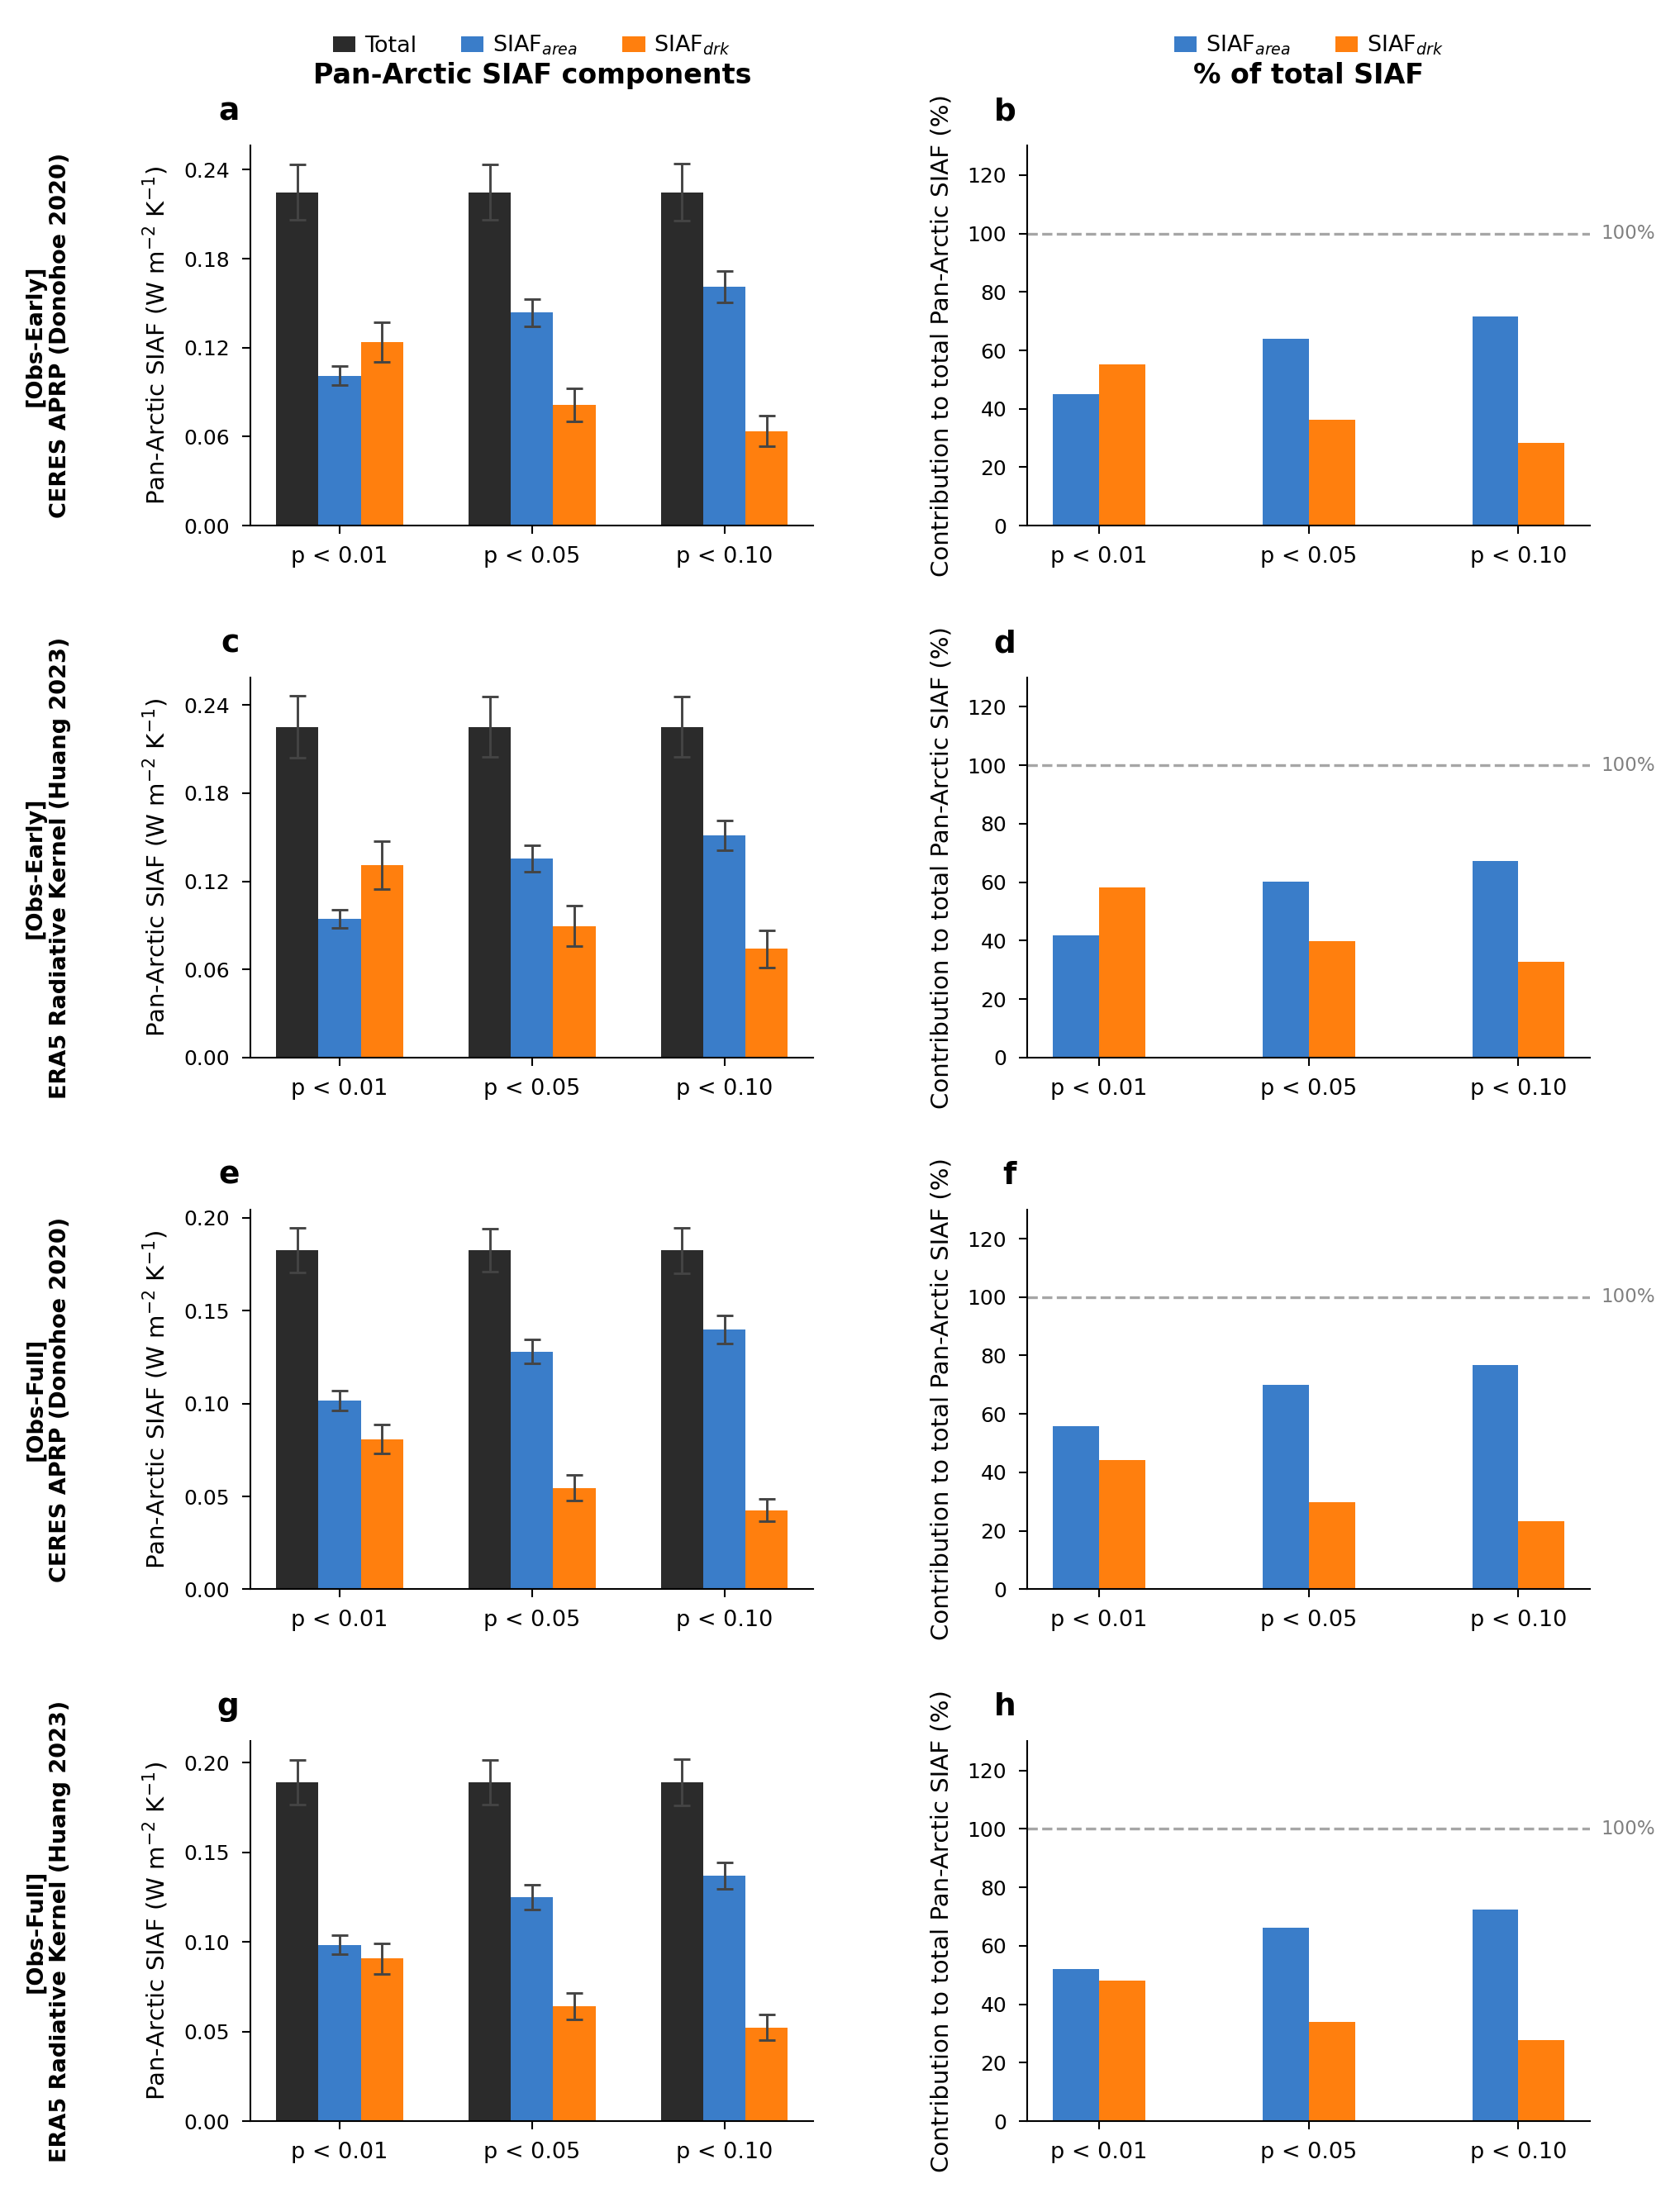

In [6]:
#!/usr/bin/env python
"""
plot_siaf_breakdown.py  —  Figure: SIAF component breakdown
============================================================
Left  panels (a,c,e,g): absolute SIAF values [Total, Extent, Darkening]
Right panels (b,d,f,h): % contribution to total SIAF

Source: siaf_pixelwise_summary.csv
"""

import os
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
import string

# ── paths ──────────────────────────────────────────────────────────────
CSV_PATH = '/glade/work/jrotondo/ncc_paper/plots/sensitivity/siaf_pixelwise_summary.csv'
OUT_DIR  = '/glade/work/jrotondo/ncc_paper/plots/'
os.makedirs(OUT_DIR, exist_ok=True)

# ── config ─────────────────────────────────────────────────────────────
ROWS = [
    ('CMIP6',   'CERES',  '[Obs-Early]\nCERES APRP (Donohoe 2020)'),
    ('CMIP6',   'Kernel', '[Obs-Early]\nERA5 Radiative Kernel (Huang 2023)'),
    ('Obs-era', 'CERES',  '[Obs-Full]\nCERES APRP (Donohoe 2020)'),
    ('Obs-era', 'Kernel', '[Obs-Full]\nERA5 Radiative Kernel (Huang 2023)'),
]
PVALS   = [0.01, 0.05, 0.10]
PLABELS = ['p < 0.01', 'p < 0.05', 'p < 0.10']

COL_TOT = '#2b2b2b'
COL_EXT = '#3A7DC9'
COL_DRK = '#ff7f0e'

BW = 0.22
X  = np.arange(len(PVALS))

# ── style ──────────────────────────────────────────────────────────────
mpl.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'Helvetica', 'DejaVu Sans'],
    'font.size': 7, 'axes.titlesize': 8, 'axes.labelsize': 7,
    'xtick.labelsize': 6.5, 'ytick.labelsize': 6,
    'legend.fontsize': 6.5,
    'axes.linewidth': 0.5,
    'xtick.major.width': 0.5, 'ytick.major.width': 0.5,
    'xtick.major.size': 2.5,  'ytick.major.size': 2.5,
    'xtick.direction': 'out', 'ytick.direction': 'out',
    'axes.spines.top': False, 'axes.spines.right': False,
    'pdf.fonttype': 42, 'ps.fonttype': 42,
})

# ── load ───────────────────────────────────────────────────────────────
df = pd.read_csv(CSV_PATH)
print("Columns :", df.columns.tolist())
print("Periods :", df['period'].unique())
print("Methods :", df['rs_method'].unique())
print("p-values:", sorted(df['pval'].unique()))

HAS_SIGMA_TOT = 'sigma2_tot_global' in df.columns
HAS_SIGMA_EXT = 'sigma2_ext_global' in df.columns
HAS_SIGMA_DRK = 'sigma2_drk_global' in df.columns

# ── figure ─────────────────────────────────────────────────────────────
fig = plt.figure(figsize=(183/25.4, 230/25.4), facecolor='white', dpi = 300)
gs  = GridSpec(4, 2, figure=fig,
               hspace=0.40, wspace=0.38,
               left=0.22, right=0.97, top=0.94, bottom=0.06)

letters = list(string.ascii_lowercase)
BAR_KW  = dict(linewidth=0, capsize=2.5,
               error_kw=dict(elinewidth=0.7, capthick=0.7, ecolor='#444444'))

LEG_KW = dict(frameon=False, handlelength=1.0,
              handletextpad=0.4, labelspacing=0.3)

for ri, (period, rs_method, row_label) in enumerate(ROWS):
    sub = df[(df['period'] == period) & (df['rs_method'] == rs_method)]

    tots, exts, drks = [], [], []
    e_tot, e_ext, e_drk = [], [], []

    for pv in PVALS:
        row = sub[np.isclose(sub['pval'], pv)]
        if row.empty:
            tots.append(np.nan); exts.append(np.nan); drks.append(np.nan)
            e_tot.append(np.nan); e_ext.append(np.nan); e_drk.append(np.nan)
        else:
            r = row.iloc[0]
            tots.append(r['SIAF_tot_global'])
            exts.append(r['SIAF_ext_global'])
            drks.append(r['SIAF_drk_global'])
            e_tot.append(r['sigma2_tot_global'] / 2 if HAS_SIGMA_TOT else np.nan)
            e_ext.append(r['sigma2_ext_global'] / 2 if HAS_SIGMA_EXT else np.nan)
            e_drk.append(r['sigma2_drk_global'] / 2 if HAS_SIGMA_DRK else np.nan)

    tots  = np.array(tots);  exts  = np.array(exts);  drks  = np.array(drks)
    e_tot = np.array(e_tot); e_ext = np.array(e_ext); e_drk = np.array(e_drk)

    # ── left panel: absolute values ────────────────────────────────────
    ax_l = fig.add_subplot(gs[ri, 0])

    ax_l.bar(X - BW, tots, BW, color=COL_TOT, label='Total',
             yerr=(e_tot if HAS_SIGMA_TOT else None), **BAR_KW)
    ax_l.bar(X,      exts, BW, color=COL_EXT, label=r'SIAF$_{area}$',
             yerr=(e_ext if HAS_SIGMA_EXT else None), **BAR_KW)
    ax_l.bar(X + BW, drks, BW, color=COL_DRK, label=r'SIAF$_{drk}$',
             yerr=(e_drk if HAS_SIGMA_DRK else None), **BAR_KW)

    ax_l.set_xticks(X)
    ax_l.set_xticklabels(PLABELS)
    ax_l.set_ylabel(r'Pan-Arctic SIAF (W m$^{-2}$ K$^{-1}$)', labelpad=4)
    ax_l.set_ylim(bottom=0)
    ax_l.yaxis.set_major_locator(mpl.ticker.MaxNLocator(5, min_n_ticks=4))

    # Row description label (further left than y-axis label)
    ax_l.text(-0.36, 0.5, row_label,
              transform=ax_l.transAxes,
              fontsize=6.5, va='center', ha='center',
              rotation=90, multialignment='center',
              fontweight='bold')

    # Panel letter
    ax_l.text(-0.02, 1.05, letters[ri * 2],
              transform=ax_l.transAxes,
              fontsize=9, fontweight='bold', va='bottom', ha='right')

    if ri == 0:
        # Legend placed horizontally above the bars, centred on the panel
        ax_l.legend(loc='lower center',
                    bbox_to_anchor=(0.5, 1.18),   # above the panel title
                    ncol=3, **LEG_KW)
        ax_l.set_title('Pan-Arctic SIAF components', fontsize=8, fontweight='bold', pad=18)

    # ── right panel: percentages ────────────────────────────────────────
    ax_r = fig.add_subplot(gs[ri, 1])

    with np.errstate(invalid='ignore'):
        pct_ext = 100 * exts / tots
        pct_drk = 100 * drks / tots

    ax_r.bar(X - BW/2, pct_ext, BW, color=COL_EXT, label=r'SIAF$_{area}$',    linewidth=0)
    ax_r.bar(X + BW/2, pct_drk, BW, color=COL_DRK, label=r'SIAF$_{drk}$', linewidth=0)

    ax_r.axhline(100, color='0.65', lw=0.8, ls='--', zorder=0)
    ax_r.text(1.02, 100, '100%',
              transform=ax_r.get_yaxis_transform(),
              fontsize=5.5, va='center', color='0.5')

    ax_r.set_xticks(X)
    ax_r.set_xticklabels(PLABELS)
    ax_r.set_ylabel('Contribution to total Pan-Arctic SIAF (%)', labelpad=4)
    ax_r.set_ylim(0, 130)
    ax_r.yaxis.set_major_locator(mpl.ticker.MultipleLocator(20))

    ax_r.text(-0.02, 1.05, letters[ri * 2 + 1],
              transform=ax_r.transAxes,
              fontsize=9, fontweight='bold', va='bottom', ha='right')

    if ri == 0:
        # Same treatment: legend above panel, centred
        ax_r.legend(loc='lower center',
                    bbox_to_anchor=(0.5, 1.18),
                    ncol=2, **LEG_KW)
        ax_r.set_title('% of total SIAF', fontsize=8, fontweight='bold', pad=18)

# ── save ───────────────────────────────────────────────────────────────
for ext in ('pdf', 'png'):
    out = os.path.join(OUT_DIR, f'siaf_breakdown_8panel.{ext}')
    fig.savefig(out, dpi=300, bbox_inches='tight')
    print(f'Saved → {out}')
plt.show()


# Extended Tables

## Extended Table 1

In [1]:
#!/usr/bin/env python
"""
compute_pdf_weights_table.py
────────────────────────────
Computes Tebaldi BMA weights for each qualifying CMIP6 model
(>= MIN_MEMBERS full_T07 members) for all three SIAF components.

OBS source : siaf_pixelwise_summary.csv  (new schema from siaf_obs_analysis.py)
CMIP6 source: siaf_cmip6_summary.csv

Outputs
  • printed LaTeX sidewaystable (paste into paper)
  • CSV for archiving
"""

import os
import numpy as np
import pandas as pd
import scipy.stats as stats

# ── Paths ─────────────────────────────────────────────────────────────────────
DIR_CMIP6_CSV = (
    '/glade/work/jrotondo/ncc_paper/plots/cmip6_pistone_only/'
    'siaf_cmip6_summary.csv'
)
DIR_OBS_CSV = (
    '/glade/work/jrotondo/ncc_paper/plots/sensitivity/'
    'siaf_pixelwise_summary.csv'
)
OUT_CSV = (
    '/glade/work/jrotondo/ncc_paper/plots/cmip6_pistone_only/'
    'siaf_tebaldi_weights.csv'
)

MIN_MEMBERS = 10   # for the table; pdf plot uses 3

# COMPONENTS: (cmip6_col, obs_tag)
COMPONENTS = [
    ('siaf_ext_global', 'ext'),
    ('siaf_drk_global', 'drk'),
    ('siaf_global',     'tot'),
]

# ── Load CMIP6 ────────────────────────────────────────────────────────────────
df = pd.read_csv(DIR_CMIP6_CSV)
df = df[df['rs_method'] == 'full_T07'].copy()
n_per  = df.groupby('model').size()
models = sorted(n_per[n_per >= MIN_MEMBERS].index.tolist())
df     = df[df['model'].isin(models)].copy()
print(f'{len(models)} models with >= {MIN_MEMBERS} members:')
for m in models:
    print(f'  {m}  (N={n_per[m]})')

# ── Load OBS — new schema ─────────────────────────────────────────────────────
df_obs = pd.read_csv(DIR_OBS_CSV)
match  = df_obs[
    (df_obs['rs_method'] == 'CERES') &
    (df_obs['period']    == 'CMIP6') &
    (np.isclose(df_obs['pval'], 0.05))
]
if match.empty:
    raise RuntimeError(
        'OBS row not found. '
        f'Available rs_method={df_obs["rs_method"].unique()} '
        f'period={df_obs["period"].unique()} '
        f'pval={sorted(df_obs["pval"].unique())}'
    )
r_obs = match.iloc[0]
obs = {
    'ext': (float(r_obs['SIAF_ext_global']),
            float(r_obs['sigma2_ext_global']) / 2.),   # sigma2 = 2σ → ÷2
    'drk': (float(r_obs['SIAF_drk_global']),
            float(r_obs['sigma2_drk_global']) / 2.),
    'tot': (float(r_obs['SIAF_tot_global']),
            float(r_obs['sigma2_tot_global']) / 2.),
}
print('\nOBS targets (mean ± 1σ):')
for tag, (mu, sig) in obs.items():
    print(f'  {tag}: {mu:.4f} ± {sig:.4f}')

# ── Compute Tebaldi BMA weights ───────────────────────────────────────────────
records = []

for col, tag in COMPONENTS:
    obs_mu, obs_sig = obs[tag]
    model_stats, raw_weights = [], []

    for m in models:
        sub   = df[df['model'] == m][col].dropna()
        mu_i  = float(sub.mean())
        sig_i = float(sub.std(ddof=1)) if len(sub) > 1 else 0.
        n_mem = len(sub)

        if sig_i <= 0 or not (np.isfinite(obs_mu) and np.isfinite(obs_sig)):
            raw_w = 0.
        else:
            combined_sig = np.sqrt(sig_i**2 + obs_sig**2)
            raw_w = float(stats.norm.pdf(obs_mu, loc=mu_i, scale=combined_sig))

        model_stats.append((m, mu_i, sig_i, n_mem, raw_w))
        raw_weights.append(raw_w)

    total_w = sum(raw_weights)
    for (m, mu_i, sig_i, n_mem, raw_w) in model_stats:
        norm_w = raw_w / total_w if total_w > 0 else np.nan
        records.append({
            'component':      tag,
            'model':          m,
            'n_members':      n_mem,
            'model_mean':     round(mu_i,  4),
            'model_sigma':    round(sig_i, 4),
            'tebaldi_weight': round(norm_w, 5),
        })

result_df = pd.DataFrame(records)
result_df.to_csv(OUT_CSV, index=False)
print(f'\nSaved weights CSV → {OUT_CSV}')

# ── Pivot: one row per model ──────────────────────────────────────────────────
pivot = result_df.pivot_table(
    index='model',
    columns='component',
    values=['n_members', 'model_mean', 'model_sigma', 'tebaldi_weight'],
    aggfunc='first',
).round(4)
pivot.columns = ['_'.join(c) for c in pivot.columns]
pivot = pivot.reset_index()
pivot = pivot.sort_values('tebaldi_weight_tot', ascending=False)

# ── Formatting helpers ────────────────────────────────────────────────────────
def fmt(val, d=3):
    return r'\textemdash' if pd.isna(val) else f'{val:.{d}f}'

def fmt_w(val):
    return r'---' if pd.isna(val) else f'{val*100:.1f}\\%'

# ── LaTeX sidewaystable ───────────────────────────────────────────────────────
print('\n' + '=' * 80)
print('LaTeX SIDEWAYSTABLE')
print('=' * 80 + '\n')

lines = []
lines += [
    r'\begin{sidewaystable}[htbp]',
    r'\centering',
    r'\scriptsize',
    r'\caption{\textbf{Tebaldi BMA weights and model statistics for the CMIP6',
    r'    SIAF ensemble PDF comparison.}',
    r'    Each row shows one CMIP6 model with $\geq ' + str(MIN_MEMBERS) + r'$ full-T07 ensemble members.',
    r'    $\mu_i$ and $\sigma_i$ are the ensemble mean and standard deviation',
    r'    for each component (W\,m$^{-2}$\,K$^{-1}$); $w_i^{\mathrm{BMA}}$ is',
    r'    the normalised Bayesian Model Averaging weight',
    r'    \citep{Tebaldi2007UseCMIP} measuring how consistent the model',
    r'    distribution is with the observational target',
    r'    (Eq.~\ref{eq:tebaldi_weight}). Models are sorted by descending',
    r'    total $w_i^{\mathrm{BMA}}$.}',
    r'\label{tab:tebaldi_weights}',
    r'\begin{tabular}{l r  r r r  r r r  r r r}',
    r'\toprule',
    r'& & \multicolumn{3}{c}{Extent ($\mathrm{SIAF}_{\mathrm{ext}}$)}',
    r'  & \multicolumn{3}{c}{Darkening ($\mathrm{SIAF}_{\mathrm{drk}}$)}',
    r'  & \multicolumn{3}{c}{Total ($\mathrm{SIAF}_{\mathrm{tot}}$)} \\',
    r'\cmidrule(lr){3-5}\cmidrule(lr){6-8}\cmidrule(lr){9-11}',
    r'Model & $N$',
    r'  & $\mu_i$ & $\sigma_i$ & $w_i^{\mathrm{BMA}}$',
    r'  & $\mu_i$ & $\sigma_i$ & $w_i^{\mathrm{BMA}}$',
    r'  & $\mu_i$ & $\sigma_i$ & $w_i^{\mathrm{BMA}}$ \\',
    r'\midrule',
]

for _, row in pivot.iterrows():
    model = row['model'].replace('_', r'\_')
    n_mem = int(row.get('n_members_tot',
                row.get('n_members_ext',
                row.get('n_members_drk', 0))))
    parts = [f'{model} & {n_mem}']
    for tag in ['ext', 'drk', 'tot']:
        mu  = fmt(row.get(f'model_mean_{tag}',    np.nan))
        sig = fmt(row.get(f'model_sigma_{tag}',   np.nan))
        w   = fmt_w(row.get(f'tebaldi_weight_{tag}', np.nan))
        parts.append(f'{mu} & {sig} & {w}')
    lines.append(' & '.join(parts) + r' \\')

lines.append(r'\midrule')

# OBS footer row
obs_parts = [r'\textbf{OBS target} & ---']
for tag in ['ext', 'drk', 'tot']:
    mu_o, sig_o = obs[tag]
    obs_parts.append(
        f'\\textbf{{{mu_o:.3f}}} & \\textbf{{{sig_o:.3f}}} & ---'
    )
lines.append(' & '.join(obs_parts) + r' \\')

lines += [
    r'\bottomrule',
    r'\end{tabular}',
    r'\end{sidewaystable}',
]

print('\n'.join(lines))


11 models with >= 10 members:
  ACCESS-ESM1-5  (N=10)
  CESM2  (N=11)
  CNRM-CM6-1  (N=11)
  CanESM5  (N=27)
  GISS-E2-1-H  (N=10)
  INM-CM5-0  (N=10)
  IPSL-CM6A-LR  (N=33)
  MIROC6  (N=42)
  MPI-ESM1-2-HR  (N=10)
  MPI-ESM1-2-LR  (N=51)
  UKESM1-0-LL  (N=15)

OBS targets (mean ± 1σ):
  ext: 0.1435 ± 0.0091
  drk: 0.0812 ± 0.0111
  tot: 0.2248 ± 0.0185

Saved weights CSV → /glade/work/jrotondo/ncc_paper/plots/cmip6_pistone_only/siaf_tebaldi_weights.csv

LaTeX SIDEWAYSTABLE

\begin{sidewaystable}[htbp]
\centering
\scriptsize
\caption{\textbf{Tebaldi BMA weights and model statistics for the CMIP6
    SIAF ensemble PDF comparison.}
    Each row shows one CMIP6 model with $\geq 10$ full-T07 ensemble members.
    $\mu_i$ and $\sigma_i$ are the ensemble mean and standard deviation
    for each component (W\,m$^{-2}$\,K$^{-1}$); $w_i^{\mathrm{BMA}}$ is
    the normalised Bayesian Model Averaging weight
    \citep{Tebaldi2007UseCMIP} measuring how consistent the model
    distribution is with

# Extra Plots (Interesting for more context)

## Changing slope of $\frac{d\alpha}{dt}$

In [3]:
#!/usr/bin/env python
# jupytext ---
# text_representation:
#   extension: .py
#   format_name: percent
# ---

# %% [markdown]
# # dα/dT Evolution  —  plotting script
#
# Loads pre-computed results from `compute_dalpha_dt_evolution.py` and
# produces a 3-panel figure:
#
# * **(a)** Albedo vs global ΔT scatter, coloured by year, full-period OLS line
# * **(b)** Expanding-window slope vs end year  (start fixed at 1982)
# * **(c)** Rolling-window slope vs window centre year
#
# Run `compute_dalpha_dt_evolution.py` first to generate the pickle.

# %% — imports & config
import pickle
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
from matplotlib.lines import Line2D

PKL_PATH = '/glade/work/jrotondo/ncc_paper/plots/sensitivity/dalpha_dt_evolution.pkl'
PLOT_OUT  = '/glade/work/jrotondo/ncc_paper/plots/sensitivity/dalpha_dt_evolution.png'

# ── style constants ─────────────────────────────────────────────────────────────
FS        = 12
COL_EXP   = '#2c7bb6'    # expanding window
COL_ROLL  = '#c0392b'    # rolling window
COL_FULL  = '#333333'    # full-period reference line
ALPHA_SHD = 0.18
P_THRESH  = 0.05

plt.rcParams.update({'font.size': FS, 'axes.linewidth': 1.1})

# %% — load pickle
print(f'Loading {PKL_PATH} ...')
with open(PKL_PATH, 'rb') as fh:
    d = pickle.load(fh)

yr_arr           = d['yr_arr']
alb_arr          = d['alb_arr']
T_arr            = d['T_arr']
monthly_arr      = d['monthly_arr']
T_sources        = d['T_sources']
full_slope       = d['full_slope']
full_ic          = d['full_ic']
full_r           = d['full_r']
full_p           = d['full_p']
full_se          = d['full_se']
exp_end_years    = d['exp_end_years']
exp_slopes       = d['exp_slopes']
exp_se           = d['exp_se']
exp_pvals        = d['exp_pvals']
exp_r            = d['exp_r']
ROLL_WIN         = int(d['roll_win'])
roll_centres     = d['roll_centres']
roll_start_years = d['roll_start_years']
roll_end_years   = d['roll_end_years']
roll_slopes      = d['roll_slopes']
roll_se          = d['roll_se']
roll_pvals       = d['roll_pvals']
roll_r           = d['roll_r']

print(f'  {len(yr_arr)} years  ({yr_arr[0]}–{yr_arr[-1]})')
print(f'  T ensemble sources: {T_sources}')

# %% — console summary
accel = roll_slopes[-1] - roll_slopes[0]
print('\n=== SLOPE EVOLUTION SUMMARY ===')
print(f'Full period ({yr_arr[0]}–{yr_arr[-1]}):')
print(f'  slope = {full_slope:.5f} ± {2*full_se:.5f}  (±2σ OLS SE) '
      f' r={full_r:.3f}  p={full_p:.4f}')
print(f'\nEarly {ROLL_WIN}-yr window ({roll_start_years[0]}–{roll_end_years[0]}):')
print(f'  slope = {roll_slopes[0]:.5f} ± {2*roll_se[0]:.5f}  (±2σ)')
print(f'Late  {ROLL_WIN}-yr window ({roll_start_years[-1]}–{roll_end_years[-1]}):')
print(f'  slope = {roll_slopes[-1]:.5f} ± {2*roll_se[-1]:.5f}  (±2σ)')
print(f'\nAcceleration (late − early): {accel:+.5f} albedo K⁻¹  '
      f'({"strengthening" if accel < 0 else "weakening"})')

# %% — build figure
fig, axes = plt.subplots(1, 3, figsize=(17, 5.4), dpi=150,
                          gridspec_kw={'wspace': 0.32})
fig.patch.set_facecolor('#FAFAFA')
for ax in axes:
    ax.set_facecolor('#FAFAFA')

# ─────────────────────────────────────────────────────────────────────────────
# Panel (a): albedo vs T scatter, coloured by year
# ─────────────────────────────────────────────────────────────────────────────
ax = axes[0]
norm = mcolors.Normalize(vmin=yr_arr[0], vmax=yr_arr[-1])
sc   = ax.scatter(T_arr, alb_arr, c=yr_arr,
                  cmap='plasma_r', norm=norm,
                  s=60, zorder=3, edgecolors='white', linewidths=0.5)

# full-period OLS line
T_line   = np.linspace(T_arr.min() - 0.04, T_arr.max() + 0.04, 200)
alb_line = full_ic + full_slope * T_line
ax.plot(T_line, alb_line, color=COL_FULL, lw=2.2, zorder=4,
        label=(f'Full-period OLS\nslope = {full_slope:.4f} albedo K⁻¹\n'
               f'r = {full_r:.2f},  p = {full_p:.3f}'))

cb = fig.colorbar(sc, ax=ax, pad=0.02, aspect=28)
cb.set_label('Year', fontsize=FS - 1)
cb.ax.tick_params(labelsize=FS - 2)
cb.set_ticks([yr_arr[0], 1990, 2000, 2010, yr_arr[-1]])

ax.set_xlabel('Global mean ΔT  (K)', fontsize=FS)
ax.set_ylabel('Arctic AMJJAS albedo  (−)', fontsize=FS)
ax.tick_params(labelsize=FS - 1)
ax.legend(fontsize=FS - 2, loc='upper right', framealpha=0.88)
ax.set_title('(a) Albedo vs Temperature', fontsize=FS, fontweight='bold')
for sp in ['top', 'right']:
    ax.spines[sp].set_visible(False)
ax.yaxis.grid(True, alpha=0.30, lw=0.7)
ax.xaxis.grid(True, alpha=0.30, lw=0.7)

# ─────────────────────────────────────────────────────────────────────────────
# Panel (b): expanding-window slope vs end year
# ─────────────────────────────────────────────────────────────────────────────
ax = axes[1]
sig_exp = exp_pvals < P_THRESH

ax.fill_between(exp_end_years,
                exp_slopes - 2. * exp_se,
                exp_slopes + 2. * exp_se,
                color=COL_EXP, alpha=ALPHA_SHD, linewidth=0, zorder=1,
                label='±2σ (OLS SE)')
ax.plot(exp_end_years, exp_slopes, color=COL_EXP, lw=2.0, zorder=2)

ax.scatter(exp_end_years[sig_exp],  exp_slopes[sig_exp],
           color=COL_EXP, s=48, zorder=3, edgecolors='white', linewidths=0.5,
           label=f'p < {P_THRESH}')
ax.scatter(exp_end_years[~sig_exp], exp_slopes[~sig_exp],
           facecolors='none', edgecolors=COL_EXP, s=48, zorder=3, linewidths=1.2,
           label=f'p ≥ {P_THRESH}')

ax.axhline(full_slope, color=COL_FULL, lw=1.4, ls='--', alpha=0.70, zorder=2,
           label=f'Full-period slope ({full_slope:.4f})')
ax.axhline(0., color='#666666', lw=0.8, ls=':', zorder=1)

ax.set_xlabel(f'End year  (start = {yr_arr[0]})', fontsize=FS)
ax.set_ylabel('dα/dT  (albedo K⁻¹)', fontsize=FS)
ax.tick_params(labelsize=FS - 1)
ax.legend(fontsize=FS - 2, loc='lower left', framealpha=0.88)
ax.set_title(f'(b) Expanding window  ({yr_arr[0]} → end year)',
             fontsize=FS, fontweight='bold')
for sp in ['top', 'right']:
    ax.spines[sp].set_visible(False)
ax.yaxis.grid(True, alpha=0.30, lw=0.7)
ax.set_xlim(exp_end_years[0] - 0.8, exp_end_years[-1] + 0.8)

n_start = exp_end_years[0] - yr_arr[0] + 1
n_end   = exp_end_years[-1] - yr_arr[0] + 1
ax.text(0.02, 0.97,
        f'Window grows {n_start}→{n_end} years',
        transform=ax.transAxes, fontsize=FS - 3,
        va='top', color='#555555', style='italic')

# ─────────────────────────────────────────────────────────────────────────────
# Panel (c): rolling-window slope vs window centre year
# ─────────────────────────────────────────────────────────────────────────────
ax = axes[2]
sig_roll = roll_pvals < P_THRESH

ax.fill_between(roll_centres,
                roll_slopes - 2. * roll_se,
                roll_slopes + 2. * roll_se,
                color=COL_ROLL, alpha=ALPHA_SHD, linewidth=0, zorder=1,
                label='±2σ (OLS SE)')
ax.plot(roll_centres, roll_slopes, color=COL_ROLL, lw=2.0, zorder=2)

ax.scatter(roll_centres[sig_roll],  roll_slopes[sig_roll],
           color=COL_ROLL, s=48, zorder=3, edgecolors='white', linewidths=0.5,
           label=f'p < {P_THRESH}')
ax.scatter(roll_centres[~sig_roll], roll_slopes[~sig_roll],
           facecolors='none', edgecolors=COL_ROLL, s=48, zorder=3, linewidths=1.2,
           label=f'p ≥ {P_THRESH}')

ax.axhline(full_slope, color=COL_FULL, lw=1.4, ls='--', alpha=0.70, zorder=2,
           label=f'Full-period slope ({full_slope:.4f})')
ax.axhline(0., color='#666666', lw=0.8, ls=':', zorder=1)

ax.set_xlabel('Window center year', fontsize=FS)
ax.set_ylabel('dα/dT  (albedo K⁻¹)', fontsize=FS)
ax.tick_params(labelsize=FS - 1)
ax.legend(fontsize=FS - 2, loc='lower left', framealpha=0.88)
ax.set_title(f'(c) {ROLL_WIN}-year rolling window',
             fontsize=FS, fontweight='bold')
for sp in ['top', 'right']:
    ax.spines[sp].set_visible(False)
ax.yaxis.grid(True, alpha=0.30, lw=0.7)
ax.set_xlim(roll_centres[0] - 0.8, roll_centres[-1] + 0.8)

# annotate first and last windows
def _ann(ax, xc, yc, label, xoff, yoff, col):
    ax.annotate(label,
                xy=(xc, yc),
                xytext=(xc + xoff, yc + yoff),
                fontsize=FS - 3, color=col,
                arrowprops=dict(arrowstyle='->', color=col, lw=1.0))

_ann(ax,
     roll_centres[0],  roll_slopes[0],
     f'{roll_start_years[0]}–{roll_end_years[0]}\n{roll_slopes[0]:+.4f} K⁻¹',
     +1.5, +0.0012, COL_ROLL)
_ann(ax,
     roll_centres[-1], roll_slopes[-1],
     f'{roll_start_years[-1]}–{roll_end_years[-1]}\n{roll_slopes[-1]:+.4f} K⁻¹',
     -7.0, +0.0012, COL_ROLL)

# ─────────────────────────────────────────────────────────────────────────────
# Shared supertitle
# ─────────────────────────────────────────────────────────────────────────────
fig.suptitle(
    f'Evolution of Arctic AMJJAS dα/dT  '
    f'(T ensemble: {", ".join(T_sources)})',
    fontsize=FS, y=1.02, fontweight='bold'
)

plt.tight_layout()
plt.savefig(PLOT_OUT, dpi=150, bbox_inches='tight',
            facecolor=fig.get_facecolor())
plt.close()
print(f'\nFigure saved → {PLOT_OUT}')

# %% — per-month full-period slope breakdown (console)
print('\n=== PER-MONTH FULL-PERIOD SLOPES (dα/dT) ===')
from scipy import stats as _stats
for mname, md in monthly_arr.items():
    if len(md['T']) < 5:
        continue
    res = _stats.linregress(md['T'], md['alb'])
    stars = ('***' if res.pvalue < 0.001 else
             '**'  if res.pvalue < 0.01  else
             '*'   if res.pvalue < 0.05  else '')
    print(f'  {mname:<12}: slope = {res.slope:+.5f}  '
          f'r = {res.rvalue:.3f}  p = {res.pvalue:.4f}  {stars}')


Loading /glade/work/jrotondo/ncc_paper/plots/sensitivity/dalpha_dt_evolution.pkl ...
  43 years  (1982–2024)
  T ensemble sources: ['GISTEMP', 'CowtanWay', 'NCEP', 'ERA5']

=== SLOPE EVOLUTION SUMMARY ===
Full period (1982–2024):
  slope = -0.06717 ± 0.01412  (±2σ OLS SE)  r=-0.830  p=0.0000

Early 15-yr window (1982–1996):
  slope = -0.04051 ± 0.05209  (±2σ)
Late  15-yr window (2010–2024):
  slope = -0.00151 ± 0.03397  (±2σ)

Acceleration (late − early): +0.03900 albedo K⁻¹  (weakening)


/glade/derecho/scratch/jrotondo/tmp/ipykernel_89005/912497174.py:229: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()



Figure saved → /glade/work/jrotondo/ncc_paper/plots/sensitivity/dalpha_dt_evolution.png

=== PER-MONTH FULL-PERIOD SLOPES (dα/dT) ===
  April       : slope = -0.02501  r = -0.460  p = 0.0019  **
  May         : slope = -0.05063  r = -0.726  p = 0.0000  ***
  June        : slope = -0.07854  r = -0.785  p = 0.0000  ***
  July        : slope = -0.07492  r = -0.802  p = 0.0000  ***
  August      : slope = -0.08272  r = -0.836  p = 0.0000  ***
  September   : slope = -0.09119  r = -0.820  p = 0.0000  ***
